# Where Is MH370? Turning Seven Circles Into a Probability Map

*A Monte Carlo investigation · Mathematics of Modern ML (MSc) · group project*

On 7 March 2014 at 16:42 UTC, Malaysia Airlines flight MH370, a Boeing 777 with 239 people on board, took off from Kuala Lumpur for Beijing. Thirty-nine minutes later its transponder went silent. Military radar followed it back across the Malay Peninsula and up the Strait of Malacca until 18:22 UTC. Then nothing, except seven automatic "handshakes" between the aircraft and an Inmarsat satellite over the Indian Ocean, the last one at 00:19 UTC. The aircraft has never been found [4, 7].

Each handshake carries a single number, a time delay, and that number places the aircraft somewhere on a circle on the Earth. This notebook turns those seven circles into a probability map of where the flight ended, using Monte Carlo methods written by hand.

**Three questions guide the investigation.**

1. **Where?** Which stretch of the final (7th) arc is the most probable?
2. **How sure?** How large are the credible regions, and how much of the uncertainty comes from the computer (Monte Carlo error) rather than from the problem itself?
3. **How fragile?** How far does the answer move when our assumptions change?

**How to read this notebook.** The investigation advances ping by ping. Each time it hits an obstacle, we introduce the method that removes it, derive it in a few lines, and immediately check the derivation numerically: *proved, then observed*. Only NumPy and SciPy do mathematics; every Monte Carlo brick is written out in the cells. Four reading aids run through the notebook: every investigation chapter (Ping 1 through Epilogue B, plus section 2.3) opens with an **In plain words** summary free of symbols, every experiment is followed by a **What we actually ran** card printed by the code, section 0.3 lists every modelling assumption with its measured effect on the answer, and section 0.6 draws the whole method on one figure, followed by the notation.

## Prologue — The case

| Time (UTC) | What happened [7] |
|---|---|
| 16:42 | Take-off from Kuala Lumpur, bound for Beijing |
| 17:07 | Last ACARS message from the aircraft |
| 17:19 | Last voice contact: *"Good night Malaysian Three Seven Zero"* |
| 17:21 | Transponder lost near waypoint IGARI, over the South China Sea |
| 18:22 | Last primary radar contact, north of Sumatra |
| 18:25 to 00:11 | Six handshakes with the Inmarsat-3F1 satellite |
| 00:19 | Seventh handshake: the satellite terminal logs on again, probably after fuel exhaustion |
| 01:15 | The aircraft no longer answers the ground station |

**What we have.** For each handshake $k$, a time $t_k$ and a *burst timing offset* $z_k$, the delay of the aircraft's reply in microseconds. **What we want.** The aircraft's state $x_k$ (position, heading, speed) at each handshake, and above all its position at 00:19, where it crossed the 7th arc for the last time.

**The method in one line.** Bayes' rule over whole flight paths. The *prior* says how aircraft fly, the *likelihood* says how well a path fits the seven delays, and the *posterior* says where the aircraft probably went:

$$
\underbrace{p(x_{0:7} \mid z_{1:7})}_{\text{posterior}} \;\propto\; \underbrace{p(x_0) \prod_{k=1}^{7} p(x_k \mid x_{k-1})}_{\text{prior}} \; \underbrace{\prod_{k=1}^{7} p(z_k \mid x_k)}_{\text{likelihood}} .
$$

No formula gives this posterior in closed form, so we represent it by a cloud of weighted simulated flights: Monte Carlo. Section 0.7 shows which Monte Carlo average answers each question. The roadmap:

| Part | Chapter | The obstacle | The tool it forces on us |
|---|---|---|---|
| **I. From circles to samples** | Ping 1 — A ping is a circle | A delay is not a position | Measurement model, likelihood, Bayes' rule, the Monte Carlo estimator and its CLT |
| | Ping 2 — Simulate flights | We need a prior over whole flight paths | A stochastic motion model; rejection sampling and its collapse; random-walk Metropolis |
| **II. Making Monte Carlo work** | Ping 3 — Weigh, don't discard | Rejection throws away almost everything | Importance sampling, the self-normalised estimator |
| | Ping 4 — The weights collapse | A handful of flights carry all the weight | Weight degeneracy, effective sample size |
| | Ping 5 — Resample | The effort must be redistributed | Resampling, the SIR particle filter |
| | Interlude — Trust, but verify | Can we believe the filter? | Calibration on synthetic flights with a known truth |
| **III. The answer and its fragility** | Ping 6 — The cloud moves south | Run it on the real data | Sequential filtering, ping by ping |
| | Ping 7 — The final arc | Where should ships search? | Probability map, credible regions, Monte Carlo error versus uncertainty |
| | Epilogue A — How fragile? | What if our assumptions are wrong? | Sensitivity analysis, model evidence |
| | Epilogue B — Reality check | What did the real search find? | Comparison with the searches, limits of the model |

---

## Chapter 0 — Toolkit

Everything the investigation needs is defined once, here: the libraries, the sourced data, the default assumptions and the shared visual style. Later chapters only *use* these names, so changing an assumption in one place changes it everywhere. The chapter ends with the scene as it stood at 18:22 UTC and with the whole method on one figure, followed by the notation (section 0.6), and with the Monte Carlo average behind every answer (section 0.7).

### 0.1 Libraries and reproducibility

Only NumPy and SciPy do mathematics in this notebook; every Monte Carlo brick (propagation, likelihood, weights, effective sample size, resampling, the filter itself) is written by hand in the chapters that need it. Each experiment draws from its own seeded random stream, so re-running one cell never changes the numbers of another. Each experiment is also followed by a **"What we actually ran"** card, printed by the code from the constants and results themselves, so that it cannot drift from what was computed: what was simulated, how many times, with which settings and random streams, how long it took and what came out.

In [1]:
import time
from dataclasses import dataclass, replace

import numpy as np
from scipy.special import gammaln
from scipy.stats import chi2

SEED = 370  # one seed for the whole investigation


def make_rng(*stream: int) -> np.random.Generator:
    """Independent, reproducible random stream labelled by integers, derived from SEED."""
    return np.random.default_rng([SEED, *stream])

In [2]:
import textwrap

CARD_ROWS = ("Simulated", "Size", "Settings", "Run time", "Result")
CARD_WIDTH = 96  # characters per printed line of a card


def print_card(title, simulated, size, settings, seconds, result):
    """Print the 'What we actually ran' card of an experiment: the same five rows everywhere."""
    print(f"What we actually ran · {title}\n{'─' * CARD_WIDTH}")
    texts = (simulated, size, settings, f"{seconds:.2f} s", result)
    for row, text in zip(CARD_ROWS, texts, strict=True):
        for i, line in enumerate(textwrap.wrap(text, CARD_WIDTH - 12)):
            print(f"{row if i == 0 else '':12s}{line}")

### 0.2 Data

**Physical constants.** Distances are in kilometres, times in hours or microseconds (µs), angles in degrees, speeds in knots (nautical miles per hour, the aviation unit).

In [3]:
C_KM_PER_US = 299_792.458e-6  # speed of light, km per microsecond
WGS84_A_KM = 6378.137  # WGS-84 equatorial radius
WGS84_F = 1 / 298.257223563  # WGS-84 flattening
WGS84_E2 = WGS84_F * (2 - WGS84_F)  # WGS-84 first eccentricity squared
EARTH_RADIUS_KM = 6371.0088  # mean Earth radius, used by the motion model (great circles)
KNOT_KMH = 1.852  # one knot in km/h
FOOT_KM = 0.3048e-3  # one foot in km

**The data.** Every number below comes from the primary sources listed in the References: the Inmarsat signalling-unit logs [8], Ashton et al. [1], the ATSB search-area report [2], Davey et al. [5] and the Malaysian safety investigation report [7]. Two details matter:

- Handshakes 1 and 7 are *log-on requests* sent on a different channel. Their raw BTOs carry a fixed extra delay of 4,600 µs, which Inmarsat subtracts [1, 5], and they are noisier: $\sigma = 62$ µs instead of 29 µs [5].
- Timestamps are the aircraft burst times from the logs, and the satellite positions are the ATSB ephemeris [2] propagated to those exact instants.

In [4]:
# Last primary radar contact (Malaysian report [7], sec. 1.1.3): 10 NM past waypoint MEKAR.
RADAR_FIX_TIME = np.datetime64("2014-03-07T18:22:12")
RADAR_FIX_LAT_DEG, RADAR_FIX_LON_DEG = 6.5777, 96.3409
MEKAR_LAT_DEG, MEKAR_LON_DEG = 6.5039, 96.4911  # previous waypoint on N571 [7]
LIDO_FIX_LAT_DEG, LIDO_FIX_LON_DEG = 6.8711, 97.3540  # conflicting fix from a 2014 briefing slide
IGARI_LAT_DEG, IGARI_LON_DEG = 6.9361, 103.5850  # waypoint where the transponder went silent [7]
SAT_NOMINAL_LON_DEG = 64.5  # nominal longitude of the Inmarsat-3F1 sub-satellite point [1]

# The seven handshakes: SU-log burst times [8], BTO after the log-on correction [1], noise sd [5].
PING_TIMES = np.array(
    [
        "2014-03-07T18:25:27.421",
        "2014-03-07T19:41:02.906",
        "2014-03-07T20:41:04.904",
        "2014-03-07T21:41:26.905",
        "2014-03-07T22:41:21.906",
        "2014-03-08T00:10:59.928",
        "2014-03-08T00:19:29.416",
    ],
    dtype="datetime64[ms]",
)
PING_BTO_RAW_US = np.array([17_120, 11_500, 11_740, 12_780, 14_540, 18_040, 23_000], dtype=float)
LOGON_OFFSET_US = 4_600.0  # extra delay of the two log-on requests (handshakes 1 and 7) [1]
IS_LOGON = np.array([True, False, False, False, False, False, True])
PING_BTO_US = PING_BTO_RAW_US - LOGON_OFFSET_US * IS_LOGON
PING_BTO_SD_US = np.where(IS_LOGON, 62.0, 29.0)
BTO_BIAS_US = -495_679.0  # mean of 17 calibration measurements at Kuala Lumpur [1]

# Inmarsat-3F1 position (ECEF, km) at each handshake: ATSB ephemeris [2] at the burst times.
SAT_ECEF_KM = np.array(
    [
        [18_136.752, 38_071.768, 1_149.238],
        [18_145.219, 38_066.942, 1_206.207],
        [18_152.230, 38_063.950, 1_158.128],
        [18_159.684, 38_061.234, 1_029.862],
        [18_167.373, 38_058.221, 832.014],
        [18_177.596, 38_051.609, 435.093],
        [18_178.354, 38_050.848, 393.045],
    ]
)

# Perth ground earth station (Gnangara) and the assumed altitude after the radar fix.
GES_LAT_DEG, GES_LON_DEG, GES_ALT_KM = -31.8025, 115.8852, 0.0
CRUISE_ALT_KM = 35_000 * FOOT_KM

# Pre-flight calibration at the Kuala Lumpur gate [1, table 3]: 7 BTO values near 16:00 UTC.
KLIA_GATE_LAT_DEG, KLIA_GATE_LON_DEG, KLIA_GATE_ALT_KM = 2.747, 101.712, 0.021
KLIA_BTO_US = np.array([14_820, 14_740, 14_780, 14_820, 14_740, 14_820, 14_820], dtype=float)
SAT_ECEF_1600_KM = np.array([18_118.9, 38_081.8, 706.6])  # z UNVERIFIED (harmonic fit, see Ping 1)

N_PINGS = len(PING_TIMES)
T_PING_H = (PING_TIMES - RADAR_FIX_TIME) / np.timedelta64(1, "h")  # hours after the radar fix


def hhmm(t):
    """UTC time rounded to the nearest minute, as 'HH:MM'."""
    return str((t + np.timedelta64(30, "s")).astype("datetime64[m]"))[11:16]


PHONE_CALL_UTC = np.datetime64("2014-03-07T18:39:52")  # first unanswered satellite phone call [7]

print("ping  time (UTC)     BTO (µs)  sigma (µs)  hours after radar fix")
for k in range(N_PINGS):
    hhmmss = str(PING_TIMES[k])[11:19]
    print(
        f"{k + 1:4d}  {hhmmss}  {PING_BTO_US[k]:10,.0f}  {PING_BTO_SD_US[k]:10.0f}"
        f"  {T_PING_H[k]:10.2f}"
    )

ping  time (UTC)     BTO (µs)  sigma (µs)  hours after radar fix
   1  18:25:27      12,520          62        0.05
   2  19:41:02      11,500          29        1.31
   3  20:41:04      11,740          29        2.31
   4  21:41:26      12,780          29        3.32
   5  22:41:21      14,540          29        4.32
   6  00:10:59      18,040          29        5.81
   7  00:19:29      18,400          62        5.95


**What the real search did.** Epilogue B compares our answer with the official searches, all strips along the 7th arc [2, 3, 4, 7], the peak of the Australian Defence Science and Technology Group (DSTG) posterior [5], and the debris that washed ashore [7]. The exact polygons of the search areas are not published in the sources we used, so we rebuild them as strips of the documented width along our own 7th arc; the DSTG peak longitude is likewise taken on our arc (UNVERIFIED as a published value).

In [5]:
SEARCH_AREAS = {  # name: (southern latitude, northern latitude, half-width km, area km²) [3, 4, 7]
    "ATSB underwater search 2014-17": (-39.3, -33.0, 40.0, 120_000),
    "First Principles Review area": (-36.0, -33.0, 46.3, 25_000),
    "Ocean Infinity search 2018": (-36.0, -25.0, None, 112_000),  # width not published
}
DSTG_PEAK_LAT_DEG = -38.2  # peak of the DSTG posterior along the 7th arc [5]
DEBRIS_FINDS = [  # (part, place, latitude, longitude): Malaysian report, table 1.12A [7]
    ("Right flaperon (confirmed)", "Reunion", -20.96, 55.65),
    ("Left outboard flap (confirmed)", "Mauritius", -20.0333, 57.70),
    ("Right outboard flap (confirmed)", "Pemba Island, Tanzania", -5.20, 39.7333),
    ("Flap support fairing", "Mozambique", -24.32, 35.31),
    ("Horizontal stabiliser panel", "Mozambique", -22.00, 35.31),
    ("Engine nose cowl", "South Africa", -34.183, 22.146),
    ("Door stowage closet panel", "Rodrigues, Mauritius", -19.70, 63.417),
    ("Engine fan cowling", "Mozambique", -24.92, 34.19),
    ("Cabin interior panel", "Madagascar", -16.91, 49.89),
    ("Vertical stabiliser panel", "Mozambique", -23.71, 35.40),
]

### 0.3 Assumptions

The modelling choices that Epilogue A varies live in one frozen dataclass, so that Epilogue A can change them one at a time with `dataclasses.replace`. Ping 2 explains each field. The algorithm settings and experiment sizes follow; the table after the cell lists every assumption with its measured effect.

In [6]:
@dataclass(frozen=True)
class FlightModel:
    """Prior on the flight (Ping 2) and BTO noise model (Ping 1) used by the filter."""

    start_lat_deg: float = RADAR_FIX_LAT_DEG  # where the flight starts at t_0 (last radar fix)
    start_lon_deg: float = RADAR_FIX_LON_DEG
    start_sd_km: float = 5.0  # error of the last radar fix (per horizontal axis)
    turn_delay_max_h: float = 1.0  # the final major turn happens within this delay after the fix
    heading_min_deg: float = (
        150.0  # heading after the turn ~ U(min, max): the southern-route assumption
    )
    heading_max_deg: float = 240.0
    speed_min_kn: float = 400.0  # ground speed bounds of a cruising Boeing 777 [7]
    speed_max_kn: float = 525.0
    speed_mode_kn: float | None = (
        None  # None: uniform speed law; a value: triangular law peaking there
    )
    turn_walk_deg: float = 5.0  # random turns: heading change, sd per sqrt(hour)
    speed_walk_kn: float = 10.0  # speed changes: sd per sqrt(hour)
    bto_sd_scale: float = 1.0  # multiplies the published BTO noise levels
    bto_dof: float | None = None  # None: Gaussian noise; a number: Student-t with that many dof


BASELINE = FlightModel()
N_PARTICLES = 100_000  # particles of the main run
ESS_THRESHOLD = 0.5  # resample when ESS < ESS_THRESHOLD * N
SUBSTEP_H = 5 / 60  # integration step of the motion model (5 minutes)
LAT, LON, HDG, SPD, TURN = range(5)  # columns of a particle array

# Numerical settings of the geometry helpers (Ping 1)
RING_MAX_DISTANCE_KM = 9_000.0  # rings are searched within this distance of the sub-satellite point
RING_BISECTION_STEPS = 40  # bisection halves the bracket 40 times: sub-millimetre precision
RING_POINTS = 721  # points per ring (one every half degree of bearing)
ARC_POINTS = 4_321  # finer tracing of the 7th arc for the search strips (Epilogue B)
FLAT_BOX = ((-10.0, 20.0), (80.0, 110.0))  # (latitude, longitude) box of the flat prior of Ping 1

# Experiment sizes, chosen so that Run All takes a few minutes on a laptop
QUAD_CELLS = 2_000  # Ping 1: quadrature grid, cells per axis
MC_RUNS = 200  # Ping 1: independent Monte Carlo runs
MC_MAX_SAMPLES = 100_000  # Ping 1: largest sample size
N_PRIOR_FLIGHTS = 200_000  # Pings 2-4: flights simulated from the prior
MCMC_DARTS = (
    1_000_000  # Ping 2.3: uniform darts thrown by rejection for exact draws on the 7th band
)
MCMC_STEP_SIZES_KM = np.geomspace(1.0, 3_000.0, 13)  # Ping 2.3: step sizes of the random walk
MCMC_STEPS = 10_000  # Ping 2.3: length of every Metropolis chain
MCMC_CHAINS = 80  # Ping 2.3: independent chains per step size
SOKAL_WINDOW = 5.0  # Ping 2.3: autocorrelations are summed up to the first lag M >= 5 tau(M)
N_BATCHES = 100  # Ping 3: independent batches used to measure an estimator's spread
K_CHECK = 2  # Pings 3 and 5: number of pings in the rejection-versus-IS comparison
RESAMPLE_DEMO_N = 1_000  # Ping 5: size of the weighted set used to test resampling
RESAMPLE_REPEATS = 5_000  # Ping 5: number of repeated resamplings
CALIB_FLIGHTS = 100  # Interlude: synthetic flights per calibration experiment
CALIB_PARTICLES = 50_000  # Interlude: particles per synthetic run
CREDIBLE_LEVELS = (0.5, 0.9, 0.95)  # credible regions reported throughout
HPD_CELL_DEG = 0.5  # cell size of the posterior grids that define HPD regions
MAP_CELL_DEG = 0.25  # cell size of the density maps
FILM_CELL_DEG = 1.0  # coarser cells for the ping-by-ping filmstrip and animation (Ping 6)
FINE_CELL_DEG = 0.02  # cell size of the grid evaluating the one-ping posterior (Ping 1)
ARC_GRID_EXTENT = (76.0, 118.0, -46.0, -18.0)  # grid holding every final particle (Ping 7)
ARC_BOX = (ARC_GRID_EXTENT[2:], ARC_GRID_EXTENT[:2])  # same region as a (lat, lon) box (Ping 2.3)
RINGS_EXTENT = (35.0, 130.0, -50.0, 50.0)  # whole rings: both the northern and southern corridors
RING_LABEL_BEARING_DEG = (75, 110, 128, 145, 160, 120, 135)  # where each ring's number is printed
FLIGHT_EXTENT = (55.0, 115.0, -45.0, 12.0)  # from the radar fix to the southern Indian Ocean
TURN_EXTENT = (78.0, 106.0, -14.0, 16.0)  # around the radar fix and ring 2 (Ping 3)
BASIN_EXTENT = (18.0, 122.0, -46.0, 14.0)  # the Indian Ocean, from the debris coasts to the 7th arc
SPAGHETTI_FLIGHTS = 80  # Ping 2: prior flights drawn in full
MCMC_TRACE_STEPS_KM = (3.0, 30.0, 400.0)  # Ping 2.3: step sizes of the three walkers drawn in full
MCMC_TRACE_START_LAT_DEG = (
    -20.0
)  # Ping 2.3: the three walkers start near the northern end of the band
REJECTION_DOTS_SHOWN = (
    60  # Ping 3: accepted flights drawn as dots (few enough to keep the density visible)
)
DEMO_PARTICLES_SHOWN = 60  # Ping 5: particles drawn for the run without resampling
RESAMPLE_SHOWN = 30  # Ping 5: heaviest particles shown in the resampling figure
COPIES_AXIS_PAD = 2.5  # Ping 5: room below zero so that zero counts stay visible
ANCESTOR_AXIS_LIMITS = (1e2, 2e5)  # Ping 5: log axis of the distinct-ancestor counts
CALIB_CURVE_LEVELS = np.linspace(0.02, 0.98, 49)  # Interlude: levels of the calibration curves
SMALL_MULTIPLE_COLUMNS = 5  # Epilogue A: panels per row
SMALL_MULTIPLE_PANEL_IN = (2.35, 2.35)  # Epilogue A: size of one panel (inches)
RUG_HEIGHT_FRACTION = 0.12  # Ping 7: height of the rug of independent-run medians
SHARED_LEGEND_ANCHOR = (1.1, -0.16)  # Interlude: legend centred below two panels (axes fraction)
CLOSING_AXIS_HEADROOM = 4.0  # Epilogue A: y-axis top as a multiple of the model spread
REALITY_PANEL_RATIOS = (1.35, 1.0)  # Epilogue B: widths of the basin map and of the zoom
DENSITY_OVER_STRIPS_ZORDER = 6.0  # Epilogue B: draw our posterior above the search strips
SEARCH_AREA_STYLES = (
    "--",
    ":",
    "-.",
)  # Epilogue B: one line style per search, in SEARCH_AREAS order
REALITY_LEGEND_ANCHOR = (
    0.95,
    -0.08,
)  # Epilogue B: legend centred below both panels (axes fraction)
SEED_RUNS = 30  # Ping 7: independent re-runs of the filter to measure the Monte Carlo error
SEEDS_SHOWN = 3  # Epilogue A: re-runs shown next to the model scenarios
N_SWEEP_EXTRA = {
    1_000: 32,
    10_000: 16,
    1_000_000: 12,
}  # Epilogue A: particle counts -> independent runs

**Every assumption, why we make it, and what it costs.** The answer of this notebook is the posterior median latitude of the 7th-arc crossing (35.75°S with the assumptions below) and its credible intervals. The table lists every modelling assumption, the section where it is put to the test and how far it moves that answer; the effects are measured in Ping 1, the Interlude and the two Epilogues, and "not tested" means exactly that. Shifts of a few tenths of a degree are within the Monte Carlo noise of the median (sd 0.23° across independent runs, Ping 7.3; algorithm settings, which cannot change the target, move it by up to 0.14°).

| # | Assumption | Why we make it | Where it is tested | Measured effect on the answer |
|---|---|---|---|---|
| A1 | **Southern route.** After the final turn, the heading is drawn between 150° and 240°. | The BTO alone cannot tell north from south; Inmarsat's Doppler (BFO) analysis, not modelled here, favoured the south [1, 6]. | Cannot be tested inside the model: a northern path has zero prior probability (Ping 3.1). | Not tested. |
| A2 | **Start.** The flight starts at the last radar fix (18:22:12 UTC), with a 5 km position error per axis. | Last primary radar contact [7]. | Epilogue A: the conflicting fix of a 2014 briefing slide. | Median 1.65° further south, but the data reject that fix (log-evidence 27.3 lower). The 5 km error is not tested. |
| A3 | **Final major turn.** Happens within 1 hour of the fix; until then the aircraft keeps the radar track (296.3°). | The radar track is the last known course; the turn cannot precede the last radar fix, and the filter's 90% interval for it (18:25–18:48, Ping 6) lies well inside the 1-hour window. | Epilogue A: turn within 30 minutes. | No detectable shift (0.03° north, within Monte Carlo noise). |
| A4 | **Ground speed.** Uniform between 400 and 525 kn, then a random walk of 10 kn/√h reflected at those bounds. | Cruising ground speeds of a Boeing 777 [7]. | Epilogue A: 450–500 kn, 350–550 kn, triangular law. | Median 1.66° south (450–500 kn); no clear shift for 350–550 kn (0.13° south, within Monte Carlo noise) or triangular law (0.37° south, comparable to noise); the data cannot tell these priors apart (log-evidence within 0.3 of the baseline). The 10 kn/√h speed walk is not tested. |
| A5 | **Heading.** Random walk of 5°/√h after the turn; no autopilot modes. | The simplest description of a flight that roughly holds a course. | Epilogue A: 1°/√h (steady) and 15°/√h (agile). Interlude: a truth that turns 3× more. | Median 2.16° south and 2.86° north (agile flight is mildly disfavoured: log-evidence 3.1 lower). With the wrong turning rate the 90% HPD regions contain the truth in only 37% of synthetic flights. Autopilot modes are not tested. |
| A6 | **No wind or fuel model.** The ground speed is modelled directly, with no endurance limit. | Keeps the motion model simple. | — | Not tested. |
| A7 | **Altitude.** Fixed at 35,000 ft in the BTO model. | A cruise level; the BTO data used here cannot measure altitude. | Epilogue B: the 7th ring at sea level. | The 7th ring itself moves 8.6 km across the arc; the effect on the median latitude is not tested. |
| A8 | **BTO noise.** Gaussian and independent across handshakes, σ = 29 µs. | The published noise level of the BTO [5]. | Epilogue A: σ halved, σ doubled, Student-t errors with 3 degrees of freedom. Interlude: true noise twice the assumed one. | No detectable shift for σ halved or doubled (0.09° south, 0.05° north, within Monte Carlo noise), and 0.37° south for Student-t (comparable to noise). With doubled true noise the 90% HPD regions contain the truth in 76% of synthetic flights. Independence across handshakes and the 20 µs quantisation are not tested. |
| A9 | **Handshakes 1 and 7.** Log-on requests: 4,600 µs subtracted from the raw BTO, σ = 62 µs. | They travel on another channel, with a fixed extra delay and more noise [1, 5]. | Ping 1.1: ring 1 passes 44 km from the radar fix, a check rather than a variation. | Not tested separately (the σ scenarios of A8 scale it too). |
| A10 | **BTO bias.** Fixed at −495,679 µs, calibrated on the ground at Kuala Lumpur. | Measured on this aircraft before departure [1]. | Ping 1.1: the gate check, residual −7 µs (about 1 km of range). | Not tested. |
| A11 | **End of flight.** The answer is where the aircraft crossed the 7th arc, at 00:19 UTC and at cruise altitude. | The 7th handshake is the last measurement; the glide or dive after it is not modelled. | — | Not tested (discussed in Epilogue B). |
| A12 | **Earth geometry.** Flights move along great circles on a mean-radius sphere, while the BTO model uses the WGS-84 ellipsoid. | Keeps the motion steps simple while preserving sub-kilometre BTO range precision (Ping 1.1). | — | Not tested. |
| A13 | **Search areas.** Rebuilt as strips of published latitudes and width along our own 7th arc. | Their exact polygons are not published in our sources. | — | Affects only the comparison with the real searches (Epilogue B), not the answer. |

### 0.4 Visual system (plotting only: safe to skip)

One palette, one typography and one set of figure helpers shared by Matplotlib, Cartopy and Plotly, so that the same object (a ring, a particle cloud, the synthetic truth, a search area) always looks the same. The three cells below contain no mathematics: block A sets the palette and themes, block B draws maps from arrays computed elsewhere, block C draws the charts. Plotly figures embed a static PNG copy, which is what GitHub displays. **Readers interested in the mathematics can skip these three cells** and continue with section 0.5.

In [7]:
# ===== BLOCK A — Palette, colormap, sizes and themes (plotting only — safe to skip) =====
import warnings

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import kaleido
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.graph_objects as go
import plotly.io as pio
from cartopy.io import DownloadWarning
from cartopy.mpl.ticker import LatitudeFormatter

COLOR_RING, COLOR_SEVENTH_ARC = "#0072B2", "#084594"
COLOR_PRIOR, COLOR_PARTICLES, COLOR_POSTERIOR = "#64748B", "#0284C7", "#C2410C"
COLOR_TRUTH, COLOR_SEARCH_AREA, COLOR_DEBRIS = "#0E7490", "#4338CA", "#D97706"
COLOR_RADAR, COLOR_SATELLITE = "#111827", "#334155"
COLOR_LAND, COLOR_OCEAN, COLOR_COAST = "#E4E7EC", "#EDF4FA", "#94A3B8"
COLOR_TEXT, COLOR_TEXT_MUTED, COLOR_GRID, COLOR_BG = "#0F172A", "#475569", "#CBD5E1", "#FFFFFF"
SEARCH_AREA_COLORS = ("#4338CA", "#A21CAF", "#312E81")
HPD_CELL_TONES = ("#9A3412", "#EA580C", "#FDBA74")  # 50%, 90% and 95% HPD regions
COLORWAY = [COLOR_PARTICLES, COLOR_POSTERIOR, COLOR_TRUTH, COLOR_RING, COLOR_SEARCH_AREA]
COLORWAY += [COLOR_DEBRIS, COLOR_PRIOR]  # Matplotlib default colour cycle
PLACE_STYLES = dict(radar=(COLOR_RADAR, "^", "triangle-up"), debris=(COLOR_DEBRIS, "D", "diamond"))
PLACE_STYLES["satellite"] = (COLOR_SATELLITE, "s", "square")  # role: colour, marker, Plotly symbol
_stops = mpl.colormaps["inferno_r"](np.linspace(0.08, 0.90, 256))
CMAP_DENSITY = mpl.colors.LinearSegmentedColormap.from_list("mh370_density", _stops)
CMAP_DENSITY = CMAP_DENSITY.with_extremes(bad="none")  # NaN (empty) cells stay transparent
COLORSCALE = [[t, mpl.colors.to_hex(CMAP_DENSITY(t))] for t in np.linspace(0, 1, 16).tolist()]
FONT_FAMILY = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
FIGSIZE_HERO, FIGSIZE_MAP_ZOOM, FIGSIZE_STANDARD = (10.0, 6.4), (9.2, 5.8), (8.4, 5.2)
FIGSIZE_WIDE, FIGSIZE_SQUARE, FIGSIZE_TWO_PANEL = (9.6, 4.6), (6.4, 6.0), (11.4, 5.0)
FIGSIZE_FILMSTRIP, PLOTLY_SIZE_MAP_ZOOM, PLOTLY_SIZE_SQUARE = (11.6, 6.4), (920, 580), (640, 600)
MAP_EXTENTS = dict(corridor=(52.0, 122.0, -46.0, 14.0), seventh_arc=(76.0, 118.0, -43.0, -18.0))
MAP_EXTENTS["malacca"] = (93.0, 105.5, 0.5, 9.5)  # (lon_min, lon_max, lat_min, lat_max)
_TEXT_HALO, _LINE_HALO = ([pe.withStroke(linewidth=w, foreground=COLOR_BG)] for w in (2.8, 3.4))
_TEXT_BOX = dict(boxstyle="round", facecolor=COLOR_BG, edgecolor=COLOR_GRID)  # chart notes
_ARROW = dict(arrowstyle="-", color=COLOR_TEXT_MUTED, lw=0.75, shrinkA=2, shrinkB=4)  # leader lines


def _rgba(hex_color, alpha):  # Plotly "rgba(r,g,b,a)" string
    r, g, b = (round(c * 255) for c in mpl.colors.to_rgb(hex_color))
    return f"rgba({r},{g},{b},{alpha:.3f})"


def format_lat(lat, hemispheres="NS"):
    """Degrees with a hemisphere letter, e.g. `38.2°S` (`hemispheres="EW"`: longitudes)."""
    v, h = abs(lat), hemispheres[0] if lat > 0 else hemispheres[1]
    digits = 0 if np.isclose(v, round(v)) else 1
    return "0°" if np.isclose(lat, 0.0) else f"{v:.{digits}f}°{h}"


def set_figure_header(ax, title, subtitle=None):
    """Attach a bold left-aligned headline and an optional muted subtitle above `ax`."""
    multi = sum(a.get_visible() and a.get_label() != "<colorbar>" for a in ax.figure.axes) > 1
    t_fs, s_fs = (11.4, 9.0) if multi else (13.0, 9.8)
    if not subtitle:
        ax.set_title(title, pad=11, fontsize=t_fs)
        return
    ax.set_title(" ", pad=32 if multi else 34)  # reserves the room of the two-line header
    kw = dict(xy=(0, 1), xycoords="axes fraction", textcoords="offset points", va="bottom")
    ax.annotate(title, xytext=(0, 21 if multi else 23), fontsize=t_fs, fontweight="bold", **kw)
    ax.annotate(subtitle, xytext=(0, 7.2), fontsize=s_fs, color=COLOR_TEXT_MUTED, **kw)


def set_suptitle_header(fig, title, subtitle, *, x=0.04, y=0.93):
    """Attach a figure-level headline and muted subtitle above a multi-panel grid."""
    fig.text(x, y + 0.032, title, va="bottom", fontsize=13.5, fontweight="bold")
    fig.text(x, y - 0.002, subtitle, va="bottom", fontsize=10, color=COLOR_TEXT_MUTED)


def style_legend(ax, *, loc="lower left", ncol=None, bbox_to_anchor=None):
    """Draw a deduplicated legend; `loc="below"` centres it under the axes, clear of the x label."""
    hl = dict(zip(*ax.get_legend_handles_labels()[::-1], strict=True))  # label -> last handle
    if loc == "below":
        y = -0.185 if ax.get_xlabel().strip() else -0.075
        loc, bbox_to_anchor = "upper center", bbox_to_anchor or (0.5, y)
        ncol = ncol or min(max(2, int(np.ceil(len(hl) / 3))), 4)
    kw = dict(loc=loc, ncol=ncol or 1, bbox_to_anchor=bbox_to_anchor, borderpad=0.55)
    ax.legend(list(hl.values()), list(hl), labelspacing=0.4, columnspacing=1.3, **kw).set_zorder(20)


def apply_visual_system():
    """Set the Matplotlib rcParams, the Plotly template and the PNG copy of Plotly figures."""
    rc = mpl.rcParams
    rc.update({"font.sans-serif": FONT_FAMILY, "text.color": COLOR_TEXT, "figure.dpi": 110})
    rc.update({"savefig.pad_inches": 0.12, "lines.linewidth": 1.8, "lines.markersize": 5.5})
    mpl.rc("axes", edgecolor=COLOR_COAST, linewidth=0.85, grid=True, axisbelow=True, labelpad=6.0)
    mpl.rc("axes", labelcolor=COLOR_TEXT_MUTED, labelsize=10.5, titlesize=13.0, titleweight="bold")
    mpl.rc("axes", titlelocation="left", prop_cycle=mpl.cycler(color=COLORWAY))
    mpl.rc("axes.spines", top=False, right=False)
    mpl.rc("grid", color=COLOR_GRID, linewidth=0.6, alpha=0.55)
    mpl.rc("legend", edgecolor=COLOR_GRID, fontsize=9.2, framealpha=0.94)
    for tick in ("xtick", "ytick"):
        mpl.rc(tick, color=COLOR_TEXT_MUTED, labelsize=9.5)
    font = dict(family=", ".join([*FONT_FAMILY, "sans-serif"]), size=12, color=COLOR_TEXT)
    legend = dict(bgcolor="rgba(255,255,255,0.94)", bordercolor=COLOR_GRID, borderwidth=1)
    layout = dict(font=font, legend=legend, title_font=dict(size=17, color=COLOR_TEXT))
    layout["hoverlabel"] = dict(bgcolor=COLOR_TEXT, font=dict(color=COLOR_BG, size=11))
    pio.templates.default = go.layout.Template(layout=layout)
    warnings.filterwarnings("ignore", message="The kopts argument is ignored", category=UserWarning)
    warnings.filterwarnings("ignore", category=DownloadWarning)
    kaleido.start_sync_server(silence_warnings=True)
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].scale = 1.5  # the static copy is what GitHub displays


apply_visual_system()

In [8]:
# ===== BLOCK B — Cartopy and Plotly map builders (plotting only — safe to skip) =====
_PC = ccrs.PlateCarree()


def _extent(extent):  # (lon_min, lon_max, lat_min, lat_max) of a preset or tuple, grid steps
    x0, x1, y0, y1 = MAP_EXTENTS[extent] if isinstance(extent, str) else extent
    sx = 15.0 if x1 - x0 > 75 else 10.0 if x1 - x0 > 30 else 2.0
    sy = 10.0 if y1 - y0 > 35 else 5.0 if y1 - y0 > 15 else 2.0
    return (x0, x1, y0, y1), (sx, sy)


def _clip_curve(lat, lon, box, p=2.5):  # NaN beyond the box (+ p degrees), cut at 90° jumps
    la, lo = np.array(lat, float).ravel(), np.array(lon, float).ravel()
    la[(lo < box[0] - p) | (lo > box[1] + p) | (la < box[2] - p) | (la > box[3] + p)] = np.nan
    lo[np.isnan(la)] = np.nan
    cut = np.flatnonzero(np.abs(np.diff(lo)) > 90.0) + 1
    return np.insert(la, cut, np.nan), np.insert(lo, cut, np.nan)


def _nan_join(parts):  # one NaN-separated polyline from several arrays ([nan] if none)
    return np.concatenate([x for p in parts for x in (p, [np.nan])][:-1]) if parts else [np.nan]


def _close_cw(lo, la):  # closed polygon, oriented clockwise (sign of the shoelace area)
    if not (np.isclose(lo[0], lo[-1]) and np.isclose(la[0], la[-1])):
        lo, la = np.append(lo, lo[0]), np.append(la, la[0])
    return (lo[::-1], la[::-1]) if np.sum(lo[:-1] * la[1:] - lo[1:] * la[:-1]) > 0 else (lo, la)


def make_cartopy_map(extent, *, figsize=None, title=None, subtitle=None, ax=None, **grid):
    """Create (or style `ax` as) a 1:50m Cartopy basemap (`grid`: step=, labels=(left, bottom))."""
    bounds, steps = _extent(extent)
    size = figsize or (FIGSIZE_MAP_ZOOM if extent in ("seventh_arc", "malacca") else FIGSIZE_HERO)
    ax = ax or plt.subplots(figsize=size, subplot_kw=dict(projection=_PC))[1]
    ax.set_facecolor(COLOR_OCEAN)
    ax.set_extent(bounds, crs=_PC)
    land = dict(edgecolor=COLOR_COAST, facecolor=COLOR_LAND, lw=0.75)
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "50m", **land), zorder=1)
    line = dict(edgecolor=COLOR_COAST, facecolor="none", lw=0.4)
    borders = cfeature.NaturalEarthFeature("cultural", "admin_0_boundary_lines_land", "50m", **line)
    ax.add_feature(borders, alpha=0.45, zorder=1.5)
    ax.spines["geo"].set(edgecolor=COLOR_COAST, linewidth=0.9)
    labels = grid.get("labels", (True, True))
    xl, yl = (mticker.MultipleLocator(grid.get("step") or s) for s in steps)
    kw = dict(ls="--", zorder=2, crs=_PC, draw_labels=any(labels), lw=0.6, color=COLOR_GRID)
    gl = ax.gridlines(xlocs=xl, ylocs=yl, **kw, alpha=0.75)
    gl.top_labels, gl.right_labels, gl.left_labels, gl.bottom_labels = False, False, *labels
    gl.xlabel_style = gl.ylabel_style = dict(size=9.0, color=COLOR_TEXT_MUTED)
    if title:
        set_figure_header(ax, title, subtitle)
    return ax.figure, ax


def make_plotly_map(extent, *, title, subtitle, size=PLOTLY_SIZE_MAP_ZOOM, margin=None):
    """Create a 1:50m Plotly Geo equirectangular basemap with outer degree labels and a header."""
    (x0, x1, y0, y1), (sx, sy) = _extent(extent)
    (w, h), m = size, dict(l=58, r=125, t=84, b=44, autoexpand=False) | (margin or {})
    dlon, dlat, pw, ph = x1 - x0, y1 - y0, w - m["l"] - m["r"], h - m["t"] - m["b"]
    tr, cr = dlon / dlat, pw / ph  # the map keeps its aspect ratio inside the plot area
    dx = (0.5 - 0.5 * tr / cr, 0.5 + 0.5 * tr / cr) if cr >= tr else (0.0, 1.0)
    dy = (0.0, 1.0) if cr >= tr else (1.0 - cr / tr, 1.0)
    fig = go.Figure(go.Scattergeo(lon=[], lat=[], showlegend=False, hoverinfo="skip"))
    gl = dict(showgrid=True, gridcolor=_rgba(COLOR_GRID, 0.85), gridwidth=0.65)
    g = dict(lonaxis=dict(gl, range=[x0, x1], dtick=sx), lataxis=dict(gl, range=[y0, y1], dtick=sy))
    g.update(domain=dict(x=dx, y=dy), projection_type="equirectangular", resolution=50)
    g.update(showland=True, landcolor=COLOR_LAND, showocean=True, oceancolor=COLOR_OCEAN)
    g.update(showlakes=True, lakecolor=COLOR_OCEAN, showcoastlines=True, coastlinecolor=COLOR_COAST)
    g.update(coastlinewidth=0.85, showcountries=True, countrycolor=_rgba(COLOR_COAST, 0.45))
    fig.update_geos(countrywidth=0.45, showframe=True, framecolor=COLOR_COAST, framewidth=1.0, **g)
    xs = np.arange(np.ceil(x0 / sx) * sx, x1 + 1e-6, sx)  # degree labels outside the frame
    ys = np.arange(np.ceil(y0 / sy) * sy, y1 + 1e-6, sy)
    px, py = dx[0] + (dx[1] - dx[0]) * (xs - x0) / dlon, dy[0] + (dy[1] - dy[0]) * (ys - y0) / dlat
    lab = dict(xref="paper", yref="paper", showarrow=False)
    lab["font"] = dict(size=10.5, color=COLOR_TEXT_MUTED)
    lon_lab = dict(lab, y=dy[0], xanchor="center", yanchor="top", yshift=-5)
    lat_lab = dict(lab, x=dx[0], xanchor="right", yanchor="middle", xshift=-6)
    ann = [dict(lon_lab, x=x, text=format_lat(v, "EW")) for x, v in zip(px, xs, strict=True)]
    ann += [dict(lat_lab, y=y, text=format_lat(v)) for y, v in zip(py, ys, strict=True)]
    css = f"font-size:12.5px;color:{COLOR_TEXT_MUTED};font-weight:normal"
    text = f"<b>{title}</b><br><span style='{css}'>{subtitle}</span>"
    head = dict(text=text, x=(m["l"] + dx[0] * pw) / w, xanchor="left", y=0.96, yanchor="top")
    leg = dict(x=dx[0] + 0.015, y=dy[1] - 0.025, xanchor="left", yanchor="top")
    # The degree labels are fixed annotations: lock zoom and pan (hover still works).
    locked = ["pan2d", "select2d", "lasso2d", "zoomInGeo", "zoomOutGeo", "resetGeo"]
    fig.update_layout(dragmode=False, modebar_remove=locked)
    return fig.update_layout(width=w, height=h, margin=m, legend=leg, annotations=ann, title=head)


def add_plotly_ring(fig, lat, lon, *, label, emphasis=False):
    """Add a precomputed BTO ring `(lat, lon)` to a Plotly Geo map, with coordinates on hover."""
    la, lo = _clip_curve(lat, lon, (*fig.layout.geo.lonaxis.range, *fig.layout.geo.lataxis.range))
    color, width = (COLOR_SEVENTH_ARC, 2.6) if emphasis else (COLOR_RING, 1.4)
    ht = f"{label}<br>Lat: %{{lat:.2f}}°<br>Lon: %{{lon:.2f}}°<extra></extra>"
    kw = dict(line=dict(color=color, width=width, dash="solid"), opacity=0.92, name=label)
    return fig.add_scattergeo(lon=lo, lat=la, mode="lines", showlegend=True, hovertemplate=ht, **kw)


def draw_ring(ax, lat, lon, *, label=None, emphasis=False, lw=None, alpha=0.92, zorder=4.0):
    """Draw a precomputed BTO ring `(lat, lon)` clipped to the map (`emphasis`: the 7th arc)."""
    la, lo = _clip_curve(lat, lon, ax.get_extent(crs=_PC))
    color, lw = (COLOR_SEVENTH_ARC, lw or 2.2) if emphasis else (COLOR_RING, lw or 1.25)
    ax.plot(lo, la, color=color, lw=lw, alpha=alpha, transform=_PC, label=label, zorder=zorder)


def draw_trajectories(ax, lats, lons, *, label, role="prior", max_traces=None, show_endpoint=True):
    """Draw flight tracks: faint prior spaghetti, or (`role="truth"`) a bold track and end star."""
    lats, lons, box = lats[:max_traces], lons[:max_traces], ax.get_extent(crs=_PC)
    tracks = [_clip_curve(la, lo, box) for la, lo in zip(lats, lons, strict=True)]
    ys, xs = (_nan_join(part) for part in zip(*tracks, strict=True))
    if role != "truth":  # faint spaghetti, and a bolder swatch for the legend
        ax.plot(xs, ys, color=COLOR_PRIOR, lw=0.85, alpha=0.22, transform=_PC, zorder=3.5)
        ax.plot([], [], color=COLOR_PRIOR, lw=1.6, alpha=0.90, label=label)
        return
    halo = dict(path_effects=_LINE_HALO, transform=_PC)
    ax.plot(xs, ys, color=COLOR_TRUTH, lw=2.2, alpha=0.96, label=label, zorder=5.5, **halo)
    if show_endpoint:  # star at the last position
        end = dict(ls="None", marker="*", ms=11.5, mfc=COLOR_TRUTH, mec=COLOR_BG, mew=1.1)
        ax.plot([lo[-1] for lo in lons], [la[-1] for la in lats], transform=_PC, zorder=6.0, **end)


def draw_weighted_particles(ax, lat, lon, weights, *, max_points, label):
    """Draw at most `max_points` particles (the heaviest half, a random rest), sized by weight."""
    la, lo, w = (np.asarray(a, float).ravel() for a in (lat, lon, weights))
    if len(w) > max_points:
        top = np.argsort(w)[-(max_points // 2) :]
        pool = np.setdiff1d(np.arange(len(w)), top, assume_unique=True)
        rest = np.random.default_rng(0).choice(pool, size=max_points - len(top), replace=False)
        la, lo, w = (a[np.concatenate([rest, top])] for a in (la, lo, w))
    wr = w / w.max()
    od = np.argsort(wr)
    dots = dict(c=COLOR_PARTICLES, alpha=0.68, edgecolors=COLOR_BG, linewidths=0.45, transform=_PC)
    ax.scatter(lo[od], la[od], s=(8.0 + 72.0 * np.sqrt(wr))[od], label=label, zorder=4.2, **dots)


def draw_density(ax, lat_edges, lon_edges, density, cbar_label, *, vmax=None, **kw):
    """Render a `(n_lat, n_lon)` density grid, hiding NaN cells and cells under 0.5% of the peak."""
    peak = float(np.nanmax(density)) if vmax is None else vmax
    masked = np.where(np.isfinite(density) & (density > 0.005 * peak), density, np.nan)
    pc = dict(transform=_PC, zorder=kw.get("zorder", 3.0), cmap=CMAP_DENSITY, vmin=0.0, vmax=peak)
    mesh = ax.pcolormesh(lon_edges, lat_edges, masked, shading="flat", rasterized=True, **pc)
    if kw.get("add_colorbar", True):
        cb = ax.figure.colorbar(mesh, ax=ax, fraction=0.032, pad=0.025, aspect=26)
        cb.set_label(cbar_label, fontsize=9.5, color=COLOR_TEXT_MUTED)
        cb.ax.tick_params(labelsize=8.8, colors=COLOR_TEXT_MUTED)
        cb.outline.set(edgecolor=COLOR_COAST, linewidth=0.75)
    return mesh


def _plotly_iso(lat_edges, lon_edges, density, n_bands, vmax=None):  # filled isoband traces
    z = np.where(np.isfinite(density) & (density > 0.0), density, 0.0)
    lo_c, la_c = 0.5 * (lon_edges[:-1] + lon_edges[1:]), 0.5 * (lat_edges[:-1] + lat_edges[1:])
    f_max = float(vmax or np.max(z))
    levels = np.linspace(0.02 * f_max, 0.96 * f_max, n_bands)
    steps = ((lo_c, float(lo_c[1] - lo_c[0])), (la_c, float(la_c[1] - la_c[0])))
    lo_p, la_p = (np.concatenate([[c[0] - d], c, [c[-1] + d]]) for c, d in steps)  # zero rim
    tax = mpl.figure.Figure().subplots()  # off-screen axes: only the contour lines are kept
    segments = tax.contour(lo_p, la_p, np.pad(z, 1, constant_values=0.0), levels=levels).allsegs
    bg, traces = np.asarray(mpl.colors.to_rgb(COLOR_OCEAN)), []
    for idx, segs in enumerate(segments):  # higher bands are more opaque over the ocean colour
        fg = np.asarray(mpl.colors.to_rgb(CMAP_DENSITY(float(levels[idx] / f_max))))
        a = 0.58 + 0.38 * (idx / (n_bands - 1))
        hx = mpl.colors.to_hex(np.clip((1.0 - a) * bg + a * fg, 0.0, 1.0))
        polys = [_close_cw(s[:, 0], s[:, 1]) for s in segs if len(s) >= 4]
        xy = dict(lon=_nan_join([p[0] for p in polys]), lat=_nan_join([p[1] for p in polys]))
        style = dict(line=dict(width=0.4, color=hx), fill="toself", fillcolor=hx, hoverinfo="skip")
        traces.append(go.Scattergeo(mode="lines", showlegend=False, **xy, **style))
    return traces, lo_c, la_c, f_max


def _colorbar_marker(fig, label, cmax, small=False, **marker):  # invisible colorbar carrier
    dx, dy = fig.layout.geo.domain.x, fig.layout.geo.domain.y
    thick, gap, title_size, tick_size = (13, 0.022, 10.5, 9.5) if small else (14, 0.018, 11, 10)
    title = dict(text=label, side="right", font=dict(size=title_size, color=COLOR_TEXT_MUTED))
    cb = dict(title=title, thickness=thick, len=0.88 * (dy[1] - dy[0]), x=dx[1] + gap)
    cb.update(y=0.5 * sum(dy), yanchor="middle", outlinecolor=COLOR_COAST, outlinewidth=0.8)
    cb["tickfont"] = dict(size=tick_size, color=COLOR_TEXT_MUTED)
    return dict(marker, cmin=0.0, cmax=cmax, colorbar=cb, colorscale=COLORSCALE, showscale=True)


def add_plotly_density(fig, lat_edges, lon_edges, density, cbar_label):
    """Render a gridded density as vector isobands, a colorbar and hover values on the top cells."""
    traces, lo_c, la_c, f_max = _plotly_iso(lat_edges, lon_edges, density, 14)
    fig.add_traces(traces)
    act = np.argwhere(np.isfinite(density) & (density > 0.02 * f_max))
    i, j = act[np.argsort(density[act[:, 0], act[:, 1]])[-120:]].T  # the 120 densest cells
    mk = _colorbar_marker(fig, cbar_label, f_max, size=7, opacity=0.001, color=density[i, j])
    ht = "Lat: %{lat:.2f}°<br>Lon: %{lon:.2f}°<br>Density: %{marker.color:.4f}<extra></extra>"
    hover = dict(mode="markers", marker=mk, showlegend=False, hovertemplate=ht)
    return fig.add_scattergeo(lon=lo_c[j], lat=la_c[i], **hover)


def draw_hpd_cells(ax, lat_edges, lon_edges, density, thresholds):
    """Fill the grid cells of nested HPD regions (`{level: threshold}`), the innermost darkest."""
    items = sorted((float(lvl), float(thr)) for lvl, thr in thresholds.items() if thr > 0.0)
    tier = np.select([density >= t for _, t in items], np.arange(len(items), dtype=float), np.nan)
    pc = dict(vmin=-0.5, vmax=len(items) - 0.5, shading="flat", alpha=0.88, rasterized=True)
    cmap = mpl.colors.ListedColormap(list(HPD_CELL_TONES[: len(items)])).with_extremes(bad="none")
    ax.pcolormesh(lon_edges, lat_edges, tier, cmap=cmap, transform=_PC, zorder=3.4, **pc)
    for (lvl, _), tone in zip(items, HPD_CELL_TONES, strict=False):
        swatch = dict(ls="None", marker="s", ms=8.0, mfc=tone, mec=COLOR_COAST, mew=0.5)
        ax.plot([], [], alpha=0.88, label=f"{round(lvl * 100)}% HPD credible region", **swatch)


def draw_search_area(ax, lat, lon, *, label, color, ls, lw, fill_alpha):
    """Draw a search-zone polygon `(lat, lon)`: light fill and white-haloed border."""
    lo, la = _close_cw(lon, lat)
    ax.fill(lo, la, color=color, alpha=fill_alpha, transform=_PC, zorder=5.3)
    halo = dict(path_effects=[pe.withStroke(linewidth=2.4, foreground=COLOR_BG)], transform=_PC)
    ax.plot(lo, la, color=color, ls=ls, lw=lw, label=label, zorder=5.5, **halo)


def annotate_places(ax, places):
    """Mark and label places: `dict(name, lat, lon, offset[, role, legend_label, arrow, ...])`."""
    for p in places:
        lat, lon, role = float(p["lat"]), float(p["lon"]), p.get("role", "place")
        (color, marker, _), place = PLACE_STYLES.get(role, (COLOR_TEXT, "o", None)), role == "place"
        dot = dict(marker=p.get("marker", marker), mfc=p.get("color", color), mec=COLOR_BG, mew=1.0)
        dot.update(ms=p.get("markersize", 4.5 if place else 6.8), label=p.get("legend_label"))
        ax.plot([lon], [lat], ls="None", transform=_PC, zorder=7.0, **dot)
        if not (p["name"] and p.get("show_text", True)):
            continue
        dx, dy = p["offset"]
        ha, va = p.get("ha", ("left", "right")[dx < 0]), p.get("va", ("bottom", "top")[dy < 0])
        text = dict(ha=ha, va=va, fontsize=8.8, fontweight="bold" if role == "radar" else "normal")
        text.update(color=COLOR_TEXT_MUTED if place else COLOR_TEXT, zorder=7.5)
        at = dict(xycoords=_PC._as_mpl_transform(ax), xytext=(dx, dy), textcoords="offset points")
        arrow = _ARROW if p.get("arrow") else None
        ax.annotate(p["name"], (lon, lat), arrowprops=arrow, path_effects=_TEXT_HALO, **at, **text)


def add_plotly_places(fig, places):
    """Add the same place markers and labels to a Plotly Geo map."""
    for p in places:
        role, name, legend = p.get("role", "place"), p["name"], p.get("legend_label")
        color, _, symbol = PLACE_STYLES.get(role, (COLOR_TEXT, "o", "circle"))
        size, text = (6.0, COLOR_TEXT_MUTED) if role == "place" else (8.5, COLOR_TEXT)
        mk = dict(symbol=symbol, size=size, color=color, line=dict(color=COLOR_BG, width=1.1))
        label = dict(text=[name], textposition="top right", textfont=dict(size=10.5, color=text))
        kw = dict(name=str(legend or name or role), showlegend=bool(legend), marker=mk, **label)
        fig.add_scattergeo(lon=[float(p["lon"])], lat=[float(p["lat"])], mode="markers+text", **kw)

In [9]:
# ===== BLOCK C — Filmstrip, animation and chart helpers (plotting only — safe to skip) =====
def _init_ax(kw):
    return kw.get("ax") or plt.subplots(figsize=kw.get("figsize", FIGSIZE_STANDARD))[1]


def _finish_ax(ax, kw, xlabel, ylabel, legend_loc, ncol=None):
    ax.set(xlabel=kw.get("xlabel", xlabel), ylabel=kw.get("ylabel", ylabel))
    set_figure_header(ax, kw["title"], kw["subtitle"])
    if kw.get("show_legend", True):
        style_legend(ax, loc=legend_loc, ncol=ncol)
    return ax.figure, ax


def _film_densities(frames, shared_vmax):  # densities to draw, and their colour-scale top
    dens = [f["density"] if shared_vmax else f["density"] / np.nanmax(f["density"]) for f in frames]
    return dens, max(float(np.nanmax(d)) for d in dens)


def plot_ping_filmstrip(frames, *, extent, cbar_label, title, subtitle, shared_vmax, ncols=4):
    """Posterior map after each ping (frame dicts); the first empty panel holds key and colorbar."""
    n, (dens, vmax) = len(frames), _film_densities(frames, shared_vmax)
    grid = dict(figsize=FIGSIZE_FILMSTRIP, subplot_kw=dict(projection=_PC))
    fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, **grid)
    axes, kw = axes.ravel(), dict(add_colorbar=False, vmax=vmax)
    note = dict(va="bottom", fontsize=8.2, zorder=10, bbox=dict(_TEXT_BOX, pad=0.25, alpha=0.92))
    for i, (fr, d, ax) in enumerate(zip(frames, dens, axes, strict=False)):
        make_cartopy_map(extent, ax=ax, step=20.0, labels=(i % ncols == 0, i + ncols >= n))
        mesh = draw_density(ax, fr["lat_edges"], fr["lon_edges"], d, cbar_label, **kw)
        end = i == n - 1
        draw_ring(ax, fr["ring_lat"], fr["ring_lon"], emphasis=end, lw=1.6 if end else 1.15)
        ax.set_title(fr["title"], pad=6, fontsize=10.0)
        ax.text(0.03, 0.04, f"ESS = {fr['ess']:,.0f}", transform=ax.transAxes, **note)
    fig.subplots_adjust(wspace=0.09, hspace=0.25, top=0.87)
    for ax in axes[n:]:
        ax.set_visible(False)
    p = axes[n].get_position()
    key = fig.add_axes([p.x0 + 0.005, p.y0 + p.height * 0.36, p.width - 0.01, p.height * 0.66])
    key.axis("off")
    key.plot([], [], color=COLOR_RING, lw=1.4, label="Active BTO ring (1–6)")
    key.plot([], [], color=COLOR_SEVENTH_ARC, lw=2.0, label="7th BTO arc (final)")
    key.legend(fontsize=8.4, title="Map key", title_fontsize=8.8, loc="upper left")
    cax = fig.add_axes([p.x0 + 0.015, p.y0 + p.height * 0.03, p.width * 0.84, 0.020])
    cb = fig.colorbar(mesh, cax=cax, orientation="horizontal")
    cb.set_label(cbar_label, fontsize=8.3, color=COLOR_TEXT_MUTED)
    cb.ax.tick_params(labelsize=7.8, colors=COLOR_TEXT_MUTED)
    set_suptitle_header(fig, title, subtitle)
    return fig, axes


def make_plotly_ping_animation(frames, *, extent, size, title, subtitle, cbar_label, shared_vmax):
    """Animate the posterior ping by ping with a slider and play button (PNG copy: last ping)."""
    room = dict(r=118, b=122)  # colorbar on the right, animation controls below
    fig = make_plotly_map(extent, size=size, title=title, subtitle=subtitle, margin=room)
    (dens, vmax), box = _film_densities(frames, shared_vmax), _extent(extent)[0]
    dx, dy = fig.layout.geo.domain.x, fig.layout.geo.domain.y
    mk = _colorbar_marker(fig, cbar_label, vmax, small=True, size=1, opacity=0.0, color=[0.0, vmax])
    corner = dict(lon=[box[0]] * 2, lat=[box[2]] * 2, hoverinfo="skip", showlegend=False)
    fig.add_scattergeo(mode="markers", marker=mk, **corner)
    ring = dict(mode="lines", name="Active BTO ring", showlegend=True)

    def traces_at(k):  # isobands of frame k, then its ring
        fr, end = frames[k], k == len(frames) - 1
        iso = _plotly_iso(fr["lat_edges"], fr["lon_edges"], dens[k], 8, vmax=vmax)[0]
        la, lo = _clip_curve(fr["ring_lat"], fr["ring_lon"], box)
        line = dict(color=COLOR_SEVENTH_ARC if end else COLOR_RING, width=2.4 if end else 1.7)
        return [*iso, go.Scattergeo(lon=lo, lat=la, line=line, **ring)]

    first = len(fig.data)
    fig.add_traces(traces_at(len(frames) - 1))
    names, live = [f["title"] for f in frames], list(range(first, len(fig.data)))
    fig.frames = [go.Frame(name=nm, data=traces_at(i), traces=live) for i, nm in enumerate(names)]
    anim = dict(method="animate")
    jump = dict(mode="immediate", frame=dict(duration=650, redraw=True))
    steps = [dict(anim, label=nm.split("·")[0].strip(), args=[[nm], jump]) for nm in names]
    play = dict(fromcurrent=False, frame=dict(duration=700, redraw=True))
    pause = dict(mode="immediate", frame=dict(duration=0, redraw=False))
    buttons = [dict(anim, label="▶ Play", args=[None, play])]
    buttons.append(dict(anim, label="⏸ Pause", args=[[None], pause]))
    menu = dict(type="buttons", direction="left", x=dx[0], y=dy[0] - 0.068, xanchor="left")
    menu.update(yanchor="top", showactive=False, buttons=buttons)
    gap = 158 / (size[0] - 176)  # the buttons take ~158 px of the plot width (margins: 176 px)
    current = dict(prefix="Handshake: ", font=dict(size=10.5, color=COLOR_TEXT_MUTED))
    slider = dict(active=len(frames) - 1, x=dx[0] + gap, len=dx[1] - dx[0] - gap)
    slider.update(y=dy[0] - 0.068 + 0.012, steps=steps, currentvalue=current)
    return fig.update_layout(updatemenus=[menu], sliders=[slider])


def plot_loglog_convergence(sample_sizes, errors, *, error_low, error_high, empirical_slope, **kw):
    """Log-log Monte Carlo error against `N`: run-to-run spread, empirical slope and CLT rate."""
    n, err, ax = np.asarray(sample_sizes, float), np.asarray(errors, float), _init_ax(kw)
    band = kw.get("band_label", "Spread across independent runs (10th–90th pct.)")
    ax.fill_between(n, error_low, error_high, color=COLOR_PARTICLES, alpha=0.16, lw=0, label=band)
    line = dict(color=COLOR_PARTICLES, marker="o", ms=6.0, lw=2.0, mec=COLOR_BG, mew=0.9)
    ax.loglog(n, err, label=kw.get("label", "Empirical Monte Carlo RMSE"), zorder=4, **line)
    clt = r"CLT theoretical rate $\mathcal{O}(N^{-1/2})$"
    ref = err[0] * 1.18 * (n / n[0]) ** -0.5  # just above the first point
    ax.loglog(n, ref, color=COLOR_TEXT_MUTED, ls="--", lw=1.5, label=clt, zorder=3)
    box = dict(_TEXT_BOX, pad=0.35, alpha=0.94)
    note = dict(transform=ax.transAxes, ha="right", va="top", fontsize=9.2, bbox=box, zorder=6)
    ax.text(0.97, 0.93, f"Empirical slope = {empirical_slope:.2f}  (theory: -0.50)", **note)
    return _finish_ax(ax, kw, "", "", "lower left")


def plot_weight_histogram(weights, *, compare_weights, labels, **kw):
    """Histogram of the log-relative weights `log10(N W)` (`compare_weights` as a step outline)."""
    ax = _init_ax(kw)
    fill = dict(color=COLOR_POSTERIOR, alpha=0.74, edgecolor=COLOR_BG, lw=0.5, zorder=3)
    step = dict(histtype="step", color=COLOR_PARTICLES, lw=1.95, zorder=4)
    for ws, label, style in zip((weights, compare_weights), labels, (fill, step), strict=True):
        ws = np.asarray(ws, float).ravel()
        ax.hist(np.log10(np.maximum(len(ws) * ws, 1e-16)), bins=38, log=True, label=label, **style)
    uniform = "Uniform weight ($W^{(i)} = 1/N$)"
    ax.axvline(0.0, color=COLOR_TEXT, ls="--", lw=1.4, label=uniform, zorder=5)
    ax.set_ylim(top=ax.get_ylim()[1] * 14.0)
    xl = r"Log-relative particle weight $\log_{10}\!\left(N \cdot W^{(i)}\right)$"
    return _finish_ax(ax, kw, xl, "Particle count (log scale)", "upper center")


def plot_tornado(scenarios, *, baseline_value, baseline_interval, sort_by_span=True, **kw):
    """Tornado of crossing latitudes: model assumptions (vermilion), Monte Carlo settings (blue)."""
    ax = _init_ax(kw)
    items = sorted(scenarios, key=lambda d: d["high"] - d["low"]) if sort_by_span else scenarios
    interval = dict(color=COLOR_GRID, alpha=0.32, label="Baseline 90% credible interval", zorder=1)
    ax.axvspan(*baseline_interval, **interval)
    median = f"Baseline median ({format_lat(baseline_value)})"
    ax.axvline(baseline_value, color=COLOR_TEXT, ls="--", lw=1.35, label=median, zorder=2)
    mc = (COLOR_PARTICLES, "Monte Carlo setting (reducible with compute)")
    model = (COLOR_POSTERIOR, "Model / prior assumption (irreducible)")
    x_vals, min_w = [float(baseline_value)], 0.02 * max(1.0, abs(baseline_value))
    dot = dict(marker="o", ms=5.5, mfc=COLOR_BG, mew=1.6, zorder=4)
    for idx, it in enumerate(items):  # bars of one category share a legend entry
        lo, hi = float(it["low"]), float(it["high"])
        x_vals += [lo, hi]
        col, cat = mc if it["category"] == "mc" else model
        bar = dict(left=lo, height=0.56, color=col, alpha=0.84, edgecolor=COLOR_BG, lw=0.6)
        ax.barh(idx, max(hi - lo, min_w), label=cat, zorder=3, **bar)
        ax.plot(float(it["center"]), idx, mec=col, **dot)
    span = max(x_vals) - min(x_vals)
    ax.set_xlim(min(x_vals) - 0.065 * span, max(x_vals) + 0.065 * span)
    ax.xaxis.set_major_formatter(LatitudeFormatter())
    ax.set_yticks(np.arange(len(items)), [str(it["name"]) for it in items])
    ax.grid(axis="y", visible=False)
    return _finish_ax(ax, kw, "", "", "below", ncol=2)


def make_small_multiples(n_panels, *, ncols, panel_size, title, subtitle):
    """Create a titled grid of `n_panels` small-multiple axes sharing both axes."""
    nrows = int(np.ceil(n_panels / ncols))
    size = (panel_size[0] * ncols, panel_size[1] * nrows + 0.65)
    fig, axes = plt.subplots(nrows, ncols, figsize=size, sharex=True, sharey=True)
    for ax in axes.ravel()[n_panels:]:
        ax.set_visible(False)
    fig.subplots_adjust(top=0.86, hspace=0.32, wspace=0.18)
    set_suptitle_header(fig, title, subtitle, y=0.91)
    return fig, axes.ravel()


def plot_calibration(levels, coverage_by_label, band_lo, band_hi, **kw):
    """Calibration curves: empirical against nominal coverage, sampling band around `y = x`."""
    ax, nom = _init_ax(kw), np.asarray(levels, float)
    diag = "Perfect calibration ($y = x$)"
    ax.plot([0, 1], [0, 1], color=COLOR_TEXT_MUTED, ls="--", lw=1.4, label=diag, zorder=2)
    band = dict(color=COLOR_GRID, alpha=0.45, lw=0, label="95% binomial sampling band", zorder=1)
    ax.fill_between(nom, band_lo, band_hi, **band)
    styles = [(COLOR_TRUTH, "o"), (COLOR_POSTERIOR, "s"), (COLOR_PARTICLES, "^")]
    line = dict(lw=2.1, ms=6.5, mec=COLOR_BG, mew=0.9, zorder=4)
    for (name, cov), (col, mk) in zip(coverage_by_label.items(), styles, strict=True):
        ax.plot(nom, np.asarray(cov, float), color=col, marker=mk, label=name, **line)
    ax.set(xlim=(0.0, 1.0), ylim=(0.0, 1.0), aspect="equal", adjustable="box", anchor="N")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    xl, yl = "Nominal credible level $1 - \\alpha$", "Empirical coverage across synthetic flights"
    return _finish_ax(ax, kw, xl, yl, "below")

### 0.5 The scene

Everything known for certain fits on one map: the aircraft left Kuala Lumpur, went silent over the South China Sea, turned back and was last seen by military radar north of Sumatra at 18:22. The satellite that heard the seven handshakes hangs over the equator at 64.5°E, and its ground station is in Perth.

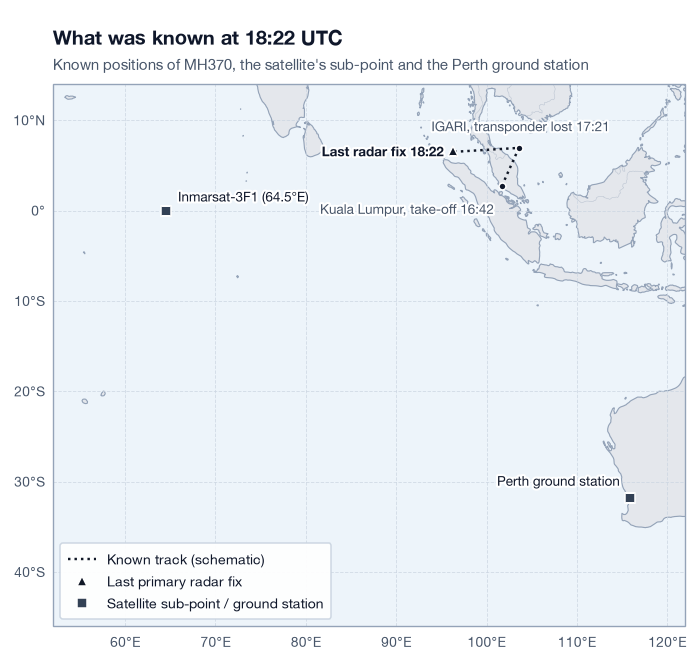

In [10]:
# Plotting only — safe to skip.
fig, ax = make_cartopy_map(
    "corridor",
    title="What was known at 18:22 UTC",
    subtitle="Known positions of MH370, the satellite's sub-point and the Perth ground station",
)
track_lat = [KLIA_GATE_LAT_DEG, IGARI_LAT_DEG, MEKAR_LAT_DEG, RADAR_FIX_LAT_DEG]
track_lon = [KLIA_GATE_LON_DEG, IGARI_LON_DEG, MEKAR_LON_DEG, RADAR_FIX_LON_DEG]
ax.plot(
    track_lon,
    track_lat,
    color=COLOR_RADAR,
    ls=":",
    lw=1.6,
    transform=ccrs.PlateCarree(),
    label="Known track (schematic)",
    zorder=6,
)
annotate_places(
    ax,
    [
        {
            "name": "Kuala Lumpur, take-off 16:42",
            "lat": KLIA_GATE_LAT_DEG,
            "lon": KLIA_GATE_LON_DEG,
            "offset": (-8, -10),
        },
        {
            "name": "IGARI, transponder lost 17:21",
            "lat": IGARI_LAT_DEG,
            "lon": IGARI_LON_DEG,
            "offset": (0, 9),
            "ha": "center",
        },
        {
            "name": "Last radar fix 18:22",
            "lat": RADAR_FIX_LAT_DEG,
            "lon": RADAR_FIX_LON_DEG,
            "role": "radar",
            "offset": (-9, 0),
            "va": "center",
            "legend_label": "Last primary radar fix",
        },
        {
            "name": "Inmarsat-3F1 (64.5°E)",
            "lat": 0.0,
            "lon": SAT_NOMINAL_LON_DEG,
            "role": "satellite",
            "offset": (8, 4),
            "legend_label": "Satellite sub-point / ground station",
        },
        {
            "name": "Perth ground station",
            "lat": GES_LAT_DEG,
            "lon": GES_LON_DEG,
            "role": "satellite",
            "offset": (-8, 6),
        },
    ],
)
style_legend(ax, loc="lower left")
plt.show()

> **Takeaway.** After 18:22 the aircraft could have flown almost anywhere within six hours of flight; the seven handshakes are the only clue to where it went.

### 0.6 The method at a glance

The whole investigation in one picture: the six steps that turn seven delays into a search map, each labelled with the chapter that introduces it. The finished filter is then graded on invented flights whose truth we know (Interlude), re-run assumption by assumption (Epilogue A) and compared with the real search (Epilogue B).

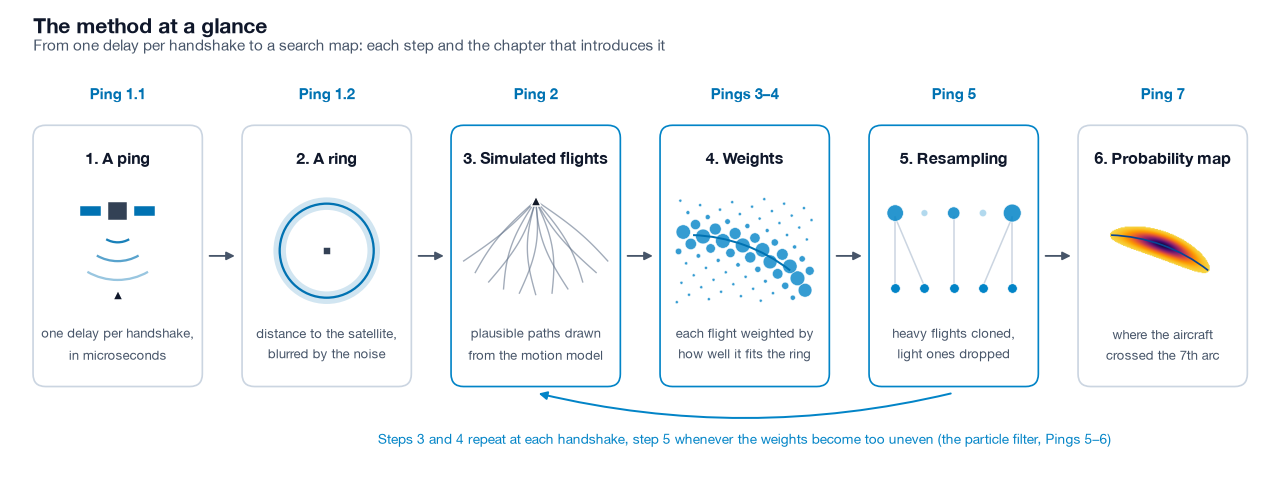

In [11]:
# Plotting only — safe to skip.
# The method at a glance: six steps from one handshake to a search map (a drawing, no data).
from matplotlib.patches import Arc, Circle, FancyArrowPatch, FancyBboxPatch, Rectangle, Wedge

GLANCE_STEPS = (  # title, caption, chapter that introduces the step
    ("A ping", "one delay per handshake,\nin microseconds", "Ping 1.1"),
    ("A ring", "distance to the satellite,\nblurred by the noise", "Ping 1.2"),
    ("Simulated flights", "plausible paths drawn\nfrom the motion model", "Ping 2"),
    ("Weights", "each flight weighted by\nhow well it fits the ring", "Pings 3–4"),
    ("Resampling", "heavy flights cloned,\nlight ones dropped", "Ping 5"),
    ("Probability map", "where the aircraft\ncrossed the 7th arc", "Ping 7"),
)
GLANCE_LOOP = (2, 4)  # steps 3 to 5 (0-based indices) are repeated at every handshake
GLANCE_DX, GLANCE_W, GLANCE_H, GLANCE_Y0 = 2.0, 1.62, 2.5, 1.2  # step spacing and box, axis units
GLANCE_ARC = (-0.55, -1.45, 1.6)  # ring segment across icons 4 and 6: centre offset and radius


def glance_arc(ax, cx, cy, color, lw):
    """Draw the ring segment across an icon centred on (cx, cy); return its centre and radius."""
    ox, oy, radius = cx + GLANCE_ARC[0], cy + GLANCE_ARC[1], GLANCE_ARC[2]
    arc = Arc((ox, oy), 2 * radius, 2 * radius, theta1=52, theta2=88, color=color, lw=lw)
    ax.add_patch(arc).set_zorder(4)
    return ox, oy, radius


def icon_ping(ax, cx, cy):
    ax.add_patch(Rectangle((cx - 0.08, cy + 0.3), 0.16, 0.16, color=COLOR_SATELLITE))
    for side in (-1, 1):  # solar panels
        ax.add_patch(Rectangle((cx + side * 0.26 - 0.09, cy + 0.345), 0.18, 0.07, color=COLOR_RING))
    for i, r in enumerate((0.22, 0.4, 0.58)):  # the radio signal
        wave = Arc((cx, cy + 0.3), 2 * r, 2 * r, theta1=240, theta2=300, color=COLOR_RING, lw=1.5)
        ax.add_patch(wave).set_alpha(0.9 - 0.25 * i)
    ax.plot(cx, cy - 0.42, marker="^", ms=6.5, color=COLOR_TEXT, mec=COLOR_BG)


def icon_ring(ax, cx, cy):
    ax.add_patch(Wedge((cx, cy), 0.51, 0, 360, width=0.12, color=COLOR_RING, alpha=0.18, lw=0))
    ax.add_patch(Circle((cx, cy), 0.45, fill=False, color=COLOR_RING, lw=1.5))
    ax.plot(cx, cy, marker="s", ms=5.5, color=COLOR_SATELLITE, mec=COLOR_BG)


def icon_flights(ax, cx, cy):
    t = np.linspace(0.0, 1.0, 30)
    for j, angle in enumerate(np.radians(np.linspace(-50, 50, 11))):
        x = cx + 0.9 * t * np.sin(angle) + 0.08 * (-1) ** j * np.sin(np.pi * t) * np.cos(angle)
        ax.plot(x, cy + 0.48 - 0.9 * t * np.cos(angle), color=COLOR_PRIOR, lw=0.9, alpha=0.6)
    ax.plot(cx, cy + 0.48, marker="^", ms=6.5, color=COLOR_RADAR, mec=COLOR_BG)


def icon_weights(ax, cx, cy):
    ox, oy, radius = glance_arc(ax, cx, cy, COLOR_RING, 1.3)
    i = np.arange(70)  # an evenly spread, non-random set of flights (golden-ratio lattice)
    x, y = cx + 1.3 * ((i * (np.sqrt(5) - 1) / 2) % 1 - 0.5), cy + (i + 0.5) / 70 - 0.5
    w = np.exp(-0.5 * ((np.hypot(x - ox, y - oy) - radius) / 0.08) ** 2)
    ax.scatter(x, y, s=4 + 90 * w, color=COLOR_PARTICLES, alpha=0.8, ec=COLOR_BG, lw=0.4, zorder=3)


def icon_resample(ax, cx, cy):
    xs, weights = cx + np.linspace(-0.56, 0.56, 5), np.array([0.35, 0.02, 0.18, 0.03, 0.42])
    parents = np.array([0, 0, 2, 4, 4])  # systematic resampling of these five weights
    for child, parent in enumerate(parents):
        ax.plot([xs[parent], xs[child]], [cy + 0.32, cy - 0.34], color=COLOR_GRID, lw=1.0)
    alpha = np.where(np.isin(np.arange(5), parents), 0.85, 0.3)
    style = dict(color=COLOR_PARTICLES, ec=COLOR_BG, lw=0.5, zorder=3)
    ax.scatter(xs, np.full(5, cy + 0.36), s=12 + 300 * weights, alpha=alpha, **style)
    ax.scatter(xs, np.full(5, cy - 0.36), s=40, **style)


def icon_map(ax, cx, cy):
    ox, oy, radius = glance_arc(ax, cx, cy, COLOR_SEVENTH_ARC, 1.1)
    extent = (cx - 0.62, cx + 0.62, cy - 0.5, cy + 0.5)
    gx, gy = np.meshgrid(np.linspace(*extent[:2], 160), np.linspace(*extent[2:], 130))
    across = (np.hypot(gx - ox, gy - oy) - radius) / 0.05
    along = (np.degrees(np.arctan2(gy - oy, gx - ox)) - 70) / 7
    z = np.exp(-0.5 * (across**2 + along**2))
    image = dict(extent=extent, origin="lower", cmap=CMAP_DENSITY, vmin=0, vmax=1, zorder=2)
    ax.imshow(np.where(z > 0.03, z, np.nan), **image)


fig = plt.figure(figsize=(11.4, 4.3))
ax = fig.add_axes((0.0, 0.0, 1.0, 0.88))
ax.set(xlim=(0, 12), ylim=(0.25, 4.1), aspect="equal")
ax.axis("off")
icons = (icon_ping, icon_ring, icon_flights, icon_weights, icon_resample, icon_map)
centres = 1.0 + GLANCE_DX * np.arange(len(GLANCE_STEPS))
mid_y, label = GLANCE_Y0 + GLANCE_H / 2, dict(ha="center", fontweight="bold")
for i, (cx, (title, caption, chapter), icon) in enumerate(
    zip(centres, GLANCE_STEPS, icons, strict=True)
):
    edge = COLOR_PARTICLES if GLANCE_LOOP[0] <= i <= GLANCE_LOOP[1] else COLOR_GRID
    box = FancyBboxPatch(
        (cx - GLANCE_W / 2, GLANCE_Y0), GLANCE_W, GLANCE_H, "round,pad=0,rounding_size=0.12"
    )
    ax.add_patch(box).set(facecolor=COLOR_BG, edgecolor=edge, lw=1.1)
    ax.text(
        cx, GLANCE_Y0 + GLANCE_H + 0.22, chapter, va="bottom", size=9.5, color=COLOR_RING, **label
    )
    ax.text(cx, GLANCE_Y0 + GLANCE_H - 0.22, f"{i + 1}. {title}", va="top", size=10.5, **label)
    muted = dict(ha="center", va="bottom", size=8.6, color=COLOR_TEXT_MUTED, linespacing=1.35)
    ax.text(cx, GLANCE_Y0 + 0.2, caption, **muted)
    icon(ax, cx, GLANCE_Y0 + 1.3)
    if i < len(GLANCE_STEPS) - 1:  # arrow to the next step
        ends = (cx + GLANCE_W / 2 + 0.04, mid_y), (cx + GLANCE_DX - GLANCE_W / 2 - 0.04, mid_y)
        ax.add_patch(FancyArrowPatch(*ends, arrowstyle="-|>", mutation_scale=11, lw=1.2))
        ax.patches[-1].set_color(COLOR_TEXT_MUTED)
loop_ends = [(centres[i], GLANCE_Y0 - 0.06) for i in GLANCE_LOOP[::-1]]
loop = FancyArrowPatch(*loop_ends, connectionstyle="arc3,rad=-0.12", arrowstyle="-|>", lw=1.3)
ax.add_patch(loop).set(color=COLOR_PARTICLES, mutation_scale=11)
ax.text(
    centres[list(GLANCE_LOOP)].mean(),
    0.7,
    "Steps 3 and 4 repeat at each handshake, step 5 whenever the weights become too uneven"
    " (the particle filter, Pings 5–6)",
    ha="center",
    va="center",
    size=9.0,
    color=COLOR_PARTICLES,
)
set_suptitle_header(
    fig,
    "The method at a glance",
    "From one delay per handshake to a search map: each step and the chapter that introduces it",
    x=0.016,
)
plt.show()

**Notation.** The symbols that recur across chapters; each is defined again where it first appears.

| Symbol | Meaning | Unit | Introduced in |
|---|---|---|---|
| $k$ | index of a handshake (ping), from 1 to 7 | — | Prologue |
| $t_k$ | time of handshake $k$ | UTC | Prologue |
| $z_k$ | measured burst timing offset (BTO) of handshake $k$ | µs | Prologue |
| $h_k(x)$ | BTO predicted for an aircraft at position $x$ | µs | Ping 1.1 |
| $\sigma_k$ | standard deviation of the BTO noise of handshake $k$ | µs | Ping 1.2 |
| $x_k = (\varphi, \lambda, \psi, v)$ | aircraft state at handshake $k$: latitude, longitude, heading, ground speed | degrees, knots | Prologue, Ping 2.1 |
| $\tau$ | time of the final major turn | hours after the radar fix | Ping 2.1 |
| $p(x_{0:7})$<br>$p(z_k \mid x_k)$<br>$p(x_{0:7} \mid z_{1:7})$ | prior over flight paths<br>likelihood of handshake $k$<br>posterior over flight paths | — | Prologue |
| $N$ | number of samples, simulated flights or particles | — | Ping 1.3 |
| $K$ | number of handshakes used so far | — | Ping 2.2 |
| $Z_K$ | evidence: the likelihood of the first $K$ BTOs, averaged over the prior | $\mu\mathrm{s}^{-K}$ | Ping 1.2 |
| $a_K$ | acceptance rate of rejection sampling after $K$ handshakes | — | Ping 1.3 ($a_1$), Ping 2.2 |
| $w^{(i)}$, $W^{(i)}$ | importance weight of particle $i$, and the same weight normalised to sum to one | — | Ping 3.1 |
| ESS | effective sample size of a weighted set | — | Ping 4.1 |
| $\alpha$ | probability held by a credible region (50%, 90% or 95%) | — | Interlude |

A few letters are reused locally and redefined where they appear: $\tau$ is also the integrated autocorrelation time of a chain (Ping 2.3) and the resampling threshold (Ping 5.2); $w$ is also the ground standard deviation across a band and $\varphi_w$ a Gaussian density (Ping 2.3); $M$ is the maximum of the likelihood (Ping 2.2) and the number of synthetic flights (Interlude); $c$ is the speed of light (Ping 1.1) and a constant of a toy model (Ping 4.2); $\alpha$ is also the acceptance probability of a Metropolis step (Ping 2.3), and the calibration chart labels the nominal level $1 - \alpha$; in Ping 2.3, $k$ is also a lag, $t$ a step of the chain and $s$ the step size (also the standard deviation of the raw weights in Ping 4.1).

### 0.7 Where Monte Carlo enters

**The answer is a probability map, not a point.** GPS locates a receiver by crossing several distances measured at the same instant from several satellites. Here a single satellite measured one distance at each of seven different moments, and the aircraft moved in between: each ring constrains where it was at that moment only, and the seven rings are nearly concentric around the point beneath the satellite (Ping 1.1). There is nothing to triangulate. A whole family of flight paths fits the seven delays within their noise, and 90% of the probability ends up spread over some 1,750 km of the 7th arc (Ping 7.2). The honest answer to "where?" is therefore a probability for every region of the ocean: the posterior $p(x_{0:7} \mid z_{1:7})$ of the Prologue.

**Every number this notebook reports is an expectation over flight paths.** Each of the first four rows below is the same weighted average with a different function $f$: the filter returns simulated flights $x^{(i)}$ with normalised weights $W^{(i)}$ (Pings 3 to 5), and $\sum_i W^{(i)} f\big(x^{(i)}\big)$ estimates $\mathbb{E}[f(X) \mid z_{1:7}]$. The evidence, an expectation under the prior, is a product of such averages.

| Question | What we report | As an expectation | Monte Carlo estimate | Our result |
|---|---|---|---|---|
| Where should ships search? | probability that the 7th-arc crossing lies in a region $A$ | $\mathbb{E}[\mathbf{1}_A(X_7) \mid z_{1:7}]$ | $\sum_i W^{(i)}\, \mathbf{1}_A\big(x_7^{(i)}\big)$ | 50% region from 39.5°S to 32°S (Ping 7.1) |
| Where along the arc? | mean latitude of the crossing | $\mathbb{E}[\varphi_7 \mid z_{1:7}]$ | $\sum_i W^{(i)}\, \varphi_7^{(i)}$ | 35.5°S (Ping 7.2) |
| How sure? | 90% credible interval of that latitude | quantiles of $F(\varphi) = \mathbb{E}[\mathbf{1}_{\varphi_7 \le \varphi} \mid z_{1:7}]$ | quantiles of $\sum_i W^{(i)}\, \mathbf{1}_{\varphi_7^{(i)} \le \varphi}$ | 40.3°S to 30.1°S (Ping 7.2) |
| When did it turn south? | probability that the final turn came before the unanswered call of 18:39 | $\mathbb{E}[\mathbf{1}_{\text{turn before 18:39}} \mid z_{1:7}]$ | share of the weight carried by flights that turned before 18:39 | 60% (Ping 6) |
| Which assumptions do the data support? | evidence of a set of assumptions | $Z_7 = p(z_{1:7}) = \mathbb{E}_{\text{prior}}[L(X)]$ | product over the pings of the weighted average likelihood (Ping 5.2) | the briefing-slide radar fix: log-evidence 27.3 lower (Epilogue A) |

Because each of these numbers is an average over random simulations, each also carries a Monte Carlo error of its own. We measure it by repeating the whole computation with fresh random numbers: 0.16° on the mean latitude, twenty times less than the posterior spread (Ping 7.3).

**None of these expectations can be computed exactly.** The posterior lives in 28 dimensions (4 unknowns at each of the 7 pings), is known only up to its normalising constant, and the delays depend nonlinearly on the aircraft's position, so no formula gives it; a grid with only 10 points per axis would need $10^{28}$ cells (Ping 1.3). Monte Carlo replaces each integral by an average over random samples, whose error falls like $1/\sqrt{N}$ whatever the dimension.

**We do not simulate *the* flight.** We simulate candidate flights from a model of how the aircraft could have flown (Ping 2), let the seven delays weigh them (Ping 3), and read every answer off the weighted cloud. The rest of the notebook makes that average work and measures how far it can be trusted:

1. the plainest recipe, keeping only the flights that fit, is exact but collapses (Ping 2);
2. weighting keeps every flight (Ping 3), but the weights degenerate (Ping 4);
3. resampling repairs them, which gives the particle filter (Ping 5);
4. invented flights whose truth we know check that the reported probabilities are honest (Interlude);
5. independent re-runs measure the Monte Carlo error (Ping 7.3), and Epilogue A separates it from the uncertainty that comes from our assumptions, which no amount of computation removes.

---

## Ping 1 — A ping is a circle

> **In plain words**
>
> A handshake only records how late the aircraft's reply arrived. That delay fixes the aircraft's distance from the satellite but not its direction, so each handshake places it somewhere on a circle around the point below the satellite, blurred into a narrow band by measurement error. To measure how much of a box on the map is compatible with that band, we throw random darts into the box and average how well each dart fits: the estimate sharpens as darts accumulate, but slowly, since halving its error takes four times as many darts.

> **The obstacle.** A handshake does not report a position. It reports one number, the *burst timing offset* (BTO): how late the aircraft's reply reached the ground station. What can a single number tell us about where the aircraft is?

### 1.1 What the satellite measures

Every handshake is a round trip. The ground station in Perth calls the aircraft through the satellite, and the aircraft answers through the same satellite. The BTO is the duration of that round trip minus a fixed offset $b$, the *BTO bias*, which Inmarsat calibrated on this very aircraft while it was parked at its gate in Kuala Lumpur before departure [1]:

$$
h_k(x) = \frac{2}{c}\Big(\lVert \mathbf{r}_{\mathrm{sat}}(t_k) - \mathbf{r}(x) \rVert + \lVert \mathbf{r}_{\mathrm{sat}}(t_k) - \mathbf{r}_{\mathrm{GES}} \rVert\Big) + b .
$$

Here $\mathbf{r}(x)$ is the aircraft position in Earth-centred Cartesian coordinates, $\mathbf{r}_{\mathrm{sat}}(t_k)$ the satellite position at the time $t_k$ of handshake $k$, $\mathbf{r}_{\mathrm{GES}}$ the ground earth station, and $c$ the speed of light. Only the first distance depends on the aircraft, so a measured value $z_k$ fixes the aircraft–satellite range:

$$
d_k = \frac{c\,(z_k - b)}{2} - \lVert \mathbf{r}_{\mathrm{sat}}(t_k) - \mathbf{r}_{\mathrm{GES}} \rVert .
$$

The aircraft therefore lies on a sphere of radius $d_k$ centred on the satellite. Cut by the Earth's surface at cruise altitude, that sphere becomes a **ring** around the sub-satellite point. One handshake gives one ring and says nothing about the direction.

Two details matter at this precision. One microsecond of BTO is $c \times 1\,\mu\mathrm{s} / 2 \approx 150$ m of range, while the Earth's polar radius is 21 km shorter than its equatorial radius, so positions live on the WGS-84 ellipsoid rather than on a sphere. And the satellite is not fixed: its orbit is slightly inclined, so we use its tabulated position at each handshake.

In [12]:
def geodetic_to_ecef(lat_deg, lon_deg, alt_km=0.0):
    """WGS-84 latitude, longitude (deg) and altitude (km) -> Earth-centred Earth-fixed xyz (km)."""
    lat, lon, alt_km = np.broadcast_arrays(np.radians(lat_deg), np.radians(lon_deg), alt_km)
    n = WGS84_A_KM / np.sqrt(1.0 - WGS84_E2 * np.sin(lat) ** 2)  # prime-vertical radius
    return np.stack(
        [
            (n + alt_km) * np.cos(lat) * np.cos(lon),
            (n + alt_km) * np.cos(lat) * np.sin(lon),
            (n * (1.0 - WGS84_E2) + alt_km) * np.sin(lat),
        ],
        axis=-1,
    )


GES_ECEF_KM = geodetic_to_ecef(GES_LAT_DEG, GES_LON_DEG, GES_ALT_KM)


def predicted_bto(lat_deg, lon_deg, sat_ecef_km, alt_km=CRUISE_ALT_KM):
    """Measurement function h_k: BTO (µs) of an aircraft at (lat, lon, alt), given the satellite."""
    aircraft_km = geodetic_to_ecef(lat_deg, lon_deg, alt_km)
    path_km = np.linalg.norm(aircraft_km - sat_ecef_km, axis=-1) + np.linalg.norm(
        sat_ecef_km - GES_ECEF_KM, axis=-1
    )
    return 2.0 * path_km / C_KM_PER_US + BTO_BIAS_US


def destination(lat_deg, lon_deg, bearing_deg, distance_km):
    """End point of a great-circle path of length distance_km leaving (lat, lon) on a bearing."""
    lat, bearing = np.radians(lat_deg), np.radians(bearing_deg)
    delta = distance_km / EARTH_RADIUS_KM  # angular distance (radians)
    sin_lat2 = np.sin(lat) * np.cos(delta) + np.cos(lat) * np.sin(delta) * np.cos(bearing)
    dlon = np.arctan2(
        np.sin(bearing) * np.sin(delta) * np.cos(lat), np.cos(delta) - np.sin(lat) * sin_lat2
    )
    return np.degrees(np.arcsin(sin_lat2)), (lon_deg + np.degrees(dlon) + 180.0) % 360.0 - 180.0


def great_circle_km(lat1_deg, lon1_deg, lat2_deg, lon2_deg):
    """Great-circle distance (haversine formula) on the mean-radius sphere."""
    lat1, lat2 = np.radians(lat1_deg), np.radians(lat2_deg)
    dlat, dlon = lat2 - lat1, np.radians(lon2_deg - lon1_deg)
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2.0 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


def initial_bearing(lat1_deg, lon1_deg, lat2_deg, lon2_deg):
    """Bearing (degrees clockwise from north) of the great circle from point 1 towards point 2."""
    lat1, lat2 = np.radians(lat1_deg), np.radians(lat2_deg)
    dlon = np.radians(lon2_deg - lon1_deg)
    y = np.sin(dlon) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    return np.degrees(np.arctan2(y, x)) % 360.0


def extent_edges(extent, cell_deg):
    """Latitude and longitude edges of a grid of cell_deg cells covering a map extent."""
    lon_min, lon_max, lat_min, lat_max = extent
    return (
        np.arange(lat_min, lat_max + cell_deg / 2, cell_deg),
        np.arange(lon_min, lon_max + cell_deg / 2, cell_deg),
    )


def cell_areas_km2(lat_edges, lon_edges):
    """Areas of the cells of a latitude-longitude grid on the sphere: R² Δλ (sin φ₂ - sin φ₁)."""
    lat_band = np.diff(np.sin(np.radians(lat_edges)))[:, None]
    return EARTH_RADIUS_KM**2 * lat_band * np.radians(np.diff(lon_edges))[None, :]


def subsatellite_point(sat_ecef_km):
    """Geocentric latitude and longitude of the point directly below the satellite."""
    x, y, z = sat_ecef_km
    return np.degrees(np.arctan2(z, np.hypot(x, y))), np.degrees(np.arctan2(y, x))


def bto_ring(bto_us, sat_ecef_km, alt_km=CRUISE_ALT_KM, n_points=RING_POINTS):
    """Ring {x : h(x) = bto_us}: bisection along each bearing from the sub-satellite point."""
    lat0, lon0 = subsatellite_point(sat_ecef_km)
    bearings = np.linspace(0.0, 360.0, n_points)
    near, far = np.zeros(n_points), np.full(n_points, RING_MAX_DISTANCE_KM)
    for _ in range(RING_BISECTION_STEPS):
        mid = 0.5 * (near + far)
        short = predicted_bto(*destination(lat0, lon0, bearings, mid), sat_ecef_km, alt_km) < bto_us
        near, far = np.where(short, mid, near), np.where(short, far, mid)
    return destination(lat0, lon0, bearings, 0.5 * (near + far))

**Two checks before we trust the formula.**

*The aircraft at the gate.* Before departure, MH370 sat at gate C1 of Kuala Lumpur airport and exchanged messages with the satellite; Ashton et al. [1] publish seven of the BTO values measured there around 16:00 UTC. The forward model must reproduce them. One input is weaker than the others: the satellite's $z$ coordinate at 16:00 is not tabulated in the sources we could retrieve, so we use an interpolated value (UNVERIFIED) and print how much the prediction depends on it.

In [13]:
gate_bto = predicted_bto(KLIA_GATE_LAT_DEG, KLIA_GATE_LON_DEG, SAT_ECEF_1600_KM, KLIA_GATE_ALT_KM)
gate_ecef = geodetic_to_ecef(KLIA_GATE_LAT_DEG, KLIA_GATE_LON_DEG, KLIA_GATE_ALT_KM)
# d(BTO)/dz_sat = (2/c) * [(z_sat - z_gate)/d_gate + (z_sat - z_GES)/d_GES], in µs per km
dbto_dz = (2.0 / C_KM_PER_US) * sum(
    (SAT_ECEF_1600_KM[2] - point[2]) / np.linalg.norm(SAT_ECEF_1600_KM - point)
    for point in (gate_ecef, GES_ECEF_KM)
)
gate_residual = KLIA_BTO_US.mean() - gate_bto
print(f"Predicted BTO at the gate: {gate_bto:,.0f} µs")
print(
    f"Measured: mean {KLIA_BTO_US.mean():,.0f} µs,"
    f" range {KLIA_BTO_US.min():,.0f} to {KLIA_BTO_US.max():,.0f} µs"
)
print(
    f"Residual: {gate_residual:+.0f} µs, i.e. {0.5 * C_KM_PER_US * gate_residual:+.1f} km of range"
)
print(f"Sensitivity to the unverified satellite z: {dbto_dz:.2f} µs per km")

Predicted BTO at the gate: 14,799 µs
Measured: mean 14,791 µs, range 14,740 to 14,820 µs
Residual: -7 µs, i.e. -1.1 km of range
Sensitivity to the unverified satellite z: 0.76 µs per km


The gate sits on its predicted ring to within 7 µs, about a kilometre of range, well below the noise level of the measurements (29 µs). The unverified $z$ coordinate matters little: an error of 10 km would move the prediction by about 8 µs.

*The last radar fix.* The first handshake came 3 minutes after the last radar contact. Ring 1 must therefore pass within a few minutes of flight of the radar fix: at a cruise speed of about 500 knots, an aircraft covers some 45 km in 3 minutes.

In [14]:
ring1_lat, ring1_lon = bto_ring(PING_BTO_US[0], SAT_ECEF_KM[0])
gap_km = great_circle_km(RADAR_FIX_LAT_DEG, RADAR_FIX_LON_DEG, ring1_lat, ring1_lon).min()
bto_at_fix = predicted_bto(RADAR_FIX_LAT_DEG, RADAR_FIX_LON_DEG, SAT_ECEF_KM[0])
print(
    f"Predicted BTO at the radar fix: {bto_at_fix:,.0f} µs;"
    f" measured at ping 1: {PING_BTO_US[0]:,.0f} µs"
)
print(
    f"Distance from the radar fix to ring 1: {gap_km:.0f} km, flown in {60 * T_PING_H[0]:.1f} min"
)

Predicted BTO at the radar fix: 12,695 µs; measured at ping 1: 12,520 µs
Distance from the radar fix to ring 1: 44 km, flown in 3.3 min


Ring 1 passes 44 km from the radar fix. Covering 44 km in 3.3 minutes takes at least 440 knots, a normal cruise speed for a Boeing 777. Both checks pass: the forward model, the constants and the data agree.

Now the seven rings themselves.

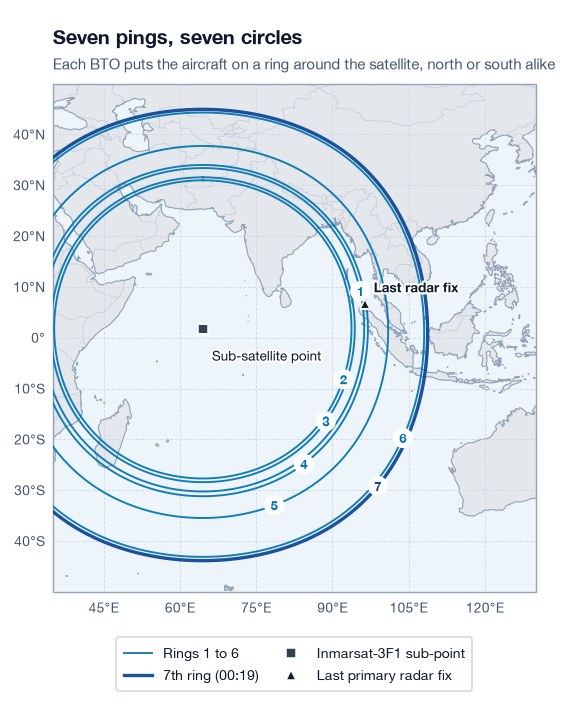

In [15]:
rings = [bto_ring(PING_BTO_US[k], SAT_ECEF_KM[k]) for k in range(N_PINGS)]
sub_lat, sub_lon = subsatellite_point(SAT_ECEF_KM[1])
fig, ax = make_cartopy_map(
    RINGS_EXTENT,
    figsize=FIGSIZE_SQUARE,
    title="Seven pings, seven circles",
    subtitle="Each BTO puts the aircraft on a ring around the satellite, north or south alike",
)
for k, (lat, lon) in enumerate(rings):
    last = k == N_PINGS - 1
    draw_ring(
        ax,
        lat,
        lon,
        emphasis=last,
        label="7th ring (00:19)" if last else ("Rings 1 to 6" if k == 0 else None),
    )
    i = RING_LABEL_BEARING_DEG[k] * (RING_POINTS - 1) // 360  # label each ring at its own bearing
    ax.text(
        lon[i],
        lat[i],
        str(k + 1),
        transform=ccrs.PlateCarree(),
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color=COLOR_SEVENTH_ARC if last else COLOR_RING,
        zorder=8,
        bbox={"boxstyle": "circle,pad=0.18", "facecolor": COLOR_BG, "edgecolor": "none"},
    )
annotate_places(
    ax,
    [
        {
            "name": "Sub-satellite point",
            "lat": sub_lat,
            "lon": sub_lon,
            "role": "satellite",
            "offset": (6, -12),
            "legend_label": "Inmarsat-3F1 sub-point",
        },
        {
            "name": "Last radar fix",
            "lat": RADAR_FIX_LAT_DEG,
            "lon": RADAR_FIX_LON_DEG,
            "role": "radar",
            "offset": (6, 6),
            "legend_label": "Last primary radar fix",
        },
    ],
)
style_legend(ax, loc="below")
plt.show()

> **Takeaway.** The rings are nearly concentric around the satellite's sub-point: ring 1 passes by the radar fix, ring 2 is the smallest, and the later rings grow steadily, so the aircraft first approached the sub-satellite point and then flew away from it. Each ring alone says nothing about direction, and each crosses both a northern corridor (Central Asia) and a southern one (Indian Ocean).

### 1.2 A ring has a width: the likelihood

Measured BTOs are noisy. We model handshake $k$ as

$$
z_k = h_k(x_k) + \varepsilon_k, \qquad \varepsilon_k \sim \mathcal{N}(0, \sigma_k^2) \ \text{independent},
$$

so the **likelihood** of a candidate position is the Gaussian density of the residual:

$$
p(z_k \mid x_k) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\!\left(-\frac{\big(z_k - h_k(x_k)\big)^2}{2\sigma_k^2}\right).
$$

Bayes' rule turns it into a belief about the position. For a prior $p(x)$,

$$
p(x \mid z_k) = \frac{p(z_k \mid x)\, p(x)}{Z_k}, \qquad Z_k = \int p(z_k \mid x)\, p(x)\, \mathrm{d}x .
$$

The *evidence* $Z_k$ is the average likelihood under the prior. With a flat prior, the posterior of a single ping is the ring blurred by the noise: a band, wider on the ground than in range because the satellite sees the aircraft at a slant.

In [16]:
def log_noise_density(residual_us, sd_us, dof=None):
    """log density of BTO noise with standard deviation sd_us: Gaussian, or Student-t if dof > 2."""
    if dof is None:
        return -0.5 * (residual_us / sd_us) ** 2 - np.log(np.sqrt(2.0 * np.pi) * sd_us)
    scale = sd_us * np.sqrt(
        (dof - 2.0) / dof
    )  # a Student-t with this scale has standard deviation sd_us
    r = residual_us / scale
    return (
        gammaln(0.5 * (dof + 1.0))
        - gammaln(0.5 * dof)
        - 0.5 * np.log(dof * np.pi)
        - np.log(scale)
        - 0.5 * (dof + 1.0) * np.log1p(r**2 / dof)
    )


def ping_log_likelihood(lat_deg, lon_deg, k, model=BASELINE, z_us=PING_BTO_US):
    """log p(z_k | x_k) for aircraft positions at handshake k, under the noise model of `model`."""
    residual = z_us[k] - predicted_bto(lat_deg, lon_deg, SAT_ECEF_KM[k])
    return log_noise_density(residual, model.bto_sd_scale * PING_BTO_SD_US[k], model.bto_dof)


def ring_band(k, delta_us, n_points=RING_POINTS):
    """Rings at z_k - delta, z_k and z_k + delta, traced on common bearings, and the half-distance
    between the outer two along each bearing: the half-width of the band on the ground (km)."""
    inner, centre, outer = (
        bto_ring(PING_BTO_US[k] + s * delta_us, SAT_ECEF_KM[k], n_points=n_points)
        for s in (-1, 0, 1)
    )
    return centre, inner, outer, 0.5 * great_circle_km(*inner, *outer)


for k in range(N_PINGS):
    half_width_km = np.median(ring_band(k, PING_BTO_SD_US[k])[3])
    range_sd_km = 0.5 * C_KM_PER_US * PING_BTO_SD_US[k]
    print(
        f"ping {k + 1}: sigma = {PING_BTO_SD_US[k]:.0f} µs -> {range_sd_km:.1f} km in range,"
        f" {half_width_km:.1f} km on the ground"
    )

ping 1: sigma = 62 µs -> 9.3 km in range, 15.4 km on the ground
ping 2: sigma = 29 µs -> 4.3 km in range, 7.7 km on the ground
ping 3: sigma = 29 µs -> 4.3 km in range, 7.6 km on the ground
ping 4: sigma = 29 µs -> 4.3 km in range, 7.1 km on the ground
ping 5: sigma = 29 µs -> 4.3 km in range, 6.4 km on the ground
ping 6: sigma = 29 µs -> 4.3 km in range, 5.6 km on the ground
ping 7: sigma = 62 µs -> 9.3 km in range, 11.9 km on the ground


A noise of 29 µs is 4.3 km of range but 6 to 8 km on the ground, because the satellite sees the aircraft at a slant. The two log-on handshakes, with $\sigma = 62$ µs, have bands twice as wide.

With a flat prior, the posterior after ping 1 is just the normalised likelihood. We evaluate it on a fine grid around the radar fix.

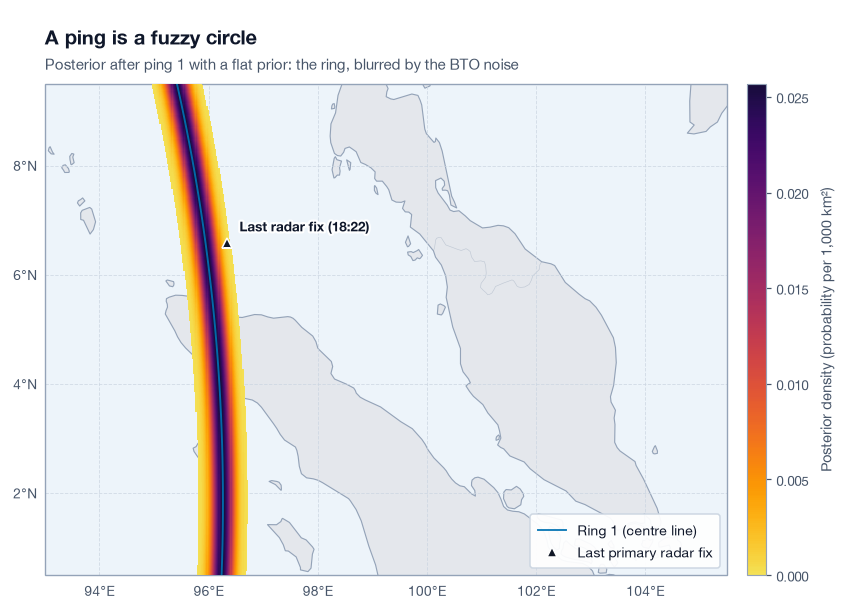

In [17]:
zoom_lat_edges, zoom_lon_edges = extent_edges(MAP_EXTENTS["malacca"], FINE_CELL_DEG)
lat_mid, lon_mid = (
    0.5 * (zoom_lat_edges[1:] + zoom_lat_edges[:-1]),
    0.5 * (zoom_lon_edges[1:] + zoom_lon_edges[:-1]),
)
zoom_area = cell_areas_km2(zoom_lat_edges, zoom_lon_edges)
zoom_mass = (
    np.exp(ping_log_likelihood(lat_mid[:, None], lon_mid[None, :], 0)) * zoom_area
)  # flat prior
zoom_mass /= zoom_mass.sum()

fig, ax = make_cartopy_map(
    "malacca",
    title="A ping is a fuzzy circle",
    subtitle="Posterior after ping 1 with a flat prior: the ring, blurred by the BTO noise",
)
draw_density(
    ax,
    zoom_lat_edges,
    zoom_lon_edges,
    1e3 * zoom_mass / zoom_area,
    "Posterior density (probability per 1,000 km²)",
)
draw_ring(ax, *rings[0], label="Ring 1 (centre line)")
annotate_places(
    ax,
    [
        {
            "name": "Last radar fix (18:22)",
            "lat": RADAR_FIX_LAT_DEG,
            "lon": RADAR_FIX_LON_DEG,
            "role": "radar",
            "offset": (8, 6),
            "legend_label": "Last primary radar fix",
        }
    ],
)
style_legend(ax, loc="lower right")
plt.show()

> **Takeaway.** One ping turns "anywhere" into "somewhere on a band about 60 km wide" (±2σ for this noisier log-on ping), but along the band every position is equally likely: a single measurement cannot localise the aircraft.

### 1.3 Why Monte Carlo? Our first estimator

Every question of this investigation is an integral against a probability distribution: the evidence $Z_k$, the probability that the aircraft lies inside a search box, the mean latitude of the crash site. In two dimensions a grid would do. But a flight observed at 7 pings has 4 unknowns per ping, a 28-dimensional integral: a grid with only 10 points per axis would need $10^{28}$ cells.

Monte Carlo replaces the grid by random samples [17]. To estimate $I = \mathbb{E}_p[f(X)]$, draw $X^{(1)}, \dots, X^{(N)}$ independently from $p$ and average:

$$
\hat{I}_N = \frac{1}{N} \sum_{i=1}^{N} f\big(X^{(i)}\big).
$$

- **Unbiased.** By linearity, $\mathbb{E}[\hat I_N] = \frac{1}{N}\sum_i \mathbb{E}[f(X^{(i)})] = I$.
- **Variance.** Independence kills the cross terms: $\mathrm{Var}(\hat I_N) = \sigma_f^2 / N$, with $\sigma_f^2 = \mathrm{Var}_p[f(X)]$.
- **Central limit theorem.** $\sqrt{N}\,(\hat I_N - I) \to \mathcal{N}(0, \sigma_f^2)$, which gives the 95% confidence interval $\hat I_N \pm 1.96\, \hat\sigma_f / \sqrt{N}$.
- **Rate.** The root-mean-square error is $\sigma_f/\sqrt{N}$, so $\log \mathrm{RMSE} = \log \sigma_f - \tfrac{1}{2} \log N$: a slope of $-1/2$ on a log-log plot, **whatever the dimension**. That is why Monte Carlo exists. The price hides in the constant $\sigma_f$, which we will fight for the rest of the notebook.

**Proved, now observed.** We estimate the evidence of ping 1 under a flat prior over a box of the map. This is the classic *hit-or-miss* estimator in disguise: to estimate the area of a circle, throw uniform points into a square around it and count the fraction that land inside. Here the square is the box and the circle is the band of ring 1, with one refinement: instead of a hard in/out verdict, each point scores its likelihood relative to the maximum, a soft hit between 0 and 1. Dividing by the maximum of the likelihood gives a number we can read: $a_1 = Z_1 / \max_x p(z_1 \mid x)$, the effective fraction of the box compatible with the ping. Each sample costs one evaluation of $h_1$. The reference value comes from an independent route: a deterministic equal-area quadrature grid.

In [18]:
def sample_flat_prior(n, rng, box=FLAT_BOX):
    """Positions uniform in area over a latitude-longitude box (sin(latitude) is uniform)."""
    (lat_lo, lat_hi), (lon_lo, lon_hi) = box
    sin_lat = rng.uniform(np.sin(np.radians(lat_lo)), np.sin(np.radians(lat_hi)), n)
    return np.degrees(np.arcsin(sin_lat)), rng.uniform(lon_lo, lon_hi, n)


def compatibility(lat_deg, lon_deg, k=0):
    """f(x) = p(z_k | x) / max_x p(z_k | x), in [0, 1]; its prior mean is a_k."""
    return np.exp(
        ping_log_likelihood(lat_deg, lon_deg, k) + np.log(np.sqrt(2 * np.pi) * PING_BTO_SD_US[k])
    )


# Reference by quadrature: a regular grid in (sin latitude, longitude) has equal-area cells.
t_start = time.perf_counter()
(lat_lo, lat_hi), (lon_lo, lon_hi) = FLAT_BOX
sin_edges = np.linspace(np.sin(np.radians(lat_lo)), np.sin(np.radians(lat_hi)), QUAD_CELLS + 1)
lon_edges = np.linspace(lon_lo, lon_hi, QUAD_CELLS + 1)
quad_lat = np.degrees(np.arcsin(0.5 * (sin_edges[1:] + sin_edges[:-1])))
quad_lon = 0.5 * (lon_edges[1:] + lon_edges[:-1])
a1_reference = np.mean([compatibility(lat, quad_lon).mean() for lat in quad_lat])

# Monte Carlo: MC_RUNS independent runs, each giving estimates for every N (nested prefixes).
mc_sizes = np.unique(np.logspace(1, np.log10(MC_MAX_SAMPLES), 17).astype(int))
rng = make_rng(1)
estimates = np.empty((MC_RUNS, len(mc_sizes)))
std_errors = np.empty_like(estimates)
for run in range(MC_RUNS):
    f = compatibility(*sample_flat_prior(mc_sizes[-1], rng))
    sums, sums_sq = np.cumsum(f)[mc_sizes - 1], np.cumsum(f**2)[mc_sizes - 1]
    estimates[run] = sums / mc_sizes
    sample_var = (sums_sq - mc_sizes * estimates[run] ** 2) / (mc_sizes - 1)
    std_errors[run] = np.sqrt(sample_var / mc_sizes)

rmse = np.sqrt(np.mean((estimates - a1_reference) ** 2, axis=0))
slope = np.polyfit(np.log(mc_sizes), np.log(rmse), 1)[0]
ci_coverage = np.mean(np.abs(estimates - a1_reference) <= 1.96 * std_errors, axis=0)
relative_sd = np.sqrt(np.mean(std_errors[:, -1] ** 2) * mc_sizes[-1]) / a1_reference
box_area_km2 = cell_areas_km2(np.array(FLAT_BOX[0]), np.array(FLAT_BOX[1])).sum()
mc_s = time.perf_counter() - t_start
print(
    f"Quadrature reference a_1 = {a1_reference:.5f}"
    f"   (Monte Carlo average at N = {mc_sizes[-1]:,}: {estimates[:, -1].mean():.5f})"
)
print(f"Fitted log-log slope of the RMSE: {slope:.3f}   (theory: -0.5)")
print(
    f"Coverage of the 95% CLT interval: N = {mc_sizes[0]}: {ci_coverage[0]:.0%},"
    f"  N = {mc_sizes[-1]:,}: {ci_coverage[-1]:.0%}"
)
print(f"Relative standard deviation sigma_f / a_1 = {relative_sd:.1f}")
print(
    f"Effective area of the band: a_1 x box area = {a1_reference * box_area_km2:,.0f} km²"
    f" out of {box_area_km2:,.0f} km²"
)

Quadrature reference a_1 = 0.01223   (Monte Carlo average at N = 100,000: 0.01223)
Fitted log-log slope of the RMSE: -0.490   (theory: -0.5)
Coverage of the 95% CLT interval: N = 10: 16%,  N = 100,000: 98%
Relative standard deviation sigma_f / a_1 = 7.5
Effective area of the band: a_1 x box area = 134,031 km² out of 10,959,367 km²


In [19]:
(box_lat_s, box_lat_n), (box_lon_w, box_lon_e) = FLAT_BOX
print_card(
    "Ping 1.3, plain Monte Carlo on the band of ring 1",
    simulated=f"positions uniform in area over the box from {format_lat(box_lat_s)} to"
    f" {format_lat(box_lat_n)} and from {box_lon_w:g}°E to {box_lon_e:g}°E, each scored by its"
    " ping-1 likelihood relative to the maximum (a soft hit between 0 and 1)",
    size=f"{MC_RUNS} independent runs, each read at {len(mc_sizes)} nested sample sizes from"
    f" {mc_sizes[0]} to {mc_sizes[-1]:,}; reference: quadrature on {QUAD_CELLS:,} ×"
    f" {QUAD_CELLS:,} equal-area cells",
    settings=f"sigma = {PING_BTO_SD_US[0]:.0f} µs (log-on handshake); random stream make_rng(1)",
    seconds=mc_s,
    result=f"a_1 = {a1_reference:.5f}; fitted slope of the error {slope:.3f} (theory -0.5);"
    f" the 95% CLT interval covers {ci_coverage[0]:.0%} at N = {mc_sizes[0]}"
    f" and {ci_coverage[-1]:.0%} at N = {mc_sizes[-1]:,}",
)

What we actually ran · Ping 1.3, plain Monte Carlo on the band of ring 1
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   positions uniform in area over the box from 10°S to 20°N and from 80°E to 110°E,
            each scored by its ping-1 likelihood relative to the maximum (a soft hit between 0
            and 1)
Size        200 independent runs, each read at 17 nested sample sizes from 10 to 100,000;
            reference: quadrature on 2,000 × 2,000 equal-area cells
Settings    sigma = 62 µs (log-on handshake); random stream make_rng(1)
Run time    1.44 s
Result      a_1 = 0.01223; fitted slope of the error -0.490 (theory -0.5); the 95% CLT interval
            covers 16% at N = 10 and 98% at N = 100,000


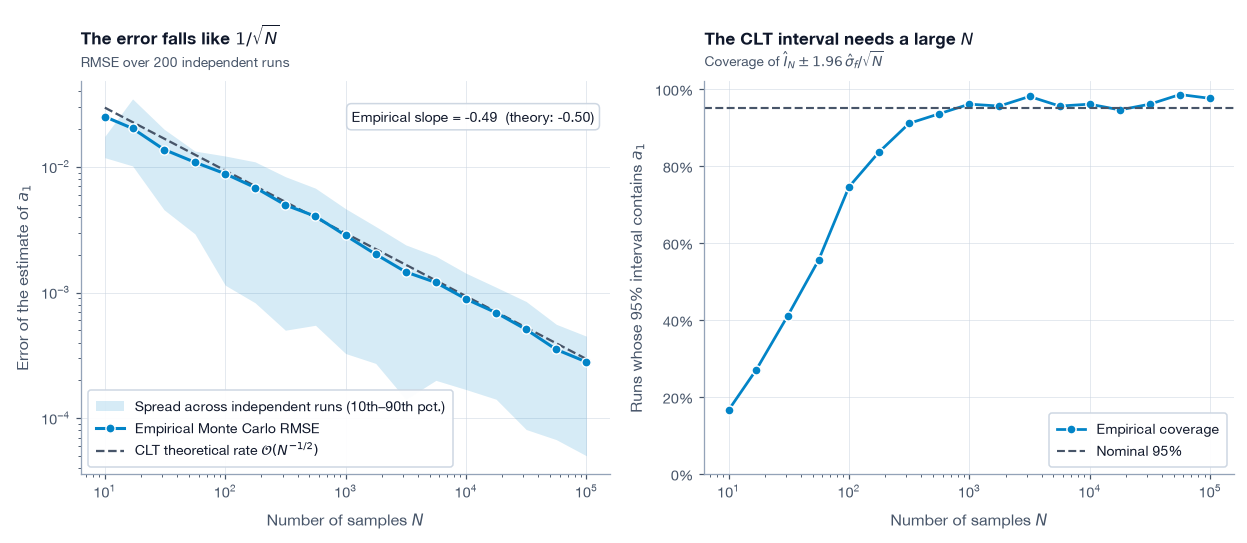

In [20]:
fig, (ax_rmse, ax_cov) = plt.subplots(1, 2, figsize=FIGSIZE_TWO_PANEL)
abs_err = np.abs(estimates - a1_reference)
plot_loglog_convergence(
    mc_sizes,
    rmse,
    error_low=np.percentile(abs_err, 10, axis=0),
    error_high=np.percentile(abs_err, 90, axis=0),
    empirical_slope=slope,
    xlabel="Number of samples $N$",
    ylabel="Error of the estimate of $a_1$",
    title="The error falls like $1/\\sqrt{N}$",
    subtitle=f"RMSE over {MC_RUNS} independent runs",
    ax=ax_rmse,
)
ax_cov.semilogx(
    mc_sizes,
    ci_coverage,
    color=COLOR_PARTICLES,
    marker="o",
    ms=6,
    mec=COLOR_BG,
    label="Empirical coverage",
)
ax_cov.axhline(0.95, color=COLOR_TEXT_MUTED, ls="--", lw=1.4, label="Nominal 95%")
ax_cov.set_ylim(0, 1.02)
ax_cov.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax_cov.set_xlabel("Number of samples $N$")
ax_cov.set_ylabel("Runs whose 95% interval contains $a_1$")
set_figure_header(
    ax_cov,
    "The CLT interval needs a large $N$",
    subtitle="Coverage of $\\hat I_N \\pm 1.96\\,\\hat\\sigma_f/\\sqrt{N}$",
)
style_legend(ax_cov, loc="lower right")
fig.tight_layout()
plt.show()

> **Takeaway.** The error falls exactly as fast as the CLT promises, but the CLT's error bars can only be trusted once $N$ is large.

Three lessons, each visible in the outputs above:

- **It works.** Monte Carlo and quadrature agree, and the fitted slope is close to the theoretical $-1/2$. In hit-or-miss terms, the band of ring 1 covers an effective 134,000 km² of the 11 million km² box, about 1.2%.
- **The CLT is a large-$N$ statement.** From $N \approx 10^3$ on, the 95% interval covers the truth close to 95% of the time, but at $N = 10$ it almost never does: most runs never land near the ring, report an estimate of zero and an interval of width zero.
- **The constant matters.** $\sigma_f / a_1 \approx 7.5$: a single sample is a poor witness, and a 1% relative precision needs about $(7.5 / 0.01)^2 \approx 560{,}000$ samples. The rate $-1/2$ is universal; the constant is not, and it is the constant that explodes in the next chapters.

---

## Ping 2 — Simulate flights

> **In plain words**
>
> The seven rings belong to one aircraft flying continuously, so we need a model of how it could have flown after radar lost it: we simulate a large number of plausible flights from the last radar position, each with its own turn, heading and speed. The simplest way to use the rings is to keep each simulated flight with a chance proportional to how well it fits them, and to discard the rest. The flights kept are spread exactly as they should be given the rings, but from the second ring on, each new ring discards most of the survivors: of two hundred thousand simulated flights, not one survives all seven.

> **The obstacle.** Seven rings, but one aircraft moving continuously: where it was at 19:41 constrains where it can be at 20:41. To exploit that link we need a **prior over whole flight paths**, a model of how a Boeing 777 moves when nobody tells us where it is going.

### 2.1 A stochastic model of the flight

The hidden state at time $t$ is $x = (\varphi, \lambda, \psi, v)$: latitude, longitude, heading (degrees clockwise from north) and ground speed (knots), with the altitude fixed at cruise level. Each simulated flight also carries one static unknown, the time $\tau$ of its *final major turn*. The prior $p(x_0)$ at the last radar fix ($t_0$) and the motion model $p(x_k \mid x_{k-1})$ between handshakes are:

| Ingredient | Assumption | Field of `FlightModel` |
|---|---|---|
| Start | radar fix plus an isotropic Gaussian position error | `start_sd_km` |
| Final major turn | the aircraft keeps the radar track until $\tau \sim \mathcal{U}(0, \tau_{\max})$, then turns | `turn_delay_max_h` |
| Heading after the turn | $\psi \sim \mathcal{U}(\psi_{\min}, \psi_{\max})$, a southern sector | `heading_min_deg`, `heading_max_deg` |
| Ground speed | $v \sim \mathcal{U}(v_{\min}, v_{\max})$ | `speed_min_kn`, `speed_max_kn` |
| Random turns and speed changes | Gaussian random walks, reflected at the speed bounds | `turn_walk_deg`, `speed_walk_kn` |

Every $\delta t = 5$ minutes, each flight updates its heading and speed, then moves a distance $v\,\delta t$ along a great circle:

$$
\psi \leftarrow \psi + \sigma_\psi \sqrt{\delta t}\, \xi, \qquad
v \leftarrow \mathrm{reflect}_{[v_{\min},\, v_{\max}]}\big(v + \sigma_v \sqrt{\delta t}\, \xi'\big), \qquad
\xi, \xi' \sim \mathcal{N}(0, 1).
$$

The $\sqrt{\delta t}$ scaling makes the spread of the random walk independent of the step size: after one hour, the heading has drifted by $\sigma_\psi$ degrees (one standard deviation) whatever $\delta t$ is. Because the next state depends on the past only through the current state (a *Markov* model), the prior over a whole path factorises:

$$
p(x_{0:7}) = p(x_0) \prod_{k=1}^{7} p(x_k \mid x_{k-1}).
$$

> **The southern-route assumption (A1 in section 0.3).** The BTO alone cannot tell north from south: every ring crosses both the Indian Ocean and Central Asia. Inmarsat's analysis of the burst frequency offset (BFO, a Doppler measurement we do not model) favoured the southern corridor [1, 6], so we encode that conclusion in the prior: after the turn, headings stay in a southern sector.

In [21]:
# Before its final major turn the aircraft follows airway N571: the bearing from MEKAR to the fix.
RADAR_TRACK_DEG = initial_bearing(
    MEKAR_LAT_DEG, MEKAR_LON_DEG, RADAR_FIX_LAT_DEG, RADAR_FIX_LON_DEG
)


def reflect(x, lo, hi):
    """Fold values back into [lo, hi], like a random walk bouncing off two walls."""
    span = hi - lo
    y = np.mod(x - lo, 2.0 * span)
    return lo + np.where(y > span, 2.0 * span - y, y)


def sample_initial(n, rng, model=BASELINE):
    """Draw n flights from p(x_0): state at the last radar fix, plus each flight's turn time."""
    particles = np.empty((n, 5))
    radius_km = model.start_sd_km * np.sqrt(
        rng.chisquare(2, n)
    )  # isotropic 2-D Gaussian, polar form
    particles[:, LAT], particles[:, LON] = destination(
        model.start_lat_deg, model.start_lon_deg, rng.uniform(0.0, 360.0, n), radius_km
    )
    particles[:, HDG] = rng.uniform(model.heading_min_deg, model.heading_max_deg, n)
    if model.speed_mode_kn is None:
        particles[:, SPD] = rng.uniform(model.speed_min_kn, model.speed_max_kn, n)
    else:
        particles[:, SPD] = rng.triangular(
            model.speed_min_kn, model.speed_mode_kn, model.speed_max_kn, n
        )
    particles[:, TURN] = rng.uniform(0.0, model.turn_delay_max_h, n)
    return particles


def propagate(particles, t_from_h, t_to_h, rng, model=BASELINE, track=None):
    """Sample x_k ~ p(x_k | x_{k-1}): fly every particle from t_from to t_to (hours after t_0)."""
    p = particles.copy()
    n_steps = max(1, round((t_to_h - t_from_h) / SUBSTEP_H))
    dt = (t_to_h - t_from_h) / n_steps
    for step in range(n_steps):
        # fraction of this step flown before the final turn (0 once turned, 1 before the turn)
        before = np.clip((p[:, TURN] - (t_from_h + step * dt)) / dt, 0.0, 1.0)
        xi = rng.standard_normal((2, len(p))) * np.sqrt(dt)
        p[:, HDG] += (before < 1) * model.turn_walk_deg * xi[0]
        p[:, SPD] = reflect(
            p[:, SPD] + model.speed_walk_kn * xi[1], model.speed_min_kn, model.speed_max_kn
        )
        step_km = KNOT_KMH * p[:, SPD] * dt
        if not before.any():  # every particle has turned: one great-circle step on its own heading
            p[:, LAT], p[:, LON] = destination(p[:, LAT], p[:, LON], p[:, HDG], step_km)
        else:  # a particle turning mid-step flies both legs: radar track, then its new heading
            on_track, turned = before > 0, before < 1
            p[on_track, LAT], p[on_track, LON] = destination(
                p[on_track, LAT],
                p[on_track, LON],
                RADAR_TRACK_DEG,
                before[on_track] * step_km[on_track],
            )
            p[turned, LAT], p[turned, LON] = destination(
                p[turned, LAT],
                p[turned, LON],
                p[turned, HDG],
                (1 - before[turned]) * step_km[turned],
            )
        if track is not None:
            track.append(p[:, [LAT, LON]])
    return p


def simulate_flights(n, rng, model=BASELINE, track=None):
    """Simulate n flights from the prior; return their states at the 7 handshakes: (7, n, 5)."""
    particles, t_prev, states = sample_initial(n, rng, model), 0.0, []
    if track is not None:
        track.append(particles[:, [LAT, LON]])
    for k in range(N_PINGS):
        particles = propagate(particles, t_prev, T_PING_H[k], rng, model, track)
        states.append(particles)
        t_prev = T_PING_H[k]
    return np.stack(states)

We simulate one large batch of prior flights, reused by Pings 2 to 4, store the log-likelihood of every flight at every ping, and print how far a typical prior flight lands from each ring, in units of the noise standard deviation.

In [22]:
t_start = time.perf_counter()
prior_states = simulate_flights(N_PRIOR_FLIGHTS, make_rng(2, 0))
simulation_s = time.perf_counter() - t_start
prior_log_lik = np.stack(
    [
        ping_log_likelihood(prior_states[k, :, LAT], prior_states[k, :, LON], k)
        for k in range(N_PINGS)
    ]
)
print(f"Radar track (MEKAR -> last fix): {RADAR_TRACK_DEG:.1f} deg")
print(f"Simulated {N_PRIOR_FLIGHTS:,} prior flights in {simulation_s:.1f} s")
residual_sd = np.sqrt(-2 * (prior_log_lik + np.log(np.sqrt(2 * np.pi) * PING_BTO_SD_US)[:, None]))
for k in range(N_PINGS):
    print(
        f"ping {k + 1}: median |residual| of a prior flight = {np.median(residual_sd[k]):4.0f} sd"
    )

Radar track (MEKAR -> last fix): 296.3 deg
Simulated 200,000 prior flights in 1.5 s
ping 1: median |residual| of a prior flight =    0 sd
ping 2: median |residual| of a prior flight =   47 sd
ping 3: median |residual| of a prior flight =   84 sd
ping 4: median |residual| of a prior flight =  123 sd
ping 5: median |residual| of a prior flight =  159 sd
ping 6: median |residual| of a prior flight =  204 sd
ping 7: median |residual| of a prior flight =   97 sd


The first ping is easy: three minutes after the radar fix, every simulated flight is still close to it. After that, a typical prior flight misses the rings by tens, then hundreds, of standard deviations: the prior is diffuse, the rings are sharp, and that mismatch is the whole difficulty of this problem.

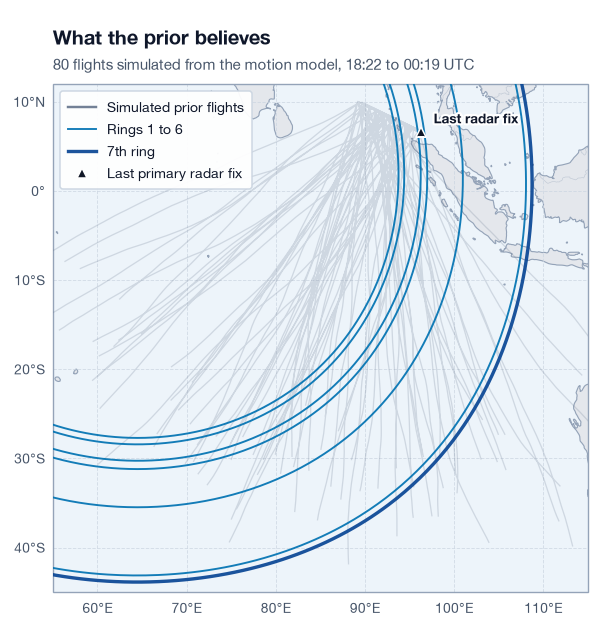

In [23]:
spaghetti = []
simulate_flights(SPAGHETTI_FLIGHTS, make_rng(2, 2), track=spaghetti)
spaghetti = np.stack(spaghetti)  # (time steps, flights, lat/lon)
fig, ax = make_cartopy_map(
    FLIGHT_EXTENT,
    figsize=FIGSIZE_SQUARE,
    title="What the prior believes",
    subtitle=f"{SPAGHETTI_FLIGHTS} flights simulated from the motion model, 18:22 to 00:19 UTC",
)
draw_trajectories(
    ax,
    spaghetti[:, :, 0].T,
    spaghetti[:, :, 1].T,
    role="prior",
    max_traces=SPAGHETTI_FLIGHTS,
    label="Simulated prior flights",
    show_endpoint=False,
)
for k, ring in enumerate(rings):
    draw_ring(
        ax,
        *ring,
        emphasis=k == N_PINGS - 1,
        label="7th ring" if k == N_PINGS - 1 else ("Rings 1 to 6" if k == 0 else None),
    )
annotate_places(
    ax,
    [
        {
            "name": "Last radar fix",
            "lat": RADAR_FIX_LAT_DEG,
            "lon": RADAR_FIX_LON_DEG,
            "role": "radar",
            "offset": (8, 4),
            "legend_label": "Last primary radar fix",
        }
    ],
)
style_legend(ax, loc="upper left")
plt.show()

> **Takeaway.** The prior fans out over millions of square kilometres, while each ring is a band a few kilometres wide: almost every simulated flight misses almost every ring.

### 2.2 Keep only the flights that fit: rejection sampling

The simplest way to turn prior flights into posterior flights is to keep each one with a probability proportional to how well it fits [17]. Let $L(x) = \prod_{k=1}^{K} p(z_k \mid x_k)$ be the likelihood of a whole path after $K$ pings, and $M = \prod_{k=1}^{K} (\sqrt{2\pi}\,\sigma_k)^{-1}$ its maximum (every residual zero).

1. Simulate a flight $x \sim p(x_{0:K})$.
2. Accept it with probability $L(x)/M = \exp\big(-\tfrac{1}{2}\sum_k r_k^2\big)$, where $r_k = (z_k - h_k(x_k))/\sigma_k$.

**Why it is exact.** The probability of drawing a flight in a set $A$ *and* accepting it is $\int_A p(x)\, L(x)/M \,\mathrm{d}x$. Dividing by the total acceptance probability $a_K = \int p(x) L(x)/M \,\mathrm{d}x = Z_K / M$ gives the density $p(x) L(x) / Z_K = p(x \mid z_{1:K})$. Accepted flights are **exact** posterior samples: no approximation at all.

**Why it collapses.** For a single ping the acceptance rate is $a_k = \mathbb{E}_p\big[e^{-r_k^2/2}\big] \approx \sqrt{2\pi}\,\sigma_k\, p_{h_k}(z_k)$, where $p_{h_k}$ is the prior density of the predicted BTO: the Gaussian bump has area $\sqrt{2\pi}\sigma_k$, which is small next to the spread of $h_k$. The acceptance rate is proportional to the width of the band; as $\sigma_k \to 0$ the band becomes a line of zero area and rejection never accepts anything. Over several pings, by the chain rule, $a_K = \prod_{k=1}^{K} \mathbb{P}(\text{accept at ping } k \mid \text{accepted at pings } 1, \dots, k-1)$. Every factor is well below 1, because a ring a few kilometres wide is tiny next to the region the aircraft could reach in an hour, so the acceptance rate decays geometrically with the number of pings. If the pings were independent, the factors would be the single-ping rates $a^{(k)}$ and $a_K \approx \prod_k a^{(k)}$; they are not, so we measure both.

In [24]:
t_start = time.perf_counter()
log_max_lik = -np.log(np.sqrt(2.0 * np.pi) * PING_BTO_SD_US)[:, None]  # log max of each likelihood
log_accept = np.cumsum(prior_log_lik - log_max_lik, axis=0)  # log L/M after K = 1..7 pings
accept_prob = np.exp(log_accept)  # acceptance probability of each flight, shape (7, n)

uniforms = make_rng(2, 1).random(
    N_PRIOR_FLIGHTS
)  # one uniform per flight: nested acceptance over K
n_accepted = (uniforms < accept_prob).sum(axis=1)
accept_rate = accept_prob.mean(
    axis=1
)  # a_K = E[L/M]: averaging L/M has lower variance than counting
accept_rate_se = accept_prob.std(axis=1) / np.sqrt(N_PRIOR_FLIGHTS)
single_ping_rate = np.exp(prior_log_lik - log_max_lik).mean(axis=1)
independent_rate = np.cumprod(single_ping_rate)
rejection_s = time.perf_counter() - t_start

print(" K   accepted   a_K (joint)             product of single-ping rates")
for k in range(N_PINGS):
    print(
        f"{k + 1:2d}  {n_accepted[k]:9,d}   {accept_rate[k]:.2e} ± {accept_rate_se[k]:.1e}"
        f"      {independent_rate[k]:.2e}"
    )

 K   accepted   a_K (joint)             product of single-ping rates
 1    175,974   8.80e-01 ± 3.4e-04      8.80e-01
 2      2,080   1.01e-02 ± 1.8e-04      1.02e-02
 3         89   4.57e-04 ± 3.2e-05      8.44e-05
 4          9   2.66e-05 ± 5.5e-06      4.66e-07
 5          2   2.93e-06 ± 1.0e-06      1.94e-09
 6          0   3.36e-08 ± 2.4e-08      5.87e-12
 7          0   2.71e-08 ± 2.1e-08      4.01e-14


In [25]:
print_card(
    "Ping 2.2, rejection sampling of prior flights",
    simulated="flights from the prior of section 2.1, flown from the radar fix to 00:19 UTC in"
    f" steps of about {60 * SUBSTEP_H:.0f} minutes; after K pings each flight is kept with"
    " probability L/M",
    size=f"{N_PRIOR_FLIGHTS:,} flights with one uniform each, reused for every K from 1 to"
    f" {N_PINGS}",
    settings=f"sigma = {PING_BTO_SD_US[1]:.0f} µs ({PING_BTO_SD_US[0]:.0f} µs for handshakes 1 and"
    " 7); streams make_rng(2, 0) for the flights and make_rng(2, 1) for the uniforms",
    seconds=simulation_s + rejection_s,
    result="flights kept after 1 to 7 pings: " + ", ".join(f"{n:,}" for n in n_accepted),
)

What we actually ran · Ping 2.2, rejection sampling of prior flights
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   flights from the prior of section 2.1, flown from the radar fix to 00:19 UTC in
            steps of about 5 minutes; after K pings each flight is kept with probability L/M
Size        200,000 flights with one uniform each, reused for every K from 1 to 7
Settings    sigma = 29 µs (62 µs for handshakes 1 and 7); streams make_rng(2, 0) for the flights
            and make_rng(2, 1) for the uniforms
Run time    1.52 s
Result      flights kept after 1 to 7 pings: 175,974, 2,080, 89, 9, 2, 0, 0


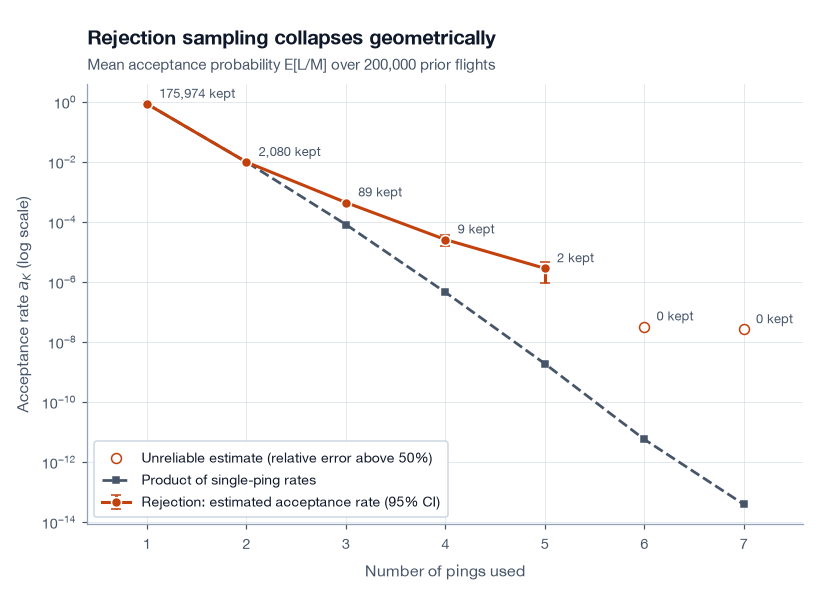

In [26]:
pings = np.arange(1, N_PINGS + 1)
measurable = accept_rate_se < 0.5 * accept_rate  # relative standard error below 50%
fig, ax = plt.subplots(figsize=FIGSIZE_STANDARD)
ax.errorbar(
    pings[measurable],
    accept_rate[measurable],
    yerr=1.96 * accept_rate_se[measurable],
    color=COLOR_POSTERIOR,
    marker="o",
    ms=6.5,
    mec=COLOR_BG,
    capsize=3,
    lw=2,
    label="Rejection: estimated acceptance rate (95% CI)",
)
ax.plot(
    pings[~measurable],
    accept_rate[~measurable],
    color=COLOR_POSTERIOR,
    marker="o",
    ms=6.5,
    mfc=COLOR_BG,
    ls="none",
    label="Unreliable estimate (relative error above 50%)",
)
ax.plot(
    pings,
    independent_rate,
    color=COLOR_TEXT_MUTED,
    ls="--",
    marker="s",
    ms=4.5,
    label="Product of single-ping rates",
)
for k in range(N_PINGS):
    ax.annotate(
        f"{n_accepted[k]:,} kept",
        (pings[k], accept_rate[k]),
        xytext=(8, 4),
        textcoords="offset points",
        fontsize=8.5,
        color=COLOR_TEXT_MUTED,
    )
ax.set_yscale("log")
ax.set_xticks(pings)
ax.margins(x=0.1)  # room for the label of the last ping
ax.set_xlabel("Number of pings used")
ax.set_ylabel("Acceptance rate $a_K$ (log scale)")
set_figure_header(
    ax,
    "Rejection sampling collapses geometrically",
    subtitle=f"Mean acceptance probability E[L/M] over {N_PRIOR_FLIGHTS:,} prior flights",
)
style_legend(ax, loc="lower left")
plt.show()

> **Takeaway.** Each new ping divides the acceptance rate by a large factor: by the sixth ping not one of 200,000 simulated flights survives.

One ping accepts almost every simulated flight, two about 1%, five only a couple out of 200,000, and seven none: collecting even 1,000 exact posterior samples would take on the order of $1000 / a_7$ simulated flights, where $a_7$ is measured properly by the particle filter in Ping 6. Two further details matter:

- Beyond about five pings the estimates of $a_K$ themselves become unreliable, because they rest on a handful of flights. That is the next obstacle in disguise.
- The product of single-ping rates underestimates the joint rate by orders of magnitude. The pings are far from independent (a flight that fits ring 3 is likely to fit ring 4), so the independence shortcut is wrong; the geometric collapse holds either way.

### 2.3 Walk instead of throwing: random-walk Metropolis

> **In plain words**
>
> Instead of throwing darts at the whole map, we drop a walker on a single band and let it take random strides: it always accepts a stride that lands on a spot fitting better than where it stands, accepts a worse spot only some of the time, and otherwise stays put for one more step. Its path is our sample, but consecutive positions are nearly identical, so on this band even the best stride length yields the equivalent of one genuinely fresh position only every few hundred steps, slower than the darts. Worse, a walker with short strides can stay stuck in one stretch of the band without any warning sign.

Once a dart has landed on a ring, why not stay there and *walk* along it? This is the idea of the **Metropolis algorithm** [18], the ancestor of every Markov chain Monte Carlo (MCMC) method. We try it on a single band, before any flight model: the band of the 7th ring under a flat prior over the box of the southern Indian Ocean that Ping 7 uses. The target is $\pi(x) \propto p(z_7 \mid x)$ inside the box, a band about 4,000 km long and a few tens of kilometres wide.

**The rule.** From the current position $x_t$:

1. propose $x' = x_t + s\,\xi$, a jump of typical length $s$ in a uniformly random direction ($\xi \sim \mathcal{N}(0, I_2)$, in kilometres east and north, flown along a great circle);
2. accept it with probability $\alpha(x_t, x') = \min\big(1, \pi(x')/\pi(x_t)\big)$ and set $x_{t+1} = x'$; otherwise set $x_{t+1} = x_t$, counting the current point once more.

For a target that is uniform on a band, $\alpha$ is 1 inside and 0 outside: keep the jump if it stays on the band, stay put if it falls off. Only the ratio $\pi(x')/\pi(x_t)$ appears, so the normalising constant (the evidence) is never needed, and never estimated either.

**Why it targets $\pi$: detailed balance.** The proposal is symmetric, $q(x' \mid x) = q(x \mid x')$, so the probability flow from $x$ to $x' \neq x$ is

$$
\pi(x)\, q(x' \mid x)\, \alpha(x, x') = q(x' \mid x)\, \min\big(\pi(x), \pi(x')\big),
$$

which is symmetric in $x$ and $x'$: in equilibrium, as much probability flows from $x$ to $x'$ as back. Integrating over $x$ shows that if $x_t \sim \pi$ then $x_{t+1} \sim \pi$: $\pi$ is a stationary distribution of the chain, and under mild conditions the chain converges to it from any starting point.

**The price: correlated samples.** Consecutive positions are dependent, so the average $\bar f_n = \frac{1}{n}\sum_{t=1}^{n} f(x_t)$ no longer has variance $\sigma_f^2/n$. With $\rho_k$ the correlation between $f(x_t)$ and $f(x_{t+k})$ in equilibrium, expanding the variance of the sum gives

$$
\mathrm{Var}(\bar f_n) = \frac{\sigma_f^2}{n}\Big(1 + 2\sum_{k=1}^{n-1}\big(1 - \tfrac{k}{n}\big)\rho_k\Big) \approx \frac{\sigma_f^2\,\tau}{n}, \qquad \tau = 1 + 2\sum_{k \ge 1} \rho_k .
$$

A chain of $n$ steps is worth $n_{\mathrm{eff}} = n/\tau$ independent draws: the *integrated autocorrelation time* $\tau$ is the number of steps per independent draw, roughly the time the walker needs to forget where it was. We estimate it from the empirical autocorrelations, summed up to Sokal's automatic window [19].

**The step size is a trade-off.** Small jumps are almost always accepted but crawl; long jumps leave the band. Across the band the target is a Gaussian $\varphi_w$ of ground standard deviation $w$ (11.9 km for ring 7, Ping 1). A jump with $s \gg w$ lands almost uniformly across the band, with density $1/(\sqrt{2\pi}\,s)$, so the acceptance rate is

$$
\bar\alpha \approx \frac{1}{\sqrt{2\pi}\,s}\iint \min\big(\varphi_w(y), \varphi_w(y')\big)\,\mathrm{d}y\,\mathrm{d}y' = \frac{4\,\mathbb{E}|Y|}{\sqrt{2\pi}\,s} = \frac{4}{\pi}\,\frac{w}{s} .
$$

The minimum is the density at whichever of $y, y'$ lies farther from the centre line, hence the double integral $2\int \varphi_w(y)\, 2|y|\,\mathrm{d}y = 4\,\mathbb{E}|Y|$, with $\mathbb{E}|Y| = w\sqrt{2/\pi}$. The acceptance rate falls like $1/s$.

In [27]:
def metropolis_band(lat, lon, step_km, n_steps, rng, k=N_PINGS - 1, box=ARC_BOX):
    """Random-walk Metropolis on pi(x) ∝ p(z_k | x) in a box (flat prior), one chain per start.

    Returns the latitude of every chain at every step, shape (n_steps, chains), and each chain's
    acceptance rate. The jump is isotropic and flown along a great circle: q(x' | x) depends on
    the distance only, so it is symmetric and the acceptance ratio is pi(x') / pi(x).
    """
    (lat_lo, lat_hi), (lon_lo, lon_hi) = box
    log_target = ping_log_likelihood(lat, lon, k)
    path, n_accepted = np.empty((n_steps, lat.size)), np.zeros(lat.size)
    for t in range(n_steps):
        north, east = step_km * rng.standard_normal((2, lat.size))  # jump in km
        new_lat, new_lon = destination(
            lat, lon, np.degrees(np.arctan2(east, north)), np.hypot(north, east)
        )
        inside = (
            (lat_lo <= new_lat) & (new_lat <= lat_hi) & (lon_lo <= new_lon) & (new_lon <= lon_hi)
        )
        new_log_target = np.where(inside, ping_log_likelihood(new_lat, new_lon, k), -np.inf)
        accept = np.log(rng.random(lat.size)) < new_log_target - log_target  # u < pi(x') / pi(x)
        lat, lon = np.where(accept, new_lat, lat), np.where(accept, new_lon, lon)
        log_target = np.where(accept, new_log_target, log_target)
        n_accepted += accept
        path[t] = lat
    return path, n_accepted / n_steps


def integrated_autocorrelation_time(paths, window_factor=SOKAL_WINDOW):
    """tau = 1 + 2 sum_k rho_k of the columns (chains) of `paths`, autocorrelations averaged over
    chains and summed up to the first lag M >= window_factor * tau(M) (Sokal's window). NaN when
    no such lag exists: the chains are too short to measure their own correlation."""
    x = paths - paths.mean()  # centred on the mean of all chains, not on each chain's own mean
    n = len(x)
    power = np.abs(np.fft.rfft(x, 2 * n, axis=0)) ** 2  # zero padding: linear, not circular, lags
    autocov = np.fft.irfft(power, axis=0)[:n].mean(axis=1) / n
    tau = 2.0 * np.cumsum(autocov / autocov[0]) - 1.0  # tau(M) = 1 + 2 (rho_1 + ... + rho_M)
    closed = np.arange(n) >= window_factor * tau
    return tau[np.argmax(closed)] if closed.any() else np.nan

**Proved, now observed.** In two dimensions rejection still works, because the band covers about 1% of the box (as for ring 1 in Ping 1.3), so exact posterior draws are affordable: they start the walkers in equilibrium and check them. For each of 13 step sizes from 1 km to 3,000 km, we run 80 independent chains of 10,000 steps and measure:

- the acceptance rate, against the long-jump law $\frac{4}{\pi}\frac{w}{s}$;
- $n_{\mathrm{eff}}$ in two independent ways, with $f$ = latitude: from the spread of the 80 chain averages, $n_{\mathrm{eff}} = \sigma_f^2 / \widehat{\mathrm{Var}}(\bar f_n)$, and from the autocorrelations, $n / \hat\tau$.

In [28]:
t_cell = time.perf_counter()
rng = make_rng(2, 3)
band_sd_km = np.median(ring_band(N_PINGS - 1, PING_BTO_SD_US[-1])[3])  # w: ground sd of the band
dart_lat, dart_lon = sample_flat_prior(MCMC_DARTS, rng, box=ARC_BOX)
hit = rng.random(MCMC_DARTS) < compatibility(dart_lat, dart_lon, k=N_PINGS - 1)  # rejection in 2-D
exact_lat, exact_lon = dart_lat[hit], dart_lon[hit]
exact_q05, exact_q95 = np.quantile(exact_lat, [0.05, 0.95])
print(f"Rejection in 2-D: {hit.sum():,} exact draws from {MCMC_DARTS:,} darts ({hit.mean():.2%})")
print(
    f"Band of ring 7: w = {band_sd_km:.1f} km;"
    f" 90% of the target between {exact_q05:.1f} and {exact_q95:.1f} deg"
)

t_start = time.perf_counter()
chain_means, acceptance, n_over_tau = [], [], []
for step_km in MCMC_STEP_SIZES_KM:
    start = rng.choice(exact_lat.size, MCMC_CHAINS, replace=False)  # walkers start in equilibrium
    path, accepted = metropolis_band(exact_lat[start], exact_lon[start], step_km, MCMC_STEPS, rng)
    chain_means.append(path.mean(axis=0))
    acceptance.append(accepted.mean())
    n_over_tau.append(MCMC_STEPS / integrated_autocorrelation_time(path))
chain_means, acceptance, n_over_tau = (
    np.array(chain_means),
    np.array(acceptance),
    np.array(n_over_tau),
)
n_eff = exact_lat.var() / chain_means.var(axis=1, ddof=1)
long_jump_law = np.minimum(1.0, 4.0 / np.pi * band_sd_km / MCMC_STEP_SIZES_KM)
n_chains = MCMC_CHAINS * len(MCMC_STEP_SIZES_KM)
print(f"{n_chains:,} chains of {MCMC_STEPS:,} steps in {time.perf_counter() - t_start:.0f} s\n")
print("step (km)   accepted   (4/pi) w/s   n_eff from chain spread   n / tau")
for s, acc, law, ne, nt in zip(
    MCMC_STEP_SIZES_KM, acceptance, long_jump_law, n_eff, n_over_tau, strict=True
):
    law_text = f"{law:10.1%}" if law < 1.0 else f"{'-':>10s}"  # the law needs jumps longer than w
    nt_text = f"{nt:7.1f}" if np.isfinite(nt) else "  chain too short to tell"
    print(f"{s:9,.0f}   {acc:8.1%}   {law_text}   {ne:23.1f}   {nt_text}")

best = np.argmax(n_eff)
best_mean, best_se = chain_means[best].mean(), chain_means[best].std(ddof=1) / np.sqrt(MCMC_CHAINS)
exact_se = exact_lat.std() / np.sqrt(exact_lat.size)
print(
    f"\nBest step {MCMC_STEP_SIZES_KM[best]:,.0f} km:"
    f" one independent draw every {MCMC_STEPS / n_eff[best]:,.0f} steps;"
    f" rejection: one every {1 / hit.mean():,.0f} darts"
)
print(
    f"Mean latitude, all chains of the best walker: {best_mean:.2f} ± {best_se:.2f} deg;"
    f" exact draws: {exact_lat.mean():.2f} ± {exact_se:.2f} deg"
)

trace_start = np.argmin(
    np.abs(exact_lat - MCMC_TRACE_START_LAT_DEG)
)  # exact draw near the north end
n_traces = len(MCMC_TRACE_STEPS_KM)
traces, trace_acceptance = metropolis_band(
    np.full(n_traces, exact_lat[trace_start]),
    np.full(n_traces, exact_lon[trace_start]),
    np.array(MCMC_TRACE_STEPS_KM),
    MCMC_STEPS,
    rng,
)
for s, trace in zip(MCMC_TRACE_STEPS_KM, traces.T, strict=True):
    print(
        f"Walker with {s:,.0f} km steps from {exact_lat[trace_start]:.1f} deg:"
        f" visited {trace.min():.1f} to {trace.max():.1f} deg"
    )
metropolis_s = time.perf_counter() - t_cell

Rejection in 2-D: 9,731 exact draws from 1,000,000 darts (0.97%)
Band of ring 7: w = 11.9 km; 90% of the target between -42.1 and -19.6 deg


1,040 chains of 10,000 steps in 8 s

step (km)   accepted   (4/pi) w/s   n_eff from chain spread   n / tau
        1      97.3%            -                       1.0     chain too short to tell
        2      94.8%            -                       1.1     chain too short to tell
        4      89.9%            -                       0.9     chain too short to tell
        7      80.8%            -                       1.1     chain too short to tell
       14      65.3%            -                       1.3     chain too short to tell
       28      44.5%        54.0%                       1.3     chain too short to tell
       55      25.9%        27.7%                       2.2     chain too short to tell
      107      13.7%        14.2%                       3.2     chain too short to tell
      208       6.9%         7.3%                       5.1       5.2
      405       3.4%         3.7%                       8.8       9.2
      790       1.6%         1.9%                

Walker with 3 km steps from -20.0 deg: visited -21.2 to -18.2 deg
Walker with 30 km steps from -20.0 deg: visited -36.6 to -18.0 deg
Walker with 400 km steps from -20.0 deg: visited -42.7 to -18.8 deg


In [29]:
print_card(
    "Ping 2.3, random-walk Metropolis on the band of ring 7",
    simulated="Metropolis chains targeting the ping-7 likelihood under a flat prior over the box"
    " of Ping 7, started from exact draws obtained by rejection in two dimensions",
    size=f"{len(MCMC_STEP_SIZES_KM)} step sizes × {MCMC_CHAINS} chains × {MCMC_STEPS:,} steps,"
    f" plus {n_traces} walkers drawn in full; {MCMC_DARTS:,} darts for the exact draws",
    settings=f"steps from {MCMC_STEP_SIZES_KM[0]:,.0f} to {MCMC_STEP_SIZES_KM[-1]:,.0f} km;"
    f" band sd w = {band_sd_km:.1f} km; Sokal window {SOKAL_WINDOW:g}; stream make_rng(2, 3)",
    seconds=metropolis_s,
    result=f"best step {MCMC_STEP_SIZES_KM[best]:,.0f} km: one independent draw every"
    f" {MCMC_STEPS / n_eff[best]:,.0f} steps, against one exact draw every"
    f" {1 / hit.mean():,.0f} darts for rejection",
)

What we actually ran · Ping 2.3, random-walk Metropolis on the band of ring 7
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   Metropolis chains targeting the ping-7 likelihood under a flat prior over the box of
            Ping 7, started from exact draws obtained by rejection in two dimensions
Size        13 step sizes × 80 chains × 10,000 steps, plus 3 walkers drawn in full; 1,000,000
            darts for the exact draws
Settings    steps from 1 to 3,000 km; band sd w = 11.9 km; Sokal window 5; stream make_rng(2, 3)
Run time    8.47 s
Result      best step 1,539 km: one independent draw every 550 steps, against one exact draw
            every 103 darts for rejection


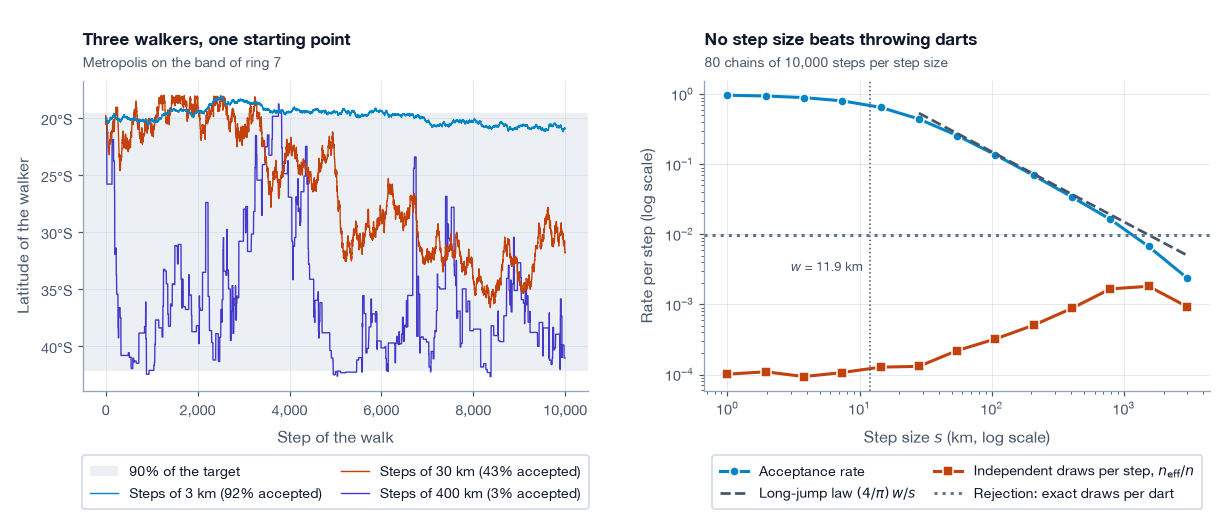

In [30]:
fig, (ax_trace, ax_step) = plt.subplots(1, 2, figsize=FIGSIZE_TWO_PANEL)
ax_trace.axhspan(
    exact_q05, exact_q95, color=COLOR_GRID, alpha=0.35, lw=0, label="90% of the target"
)
walker_colors = (COLOR_PARTICLES, COLOR_POSTERIOR, COLOR_SEARCH_AREA)
walkers = zip(MCMC_TRACE_STEPS_KM, traces.T, trace_acceptance, walker_colors, strict=True)
for i, (s, trace, acc, color) in enumerate(walkers):  # the smallest steps are drawn on top
    ax_trace.plot(
        trace,
        color=color,
        lw=0.9,
        zorder=2 + n_traces - i,
        label=f"Steps of {s:,.0f} km ({acc:.0%} accepted)",
    )
ax_trace.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: format_lat(v)))
ax_trace.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax_trace.set_xlabel("Step of the walk")
ax_trace.set_ylabel("Latitude of the walker")
set_figure_header(
    ax_trace, "Three walkers, one starting point", subtitle="Metropolis on the band of ring 7"
)
style_legend(ax_trace, loc="below")

ax_step.plot(
    MCMC_STEP_SIZES_KM,
    acceptance,
    color=COLOR_PARTICLES,
    marker="o",
    ms=6,
    mec=COLOR_BG,
    lw=2,
    label="Acceptance rate",
)
long_jumps = long_jump_law < 1.0
ax_step.plot(
    MCMC_STEP_SIZES_KM[long_jumps],
    long_jump_law[long_jumps],
    color=COLOR_TEXT_MUTED,
    ls="--",
    label=r"Long-jump law $(4/\pi)\,w/s$",
)
ax_step.plot(
    MCMC_STEP_SIZES_KM,
    n_eff / MCMC_STEPS,
    color=COLOR_POSTERIOR,
    marker="s",
    ms=6,
    mec=COLOR_BG,
    lw=2,
    label=r"Independent draws per step, $n_{\mathrm{eff}}/n$",
)
ax_step.axhline(
    hit.mean(), color=COLOR_PRIOR, ls=":", lw=2, label="Rejection: exact draws per dart"
)
ax_step.axvline(band_sd_km, color=COLOR_TEXT_MUTED, ls=":", lw=1)
ax_step.annotate(
    f"$w$ = {band_sd_km:.1f} km",
    (band_sd_km, 0.4),
    xycoords=ax_step.get_xaxis_transform(),
    xytext=(-4, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    fontsize=8.5,
    color=COLOR_TEXT_MUTED,
)
ax_step.set_xscale("log")
ax_step.set_yscale("log")
ax_step.set_xlabel(r"Step size $s$ (km, log scale)")
ax_step.set_ylabel("Rate per step (log scale)")
set_figure_header(
    ax_step,
    "No step size beats throwing darts",
    subtitle=f"{MCMC_CHAINS} chains of {MCMC_STEPS:,} steps per step size",
)
style_legend(ax_step, loc="below")
fig.tight_layout()
plt.show()

> **Takeaway.** Small steps are accepted but crawl, long jumps are almost always rejected: even the best walker yields one independent position every 550 steps, while throwing darts yields an exact one every 100.

**What the walkers show.**

- The acceptance rate follows the long-jump law $\frac{4}{\pi}\frac{w}{s}$ as soon as $s$ is a few times $w$, until the longest jumps also start leaving the box.
- Wherever the chains are long enough to measure their own correlation, the two estimates of $n_{\mathrm{eff}}$ agree: $\mathrm{Var}(\bar f_n) \approx \sigma_f^2 \tau / n$ holds. For small steps the autocorrelation sum never settles: a chain that has not explored cannot even measure how badly it mixes.
- The best walker takes jumps of about 1,500 km and rejects more than 99% of them. In two dimensions only one direction is narrow, so the rare long jump that lands back on the band carries the walker far along it.
- Rejection still wins on a single band, by a factor of five. The chains do target the right distribution: the mean latitude of all chains of the best walker, 31.9°S ± 0.2°, agrees with that of the exact draws, 32.3°S, within two standard errors. They are just slow.

**Nothing guarantees exploration.** In 10,000 steps the walker with 3 km steps never left the northern end of the band, between 18°S and 21°S, although the target extends to 42°S. Its histogram would describe a confident and wrong posterior, and nothing inside the chain warns of it: only chains started far apart, or knowing the answer as we do here, reveal the problem.

**Why the rest of this notebook is sequential.** The cost of a walk depends on the *shape* of the target (how long and how thin), not on how small it is compared with the prior; the cost of rejection is the reverse. That is why MCMC is the workhorse of Bayesian statistics. Our real target, however, is a whole flight path that must sit inside seven bands at once:

- **Dimension.** A jump of length $s$ in every direction lands inside all seven bands with probability of order $(w/s)^7$, so the long-jump escape of two dimensions is gone. Steps must shrink to the band width, and a random walk with steps of size $w$ needs of the order of $(L/w)^2$ steps to cross a ridge of length $L$: tens of thousands for $L \approx 1{,}750$ km and $w \approx 10$ km, for every independent path.
- **Sequential data.** The pings arrive one after the other. Sequential Monte Carlo (Pings 3 to 5) absorbs them one at a time and recycles the work done for the previous ones.
- **Evidence.** Metropolis never estimates the evidence (only ratios of $\pi$ enter the rule); sequential importance sampling gets it for free (Ping 5), and Epilogue A uses it to test assumptions.
- **The two ideas combine.** Particle filters often add Metropolis moves after resampling to rejuvenate the cloud (*resample-move* [20]), and particle MCMC runs a whole particle filter inside a Metropolis chain [21].

---

## Ping 3 — Weigh, don't discard

> **In plain words**
>
> Keeping only the flights that survive a fit-based keep-or-discard check wastes nearly all the work we did, including many routes that came close. Instead of discarding any flight, we give every one a weight proportional to how well it fits the rings, turning each estimate into a weighted average, like a vote where better-fitting flights count more. Using the very same simulated flights, this estimates the same quantity as discarding, with less random error; still, weights can only rescale routes our flight model can produce, never invent one it rules out.

> **The obstacle.** Rejection sampling throws away almost every flight we paid to simulate, including the many that *nearly* fit, and a random walk pays for each independent sample with hundreds of correlated steps. Instead of a yes/no verdict, can we keep every flight and simply trust some more than others?

### 3.1 The importance-sampling identity

Let $\pi(x) = p(x \mid z_{1:K})$ be the target and $q(x)$ any *proposal* we can sample from, with $q(x) > 0$ wherever $\pi(x) f(x) \neq 0$. Multiplying and dividing by $q$:

$$
\mathbb{E}_\pi[f(X)] = \int f(x)\, \frac{\pi(x)}{q(x)}\, q(x)\, \mathrm{d}x = \mathbb{E}_q\big[f(X)\, w(X)\big], \qquad w(x) = \frac{\pi(x)}{q(x)} .
$$

We only know $\pi$ up to its normalising constant: $\pi(x) = \tilde\pi(x)/Z$ with $\tilde\pi(x) = p(x)\,L(x)$. Since $Z = \mathbb{E}_q[\tilde w(X)]$ for $\tilde w = \tilde\pi / q$, the ratio of two Monte Carlo averages estimates the integral without ever computing $Z$:

$$
\hat I_N = \frac{\sum_{i=1}^{N} \tilde w^{(i)} f\big(x^{(i)}\big)}{\sum_{j=1}^{N} \tilde w^{(j)}} = \sum_{i=1}^{N} W^{(i)} f\big(x^{(i)}\big), \qquad W^{(i)} = \frac{\tilde w^{(i)}}{\sum_j \tilde w^{(j)}} .
$$

- **Consistent.** Numerator and denominator converge to $Z\,\mathbb{E}_\pi[f]$ and $Z$ (law of large numbers), so their ratio converges to $\mathbb{E}_\pi[f]$.
- **Slightly biased.** A ratio of unbiased estimators is not unbiased; the bias is $O(1/N)$, negligible next to the $O(1/\sqrt{N})$ noise.
- **Our proposal is the prior.** With $q = p$ (simulate flights from the motion model), the prior cancels and the weight of a flight is simply its likelihood: $\tilde w = L(x) = \prod_{k} p(z_k \mid x_k)$.

**A sampler only finds what its proposal can reach.** If $q(x) = 0$ where $\pi(x) > 0$, those paths are never simulated and no weight can bring them back: importance sampling silently misses regions where the posterior lives. This bites whenever a proposal is narrower than the prior. Here the proposal is the prior itself, so the posterior also vanishes wherever $q$ does: excluding northern headings is a modelling choice (the southern-route assumption), and no sampler, however much computation it gets, can overturn it.

The weights must be computed in log space: a flight 40 standard deviations off one ring has a likelihood of order $e^{-800}$, which underflows to zero in double precision. Subtracting the largest log-weight before exponentiating (the *log-sum-exp* trick) keeps every ratio exact.

In [31]:
def log_sum_exp(a):
    """log(sum(exp(a))) without overflow or underflow."""
    a_max = a.max()
    return a_max + np.log(np.sum(np.exp(a - a_max)))


def normalize(log_w):
    """Self-normalised weights W = w / sum(w), computed from log-weights."""
    return np.exp(log_w - log_sum_exp(log_w))


def weighted_quantile(x, weights, q):
    """Quantile(s) q of the weighted sample sum_i W_i delta(x_i)."""
    order = np.argsort(x)
    cdf = np.cumsum(weights[order])
    return np.interp(q, cdf - 0.5 * weights[order], x[order])


def posterior_grid(lat, lon, weights, lat_edges, lon_edges):
    """Weighted 2-D histogram of a cloud: probability mass of each cell and density per km²."""
    mass, _, _ = np.histogram2d(lat, lon, bins=[lat_edges, lon_edges], weights=weights)
    return mass, mass / cell_areas_km2(lat_edges, lon_edges)

### 3.2 Same answer, fraction of the cost

**Check.** After $K$ pings rejection sampling still accepts a few flights, so we can compare both estimators of the same posterior quantity, the mean latitude of the aircraft at the time of ping $K$, using the *same* simulated flights. We split them into independent batches to measure each estimator's spread.

In [32]:
t_start = time.perf_counter()
lat_at_check = prior_states[K_CHECK - 1, :, LAT]
accepted = uniforms < accept_prob[K_CHECK - 1]
log_w_check = prior_log_lik[:K_CHECK].sum(axis=0)

reject_mean = lat_at_check[accepted].mean()
reject_ci = 1.96 * lat_at_check[accepted].std(ddof=1) / np.sqrt(accepted.sum())
is_mean = np.sum(normalize(log_w_check) * lat_at_check)

batches = np.array_split(np.arange(N_PRIOR_FLIGHTS), N_BATCHES)
batch_reject = [lat_at_check[b][accepted[b]].mean() for b in batches]
batch_is = [np.sum(normalize(log_w_check[b]) * lat_at_check[b]) for b in batches]
spread_reject, spread_is = np.std(batch_reject, ddof=1), np.std(batch_is, ddof=1)
is_check_s = time.perf_counter() - t_start
print(f"Posterior mean latitude at ping {K_CHECK}, from the same {N_PRIOR_FLIGHTS:,} flights:")
print(f"  rejection ({accepted.sum():,} accepted): {reject_mean:.3f} ± {reject_ci:.3f} deg")
print(f"  importance sampling (all flights):      {is_mean:.3f} deg")
print(
    f"Spread across {N_BATCHES} batches: rejection {spread_reject:.3f} deg, IS {spread_is:.3f} deg"
)
print(f"Flights needed by rejection to match IS precision: x{(spread_reject / spread_is) ** 2:.1f}")

Posterior mean latitude at ping 2, from the same 200,000 flights:
  rejection (2,080 accepted): 1.319 ± 0.102 deg
  importance sampling (all flights):      1.317 deg
Spread across 100 batches: rejection 0.568 deg, IS 0.477 deg
Flights needed by rejection to match IS precision: x1.4


In [33]:
print_card(
    "Ping 3.2, importance sampling against rejection",
    simulated=f"no new flights: the {N_PRIOR_FLIGHTS:,} prior flights of Ping 2, either weighted"
    f" by the likelihood of pings 1 to {K_CHECK} (importance sampling) or kept by rejection",
    size=f"{N_PRIOR_FLIGHTS:,} flights, split into {N_BATCHES} independent batches of"
    f" {N_PRIOR_FLIGHTS // N_BATCHES:,} to measure each estimator's spread",
    settings="proposal = prior, so a flight's weight is its likelihood, computed in log space;"
    " same flights and uniforms as Ping 2.2",
    seconds=is_check_s,
    result=f"mean latitude at ping {K_CHECK}: rejection {reject_mean:.3f} deg, importance"
    f" sampling {is_mean:.3f} deg; spread across batches {spread_reject:.3f} against"
    f" {spread_is:.3f} deg",
)

What we actually ran · Ping 3.2, importance sampling against rejection
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   no new flights: the 200,000 prior flights of Ping 2, either weighted by the
            likelihood of pings 1 to 2 (importance sampling) or kept by rejection
Size        200,000 flights, split into 100 independent batches of 2,000 to measure each
            estimator's spread
Settings    proposal = prior, so a flight's weight is its likelihood, computed in log space;
            same flights and uniforms as Ping 2.2
Run time    0.01 s
Result      mean latitude at ping 2: rejection 1.319 deg, importance sampling 1.317 deg; spread
            across batches 0.568 against 0.477 deg


The two estimators agree, as the identity promises: rejection keeps a couple of thousand flights, importance sampling uses all of them and is more precise for the same simulation cost (rejection would need about 1.4 times as many flights to match it). Ping 4 shows that the gap widens with every ping, because the acceptance rate collapses geometrically while importance sampling keeps every flight. Weighing does not escape the curse, though; it only postpones it.

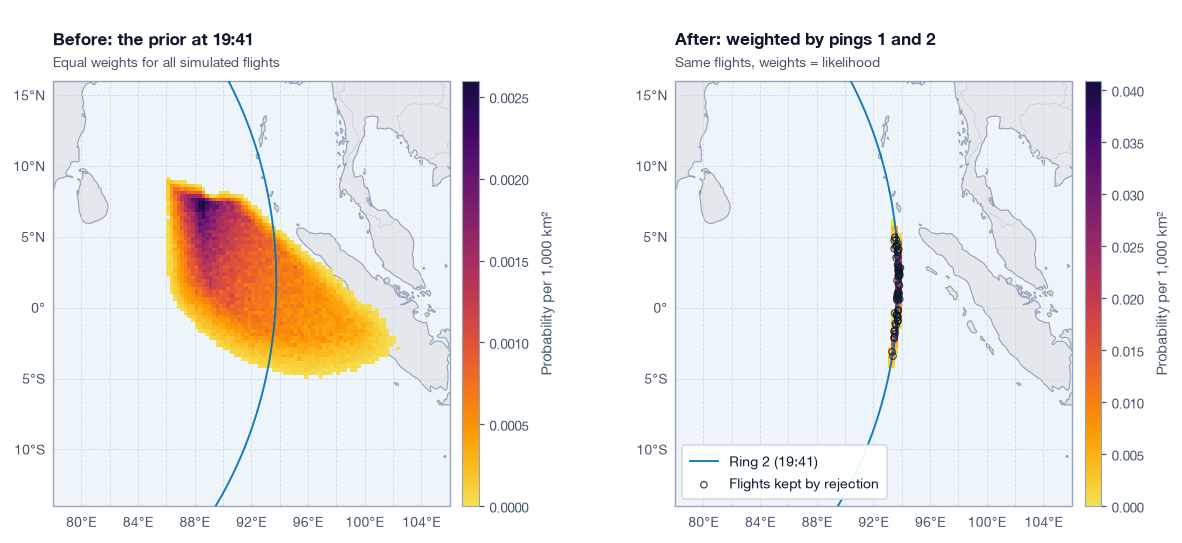

In [34]:
turn_lat_edges, turn_lon_edges = extent_edges(TURN_EXTENT, MAP_CELL_DEG)
lon_at_check = prior_states[K_CHECK - 1, :, LON]
panels = (
    (
        "Before: the prior at 19:41",
        "Equal weights for all simulated flights",
        np.full(N_PRIOR_FLIGHTS, 1 / N_PRIOR_FLIGHTS),
    ),
    (
        "After: weighted by pings 1 and 2",
        "Same flights, weights = likelihood",
        normalize(log_w_check),
    ),
)
fig, axes = plt.subplots(
    1, 2, figsize=FIGSIZE_TWO_PANEL, subplot_kw={"projection": ccrs.PlateCarree()}
)
for ax, (title, subtitle, weights) in zip(axes, panels, strict=True):
    make_cartopy_map(TURN_EXTENT, ax=ax)
    _, density = posterior_grid(lat_at_check, lon_at_check, weights, turn_lat_edges, turn_lon_edges)
    draw_density(ax, turn_lat_edges, turn_lon_edges, 1e3 * density, "Probability per 1,000 km²")
    draw_ring(ax, *rings[K_CHECK - 1], label="Ring 2 (19:41)")
    set_figure_header(ax, title, subtitle)
kept = np.flatnonzero(accepted)[:REJECTION_DOTS_SHOWN]
axes[1].scatter(
    lon_at_check[kept],
    lat_at_check[kept],
    s=18,
    facecolors="none",
    edgecolors=COLOR_TEXT,
    linewidths=0.8,
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    label="Flights kept by rejection",
    zorder=6,
)
style_legend(axes[1], loc="lower left")
fig.tight_layout()
plt.show()

> **Takeaway.** Weighting turns the diffuse prior cloud into a thin band along ring 2 without discarding a single flight; the flights kept by rejection fall exactly where the weights are large.

---

## Ping 4 — The weights collapse

> **In plain words**
>
> Each new ping multiplies every flight's weight by its fit to one more ring, so the gaps between flights multiply from ping to ping: after seven pings, the single best flight holds about three quarters of the total weight. We measure the damage by estimating how many equally weighted flights the weighted set is worth, and our two hundred thousand flights end up worth about two. Weighing still beats discarding, but on its own it only postpones the collapse.

> **The obstacle.** Keep multiplying the weights by one likelihood per ping and look at them: after a few pings, a handful of flights carry essentially all the weight. Our hundreds of thousands of simulated flights are, in effect, a few.

### 4.1 Effective sample size

How many independent posterior samples are our $N$ weighted flights worth? Ping 2.3 asked the same question of a correlated chain; for weighted samples the standard answer is the **effective sample size**

$$
\mathrm{ESS} = \frac{1}{\sum_{i=1}^{N} \big(W^{(i)}\big)^2} = \frac{\big(\sum_i w^{(i)}\big)^2}{\sum_i \big(w^{(i)}\big)^2} \in [1, N].
$$

It equals $N$ when all weights are equal and $1$ when one flight holds all the weight. Writing $\bar w$ and $s^2$ for the mean and the (biased, $1/N$) variance of the raw weights, $\sum_i w_i^2 = N(s^2 + \bar w^2)$ and $(\sum_i w_i)^2 = N^2 \bar w^2$, hence the exact identity

$$
\mathrm{ESS} = \frac{N}{1 + s^2 / \bar w^2} = \frac{N}{1 + \widehat{\mathrm{CV}}^2} .
$$

The ESS is $N$ divided by one plus the squared coefficient of variation of the weights: uneven weights mean fewer effective samples. Kong's heuristic [9] makes the name precise: the variance of the self-normalised estimator is roughly that of an ordinary Monte Carlo average over $\mathrm{ESS}$ independent samples.

**Weighing always beats discarding.** Because $L \le M$, $\sum_i L_i^2 \le M \sum_i L_i$, so

$$
\mathrm{ESS} = \frac{\big(\sum_i L_i\big)^2}{\sum_i L_i^2} \;\ge\; \sum_{i=1}^{N} \frac{L_i}{M},
$$

and the right-hand side is the expected number of flights rejection sampling would accept. With the same simulations, importance sampling is never worth fewer samples than rejection.

In [35]:
def effective_sample_size(weights):
    """ESS = 1 / sum(W_i^2) for normalised weights: 1 (one particle) <= ESS <= N (equal weights)."""
    return 1.0 / np.sum(weights**2)

**Check.** We apply the importance weights of Ping 3 to the prior flights of Ping 2, one ping at a time, and track the ESS, the exact identity above and the inequality against rejection sampling.

In [36]:
t_start = time.perf_counter()
log_w_by_ping = np.cumsum(prior_log_lik, axis=0)  # importance log-weights after K = 1..7 pings
weights_by_ping = [normalize(log_w) for log_w in log_w_by_ping]
ess_by_ping = np.array([effective_sample_size(w) for w in weights_by_ping])
top_share = np.array([w.max() for w in weights_by_ping])

w_raw = np.exp(log_w_by_ping[0] - log_w_by_ping[0].max())
identity_gap = abs(ess_by_ping[0] - N_PRIOR_FLIGHTS / (1 + w_raw.var() / w_raw.mean() ** 2))
ess_check_s = time.perf_counter() - t_start
print(f"Identity ESS = N / (1 + CV^2) holds to {identity_gap:.1e} (absolute)")
print(" K       ESS   ESS/N      expected rejection acceptances   weight of the best flight")
for k in range(N_PINGS):
    print(
        f"{k + 1:2d}  {ess_by_ping[k]:9.1f}  {ess_by_ping[k] / N_PRIOR_FLIGHTS:.1e}"
        f"      {accept_prob[k].sum():12.3f}                  {top_share[k]:.1%}"
    )

Identity ESS = N / (1 + CV^2) holds to 2.0e-10 (absolute)
 K       ESS   ESS/N      expected rejection acceptances   weight of the best flight
 1   194052.1  9.7e-01        176063.866                  0.0%
 2     3204.2  1.6e-02          2027.453                  0.0%
 3      207.3  1.0e-03            91.384                  1.1%
 4       23.3  1.2e-04             5.326                  9.5%
 5        8.5  4.2e-05             0.585                  19.8%
 6        2.0  1.0e-05             0.007                  64.6%
 7        1.7  8.6e-06             0.005                  73.8%


In [37]:
print_card(
    "Ping 4.1, effective sample size of the importance weights",
    simulated=f"no new flights: the importance weights of the {N_PRIOR_FLIGHTS:,} prior flights"
    f" of Ping 2 after K = 1 to {N_PINGS} pings",
    size=f"{N_PRIOR_FLIGHTS:,} flights × {N_PINGS} pings",
    settings="proposal = prior; weights normalised in log space (log-sum-exp)",
    seconds=ess_check_s,
    result=f"ESS falls from {ess_by_ping[0]:,.0f} after one ping to {ess_by_ping[-1]:.1f} after"
    f" seven, when the best flight holds {top_share[-1]:.1%} of the weight",
)

What we actually ran · Ping 4.1, effective sample size of the importance weights
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   no new flights: the importance weights of the 200,000 prior flights of Ping 2 after
            K = 1 to 7 pings
Size        200,000 flights × 7 pings
Settings    proposal = prior; weights normalised in log space (log-sum-exp)
Run time    0.02 s
Result      ESS falls from 194,052 after one ping to 1.7 after seven, when the best flight holds
            73.8% of the weight


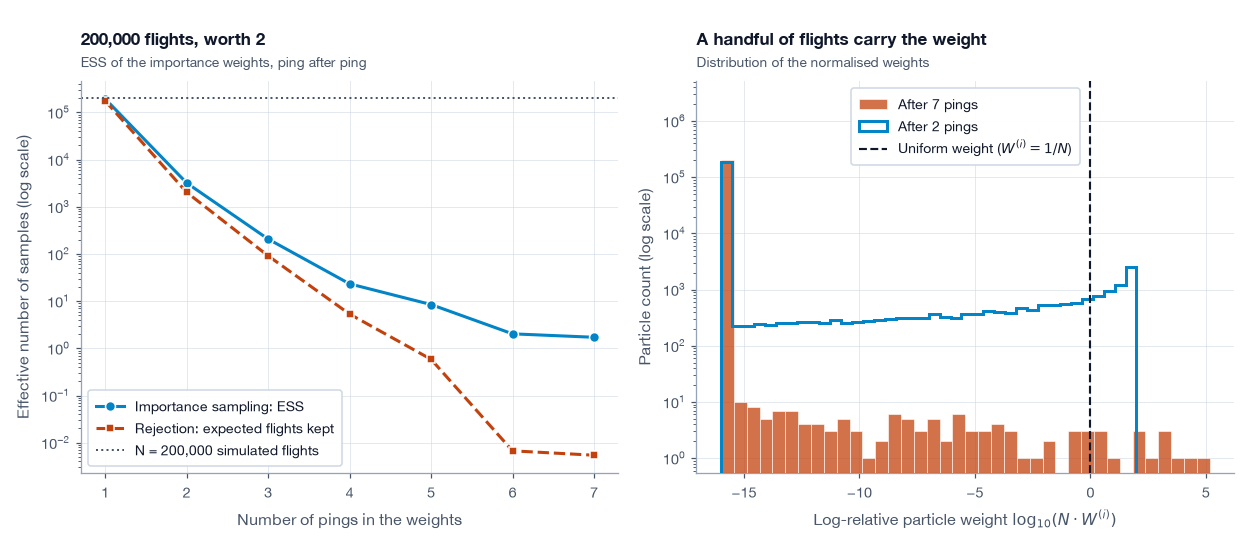

In [38]:
fig, (ax_ess, ax_hist) = plt.subplots(1, 2, figsize=FIGSIZE_TWO_PANEL)
ax_ess.semilogy(
    pings,
    ess_by_ping,
    color=COLOR_PARTICLES,
    marker="o",
    ms=6.5,
    mec=COLOR_BG,
    lw=2,
    label="Importance sampling: ESS",
)
ax_ess.semilogy(
    pings,
    accept_prob.sum(axis=1),
    color=COLOR_POSTERIOR,
    marker="s",
    ms=5.5,
    mec=COLOR_BG,
    lw=2,
    ls="--",
    label="Rejection: expected flights kept",
)
ax_ess.axhline(
    N_PRIOR_FLIGHTS,
    color=COLOR_TEXT_MUTED,
    ls=":",
    lw=1.3,
    label=f"N = {N_PRIOR_FLIGHTS:,} simulated flights",
)
ax_ess.set_xticks(pings)
ax_ess.set_xlabel("Number of pings in the weights")
ax_ess.set_ylabel("Effective number of samples (log scale)")
set_figure_header(
    ax_ess,
    f"{N_PRIOR_FLIGHTS:,} flights, worth {ess_by_ping[-1]:.0f}",
    subtitle="ESS of the importance weights, ping after ping",
)
style_legend(ax_ess, loc="lower left")
plot_weight_histogram(
    weights_by_ping[-1],
    compare_weights=weights_by_ping[K_CHECK - 1],
    labels=("After 7 pings", f"After {K_CHECK} pings"),
    title="A handful of flights carry the weight",
    subtitle="Distribution of the normalised weights",
    ax=ax_hist,
)
fig.tight_layout()
plt.show()

> **Takeaway.** Ping after ping the effective sample size falls geometrically, while the weight distribution splits into a crowd of negligible flights and a few giants.

The ESS falls from almost $N$ after the first ping to about two after all seven: 200,000 simulated flights are worth two independent ones, and the single best flight carries about three quarters of the total weight. The identity holds to rounding error, and in every row the ESS exceeds the expected number of rejection acceptances, as derived; after seven pings importance sampling still has about two effective samples where rejection would keep half a percent of one flight.

### 4.2 Why the weights degenerate

The log-weight of a flight is a sum over pings, $\log w = \sum_{k=1}^{K} \log p(z_k \mid x_k)$, so its spread grows with every ping. A toy model shows the speed of the collapse. Suppose the normalised incremental weights $g_k = p(z_k \mid x_k) / \mathbb{E}[p(z_k \mid x_k)]$ were independent across pings with $\mathbb{E}[g_k] = 1$ and $\mathbb{E}[g_k^2] = 1 + c$. Then $w_K = \prod_k g_k$ has $\mathbb{E}[w_K] = 1$ and $\mathbb{E}[w_K^2] = (1 + c)^K$, and since $\mathrm{ESS} \approx N\, \mathbb{E}[w]^2 / \mathbb{E}[w^2]$,

$$
\frac{\mathrm{ESS}}{N} \approx (1 + c)^{-K} \xrightarrow[K \to \infty]{} 0 \quad \text{geometrically.}
$$

The general result is due to Kong, Liu and Wong [10]: in sequential importance sampling, the variance of the weights, averaged over the possible data, can only grow with time. For one fixed data set the ESS can occasionally go up, but the trend is down, and nothing can stop it except changing the proposal or the particles themselves.

---

## Ping 5 — Resample

> **In plain words**
>
> Rather than keep flying thousands of simulated aircraft that no longer matter, we renew the population whenever the weights become too uneven: each flight gets a number of copies proportional, on average, to its weight, so promising flights are cloned, hopeless ones disappear, and every copy restarts with an equal weight. Copying adds no information, but the copies soon separate because each keeps turning and changing speed at random, so the computing effort follows the flights that still fit. Repeated ping after ping, this fly, weigh and copy loop is the method behind every later answer; its price is that, traced back in time, the final flights all descend from a few hundred early ancestors.

> **The obstacle.** We keep paying to fly thousands of simulated aircraft whose weight is $10^{-30}$. Better: as soon as the weights become uneven, *clone* the promising flights, abandon the hopeless ones, and let the random turns of the motion model spread the clones apart again.

### 5.1 Resampling without bias

**Multinomial resampling.** Draw $N$ indices independently, index $i$ with probability $W^{(i)}$, and give every copy weight $1/N$. The offspring counts $(N_1, \dots, N_N)$ follow a multinomial distribution, so $\mathbb{E}[N_i] = N W^{(i)}$ and, conditionally on the particles,

$$
\mathbb{E}\Big[\frac{1}{N} \sum_{i=1}^{N} N_i\, f\big(x^{(i)}\big)\Big] = \sum_{i=1}^{N} W^{(i)} f\big(x^{(i)}\big).
$$

Resampling therefore introduces **no bias**: it only adds noise, $\mathrm{Var}(N_i) = N W^{(i)}(1 - W^{(i)})$.

**Systematic resampling.** Draw a single $U \sim \mathcal{U}[0, 1)$ and use the $N$ evenly spaced pointers $u_j = (U + j - 1)/N$: particle $i$ is copied once for every pointer that falls in its slice $[C_{i-1}, C_i)$ of the cumulative weights. Each pointer is uniform on its own interval of length $1/N$, so the expected number of pointers in a slice of length $W^{(i)}$ is again $\mathbb{E}[N_i] = N W^{(i)}$: still unbiased. But now $N_i$ can only be $\lfloor N W^{(i)} \rfloor$ or $\lceil N W^{(i)} \rceil$, which usually adds much less noise (usually, not always [12]). It also costs a single random number.

Both methods are the same inverse-CDF lookup, fed with different pointers.

In [39]:
def resample_with_pointers(weights, pointers):
    """Index i of the slice [C_{i-1}, C_i) of the cumulative weights containing each pointer."""
    cdf = np.cumsum(weights)
    cdf[-1] = 1.0  # round-off guard: the last slice must end exactly at 1
    return np.searchsorted(cdf, pointers, side="right")


def multinomial_resample(weights, rng):
    """N independent pointers: offspring counts are Multinomial(N, W)."""
    return resample_with_pointers(weights, rng.random(len(weights)))


def systematic_resample(weights, rng):
    """N evenly spaced pointers sharing a single uniform: u_j = (U + j - 1) / N."""
    n = len(weights)
    return resample_with_pointers(weights, (rng.random() + np.arange(n)) / n)

**Check.** We take a small weighted set of flights, resample it many times with each method, and compare the average offspring counts with $N W^{(i)}$, and the resampled estimate of the mean latitude with the weighted estimate it should reproduce.

In [40]:
t_start = time.perf_counter()
demo_idx = np.arange(RESAMPLE_DEMO_N)  # a small weighted set of prior flights
demo_w = normalize(prior_log_lik[:K_CHECK, demo_idx].sum(axis=0))
demo_lat = prior_states[K_CHECK - 1, demo_idx, LAT]
target = np.sum(demo_w * demo_lat)
rng = make_rng(5, 0)
resampling_noise_sd = {}  # sd of the resampled mean latitude, per scheme
for name, method in (("multinomial", multinomial_resample), ("systematic", systematic_resample)):
    counts, counts_sq = np.zeros(RESAMPLE_DEMO_N), np.zeros(RESAMPLE_DEMO_N)
    estimates_lat = np.empty(RESAMPLE_REPEATS)
    for r in range(RESAMPLE_REPEATS):
        idx = method(demo_w, rng)
        n_i = np.bincount(idx, minlength=RESAMPLE_DEMO_N)
        counts, counts_sq = counts + n_i, counts_sq + n_i**2
        estimates_lat[r] = demo_lat[idx].mean()
    mean_n = counts / RESAMPLE_REPEATS
    se_n = np.sqrt((counts_sq / RESAMPLE_REPEATS - mean_n**2) / RESAMPLE_REPEATS)
    random_counts = se_n > 0  # systematic resampling gives some particles a deterministic count
    z = (mean_n - RESAMPLE_DEMO_N * demo_w)[random_counts] / se_n[random_counts]
    exact = np.all(mean_n[~random_counts] == RESAMPLE_DEMO_N * demo_w[~random_counts].round())
    lat_se = estimates_lat.std(ddof=1) / np.sqrt(RESAMPLE_REPEATS)
    resampling_noise_sd[name] = estimates_lat.std(ddof=1)
    print(
        f"{name:>11}: max |z| of the mean counts = {np.abs(z).max():.1f}"
        f" over {random_counts.sum()} random counts (deterministic counts exact: {exact});"
        f" mean latitude {estimates_lat.mean():.4f} ± {lat_se:.4f} (target {target:.4f}),"
        f" resampling noise sd {estimates_lat.std(ddof=1):.4f} deg"
    )
resample_check_s = time.perf_counter() - t_start

multinomial: max |z| of the mean counts = 3.0 over 54 random counts (deterministic counts exact: True); mean latitude 2.1836 ± 0.0011 (target 2.1841), resampling noise sd 0.0771 deg


 systematic: max |z| of the mean counts = 3.5 over 54 random counts (deterministic counts exact: True); mean latitude 2.1841 ± 0.0001 (target 2.1841), resampling noise sd 0.0060 deg


In [41]:
print_card(
    "Ping 5.1, multinomial against systematic resampling",
    simulated=f"repeated resampling of one fixed weighted set: the first {RESAMPLE_DEMO_N:,} prior"
    f" flights of Ping 2, weighted by pings 1 to {K_CHECK}",
    size=f"{RESAMPLE_REPEATS:,} resamplings with each of the two schemes",
    settings="multinomial (independent pointers) and systematic (one shared uniform) resampling;"
    " stream make_rng(5, 0)",
    seconds=resample_check_s,
    result="noise sd of the resampled mean latitude: multinomial"
    f" {resampling_noise_sd['multinomial']:.4f} deg, systematic"
    f" {resampling_noise_sd['systematic']:.4f} deg"
    f" ({resampling_noise_sd['multinomial'] / resampling_noise_sd['systematic']:.0f} times less)",
)

What we actually ran · Ping 5.1, multinomial against systematic resampling
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   repeated resampling of one fixed weighted set: the first 1,000 prior flights of Ping
            2, weighted by pings 1 to 2
Size        5,000 resamplings with each of the two schemes
Settings    multinomial (independent pointers) and systematic (one shared uniform) resampling;
            stream make_rng(5, 0)
Run time    0.57 s
Result      noise sd of the resampled mean latitude: multinomial 0.0771 deg, systematic 0.0060
            deg (13 times less)


Both schemes are unbiased: the average offspring counts match $N W^{(i)}$ within sampling noise (all $z$-scores of the order of a few units over the 54 particles that carry weight), and the resampled mean latitude matches its weighted target within its Monte Carlo standard error. Systematic resampling adds more than ten times less noise than multinomial resampling.

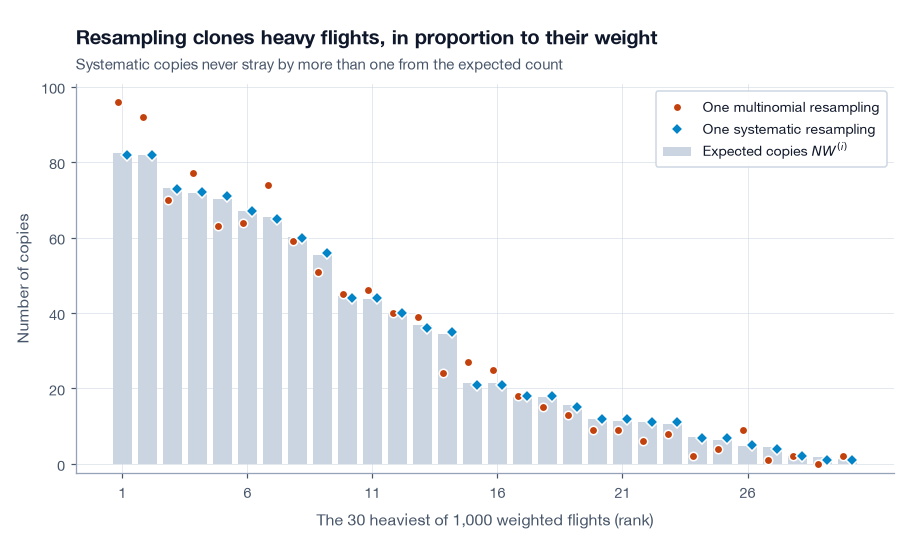

In [42]:
heaviest = np.argsort(demo_w)[::-1][:RESAMPLE_SHOWN]
rng = make_rng(5, 4)
draws = {
    "One multinomial resampling": np.bincount(
        multinomial_resample(demo_w, rng), minlength=RESAMPLE_DEMO_N
    ),
    "One systematic resampling": np.bincount(
        systematic_resample(demo_w, rng), minlength=RESAMPLE_DEMO_N
    ),
}
x = np.arange(RESAMPLE_SHOWN)
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(
    x,
    RESAMPLE_DEMO_N * demo_w[heaviest],
    color=COLOR_GRID,
    width=0.75,
    label="Expected copies $N W^{(i)}$",
)
draw_styles = (
    (COLOR_POSTERIOR, "o", -0.17),
    (COLOR_PARTICLES, "D", 0.17),
)  # colour, marker, offset
for (label, copies), (color, marker, shift) in zip(draws.items(), draw_styles, strict=True):
    ax.plot(
        x + shift,
        copies[heaviest],
        ls="none",
        marker=marker,
        ms=5.5,
        color=color,
        mec=COLOR_BG,
        label=label,
    )
ax.set_xticks(x[::5], [str(i + 1) for i in x[::5]])
ax.set_xlabel(f"The {RESAMPLE_SHOWN} heaviest of {RESAMPLE_DEMO_N:,} weighted flights (rank)")
ax.set_ylabel("Number of copies")
ax.set_ylim(bottom=-COPIES_AXIS_PAD)
set_figure_header(
    ax,
    "Resampling clones heavy flights, in proportion to their weight",
    subtitle="Systematic copies never stray by more than one from the expected count",
)
style_legend(ax, loc="upper right")
plt.show()

> **Takeaway.** Both schemes copy each flight about $N W^{(i)}$ times; the systematic one hits that target to within one copy, the multinomial one scatters around it.

### 5.2 The SIR particle filter

Put the pieces together; the result is the *bootstrap* or SIR (sampling importance resampling) filter of Gordon, Salmond and Smith [11, 16]. Draw $N$ particles from $p(x_0)$ with equal weights, then for each handshake $k = 1, \dots, 7$:

1. **Propagate.** $x_k^{(i)} \sim p(x_k \mid x_{k-1}^{(i)})$: the motion model of Ping 2 is the proposal.
2. **Reweight.** $\log w^{(i)} \leftarrow \log w^{(i)} + \log p(z_k \mid x_k^{(i)})$, then normalise (Ping 3). The weighted particles now approximate the *filtering distribution* $p(x_k \mid z_{1:k})$.
3. **Resample** if $\mathrm{ESS} < \tau N$ (Ping 4), with systematic resampling, and reset the weights to $1/N$. We use $\tau = 0.5$ and never resample after the last ping, where the weighted cloud is the answer.

**Why it works.** Step 1 is importance sampling with the prior as proposal, applied one ping at a time. Step 3 stops the weight variance from accumulating across pings, which is exactly what killed Ping 4. And because the motion model is random, two copies of the same flight separate at the next propagation: the cloud is refreshed precisely where the posterior lives.

**A free by-product: the evidence.** The normalising constant factorises as $Z_K = p(z_{1:K}) = \prod_{k=1}^{K} p(z_k \mid z_{1:k-1})$, and each factor is estimated by the weighted average likelihood $\sum_i W_{k-1}^{(i)}\, p(z_k \mid x_k^{(i)})$ computed in step 2. The product of these averages is an *unbiased* estimator of $Z_K$ [13], so the filter measures the acceptance rate $a_K = Z_K / M$ that rejection sampling could not measure in Ping 2.

In [43]:
@dataclass
class FilterRun:
    """Output of one run of the particle filter."""

    particles: np.ndarray  # particles at the last ping, shape (N, 5)
    weights: np.ndarray  # their normalised weights
    ess: np.ndarray  # ESS after each update
    resampled: np.ndarray  # whether the filter resampled after each ping
    log_evidence: np.ndarray  # log of the estimate of p(z_1, ..., z_k) after each ping
    clouds: list  # per ping: (particles, weights) after the update; empty unless record=True
    paths: np.ndarray | None  # (7, N, 2): positions at each ping of each final particle's ancestors
    origins: np.ndarray | None  # (7, N): index, at ping k, of each final particle's ancestor


def sir_step(particles, log_w, k, z_us, rng, model, ess_threshold, resample=systematic_resample):
    """One SIR step: propagate to ping k, reweight by its likelihood, resample if the ESS is low."""
    t_prev = T_PING_H[k - 1] if k > 0 else 0.0
    particles = propagate(particles, t_prev, T_PING_H[k], rng, model)  # 1. propagate
    log_lik = ping_log_likelihood(particles[:, LAT], particles[:, LON], k, model, z_us)
    log_evidence_increment = log_sum_exp(log_w + log_lik) - log_sum_exp(log_w)
    log_w = log_w + log_lik  # 2. reweight
    weights = normalize(log_w)
    ess = effective_sample_size(weights)
    step = {"particles": particles, "weights": weights, "ess": ess, "idx": None}
    step["log_evidence_increment"] = log_evidence_increment
    if ess < ess_threshold * len(weights) and k < N_PINGS - 1:  # 3. resample
        step["idx"] = resample(weights, rng)
        particles, log_w = particles[step["idx"]], np.zeros(len(weights))
    return particles, log_w, step


def run_filter(
    z_us,
    rng,
    model=BASELINE,
    n=N_PARTICLES,
    ess_threshold=ESS_THRESHOLD,
    resample=systematic_resample,
    record=False,
):
    """Run the SIR filter on the 7 BTO values z_us; record=True also keeps clouds and genealogy."""
    particles, log_w = sample_initial(n, rng, model), np.zeros(n)
    ess, resampled, log_increments, clouds, paths, origins = [], [], [], [], [], []
    for k in range(N_PINGS):
        particles, log_w, step = sir_step(
            particles, log_w, k, z_us, rng, model, ess_threshold, resample
        )
        ess.append(step["ess"])
        resampled.append(step["idx"] is not None)
        log_increments.append(step["log_evidence_increment"])
        if record:
            clouds.append((step["particles"], step["weights"]))
            paths.append(step["particles"][:, [LAT, LON]])
            origins.append(np.arange(n))
            if step["idx"] is not None:  # follow every surviving lineage back in time
                paths = [p[step["idx"]] for p in paths]
                origins = [o[step["idx"]] for o in origins]
    return FilterRun(
        particles=step["particles"],
        weights=step["weights"],
        ess=np.array(ess),
        resampled=np.array(resampled),
        log_evidence=np.cumsum(log_increments),
        clouds=clouds,
        paths=np.stack(paths) if record else None,
        origins=np.stack(origins) if record else None,
    )

**Check, on a flight we invent.** Before touching the real data we test the filter on a *synthetic* flight: one path drawn from the prior (one that ends over the open ocean, so that the map stays readable), whose seven BTOs we simulate with the noise model. The truth is known, and the filter never sees it. We run plain sequential importance sampling (never resample) and the SIR filter on the same data.

In [44]:
def simulate_bto(states, rng, noise_scale=1.0):
    """Seven noisy BTOs of a known flight whose states at the handshakes are `states` (7, 5)."""
    clean = predicted_bto(states[:, LAT], states[:, LON], SAT_ECEF_KM)
    return clean + noise_scale * PING_BTO_SD_US * rng.standard_normal(N_PINGS)

In [45]:
t_start = time.perf_counter()
demo_truth = simulate_flights(1, make_rng(5, 2))[:, 0]  # a prior draw that ends over the open ocean
demo_bto = simulate_bto(demo_truth, make_rng(5, 12))
demo_sir = run_filter(demo_bto, make_rng(5, 13), record=True)
demo_sis = run_filter(demo_bto, make_rng(5, 13), ess_threshold=0.0)  # never resamples
distinct_ancestors = np.array([len(np.unique(o)) for o in demo_sir.origins])
demo_s = time.perf_counter() - t_start

print(
    "ping   ESS/N (no resampling)   ESS/N (SIR)   resampled   distinct ancestors of the final cloud"
)
for k in range(N_PINGS):
    print(
        f"{k + 1:4d}   {demo_sis.ess[k] / N_PARTICLES:21.1e}"
        f"   {demo_sir.ess[k] / N_PARTICLES:11.3f}"
        f"   {'yes' if demo_sir.resampled[k] else 'no':>9}   {distinct_ancestors[k]:10,d}"
    )
print(f"\nTrue final latitude: {demo_truth[-1, LAT]:.2f} deg")
for name, run in (("no resampling", demo_sis), ("SIR", demo_sir)):
    q025, q05, q50, q95, q975 = weighted_quantile(
        run.particles[:, LAT], run.weights, [0.025, 0.05, 0.5, 0.95, 0.975]
    )
    print(
        f"{name:>13}: posterior median {q50:.2f} deg, 90% interval [{q05:.2f}, {q95:.2f}],"
        f" 95% interval [{q025:.2f}, {q975:.2f}], final ESS {run.ess[-1]:,.0f}"
    )

ping   ESS/N (no resampling)   ESS/N (SIR)   resampled   distinct ancestors of the final cloud
   1                 9.8e-01         0.978          no          557
   2                 1.1e-02         0.011         yes          557
   3                 7.1e-04         0.051         yes        2,681
   4                 1.2e-04         0.154         yes        4,148
   5                 2.5e-05         0.079         yes        5,418
   6                 2.0e-05         0.065         yes       10,367
   7                 1.6e-05         0.704          no      100,000

True final latitude: -37.17 deg
no resampling: posterior median -35.94 deg, 90% interval [-37.31, -35.94], 95% interval [-37.31, -35.94], final ESS 2
          SIR: posterior median -35.45 deg, 90% interval [-40.96, -31.42], 95% interval [-41.78, -30.85], final ESS 70,411


In [46]:
sir_q05, sir_q50, sir_q95 = weighted_quantile(
    demo_sir.particles[:, LAT], demo_sir.weights, [0.05, 0.5, 0.95]
)
print_card(
    "Ping 5.2, the filter on a flight we invented",
    simulated=f"one flight drawn from the prior and its {N_PINGS} noisy BTOs; the filter sees only"
    " the BTOs and runs twice on them, with resampling (SIR) and without",
    size=f"2 runs × {N_PARTICLES:,} particles",
    settings=f"SIR resamples when ESS < {ESS_THRESHOLD:g} N (systematic), the other run never;"
    " streams make_rng(5, 2) truth, make_rng(5, 12) noise, make_rng(5, 13) filter",
    seconds=demo_s,
    result=f"truth {demo_truth[-1, LAT]:.2f} deg; SIR median {sir_q50:.2f} deg, 90% interval"
    f" [{sir_q05:.2f}, {sir_q95:.2f}]; final ESS {demo_sir.ess[-1]:,.0f} with resampling,"
    f" {demo_sis.ess[-1]:,.0f} without",
)

What we actually ran · Ping 5.2, the filter on a flight we invented
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   one flight drawn from the prior and its 7 noisy BTOs; the filter sees only the BTOs
            and runs twice on them, with resampling (SIR) and without
Size        2 runs × 100,000 particles
Settings    SIR resamples when ESS < 0.5 N (systematic), the other run never; streams
            make_rng(5, 2) truth, make_rng(5, 12) noise, make_rng(5, 13) filter
Run time    1.38 s
Result      truth -37.17 deg; SIR median -35.45 deg, 90% interval [-40.96, -31.42]; final ESS
            70,411 with resampling, 2 without


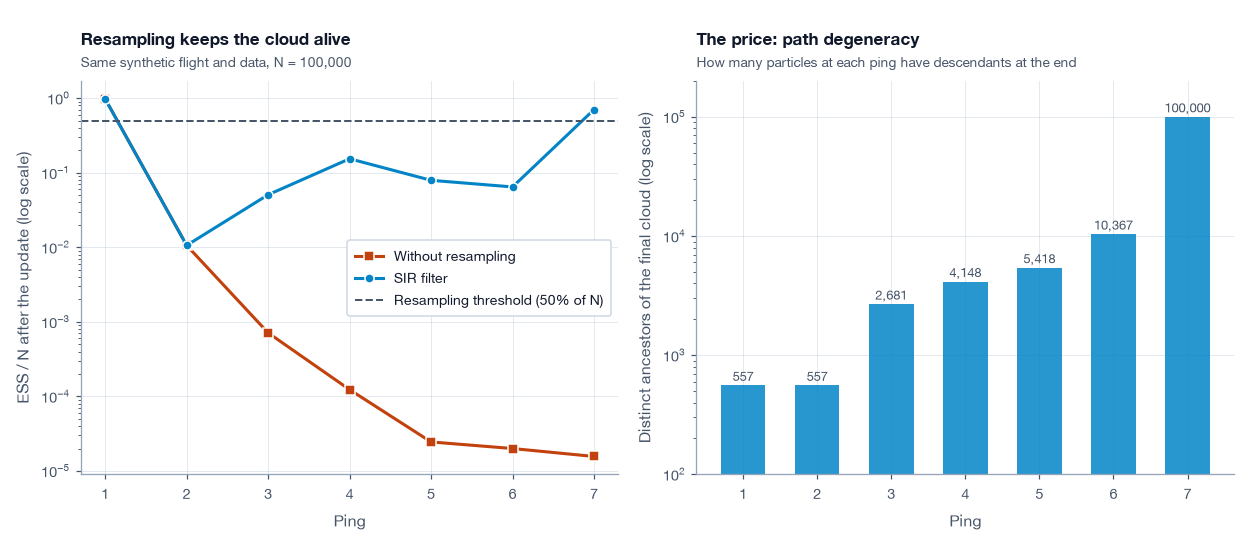

In [47]:
fig, (ax_ess, ax_anc) = plt.subplots(1, 2, figsize=FIGSIZE_TWO_PANEL)
for run, label, color, marker in (
    (demo_sis, "Without resampling", COLOR_POSTERIOR, "s"),
    (demo_sir, "SIR filter", COLOR_PARTICLES, "o"),
):
    ax_ess.semilogy(
        pings,
        run.ess / N_PARTICLES,
        color=color,
        marker=marker,
        ms=6,
        mec=COLOR_BG,
        lw=2,
        label=label,
    )
ax_ess.axhline(
    ESS_THRESHOLD,
    color=COLOR_TEXT_MUTED,
    ls="--",
    lw=1.3,
    label=f"Resampling threshold ({ESS_THRESHOLD:.0%} of N)",
)
ax_ess.set_xticks(pings)
ax_ess.set_xlabel("Ping")
ax_ess.set_ylabel("ESS / N after the update (log scale)")
set_figure_header(
    ax_ess,
    "Resampling keeps the cloud alive",
    subtitle=f"Same synthetic flight and data, N = {N_PARTICLES:,}",
)
style_legend(ax_ess, loc="center right")
ax_anc.bar(pings, distinct_ancestors, color=COLOR_PARTICLES, alpha=0.85, width=0.6)
for k, count in zip(pings, distinct_ancestors, strict=True):
    ax_anc.annotate(
        f"{count:,}",
        (k, count),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        color=COLOR_TEXT_MUTED,
    )
ax_anc.set_yscale("log")
ax_anc.set_ylim(ANCESTOR_AXIS_LIMITS)
ax_anc.set_xticks(pings)
ax_anc.set_xlabel("Ping")
ax_anc.set_ylabel("Distinct ancestors of the final cloud (log scale)")
set_figure_header(
    ax_anc,
    "The price: path degeneracy",
    subtitle="How many particles at each ping have descendants at the end",
)
fig.tight_layout()
plt.show()

> **Takeaway.** Without resampling the cloud dies after a few pings; with it the ESS is restored at every ping, at the price of a genealogy that funnels through a few hundred early ancestors.

Without resampling, the ESS collapses to a couple of particles by the fifth ping, and the final answer rests on two flights: its "90% interval" is just the gap between them, not a statement of uncertainty. With resampling, the ESS drops at every update (most sharply at ping 2, the first ping after the turn) but is restored each time, and the final cloud is healthy. The map shows both answers next to the truth.

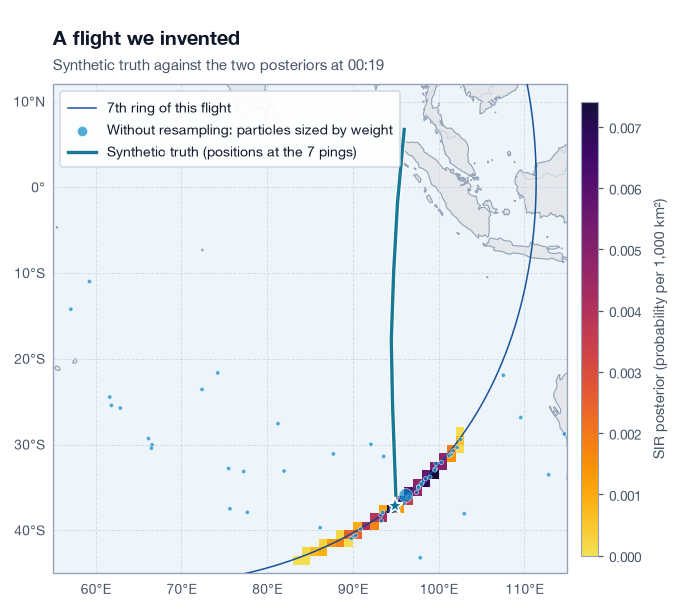

In [48]:
demo_lat_edges, demo_lon_edges = extent_edges(FLIGHT_EXTENT, FILM_CELL_DEG)
_, demo_density = posterior_grid(
    demo_sir.particles[:, LAT],
    demo_sir.particles[:, LON],
    demo_sir.weights,
    demo_lat_edges,
    demo_lon_edges,
)
fig, ax = make_cartopy_map(
    FLIGHT_EXTENT,
    figsize=FIGSIZE_SQUARE,
    title="A flight we invented",
    subtitle="Synthetic truth against the two posteriors at 00:19",
)
draw_density(
    ax,
    demo_lat_edges,
    demo_lon_edges,
    1e3 * demo_density,
    "SIR posterior (probability per 1,000 km²)",
)
draw_ring(
    ax,
    *bto_ring(demo_bto[-1], SAT_ECEF_KM[-1]),
    emphasis=True,
    label="7th ring of this flight",
    lw=1.0,
)
draw_weighted_particles(
    ax,
    demo_sis.particles[:, LAT],
    demo_sis.particles[:, LON],
    demo_sis.weights,
    max_points=DEMO_PARTICLES_SHOWN,
    label="Without resampling: particles sized by weight",
)
draw_trajectories(
    ax,
    [demo_truth[:, LAT]],
    [demo_truth[:, LON]],
    role="truth",
    label="Synthetic truth (positions at the 7 pings)",
)
style_legend(ax, loc="upper left")
plt.show()

> **Takeaway.** Without resampling the answer collapses onto two heavy particles, here by luck near the truth but with a confidence the data cannot support; the SIR cloud spans the whole stretch of arc compatible with the data, truth included.

A single flight proves little, though. Here the true latitude falls inside the SIR's 90% interval, which should happen nine times out of ten; whether it happens *exactly* nine times out of ten is the subject of the Interlude.

### 5.3 The price: path degeneracy

Resampling fights weight degeneracy, but it has a cost. Every resampling step kills some lineages, so if we follow today's particles back in time their ancestry collapses: the right panel above shows that the whole final cloud descends from a few hundred of the 100,000 particles alive at the first two pings. The filter describes where the aircraft *is* at each ping very well, and the early part of its *path* poorly. For our question, the final position, the filtering distribution is exactly what we need; reconstructing the full path would call for smoothing methods, which are beyond this notebook.

---

## Interlude — Trust, but verify

> **In plain words**
>
> Before trusting our fly, weigh and copy loop on the real data, we grade it on an exam with known answers. We invent a hundred flights with simulated handshakes and check how often each true end point lands inside the reported regions, just as days forecast with a ninety per cent chance of rain should turn out rainy about nine times out of ten. The loop passes when the invented flights and their handshakes follow its own assumptions, yet fails badly when the flights turn more than it believes (and more mildly when the handshakes are noisier than it believes), looking just as confident all the while.

> **The obstacle.** The filter returns a convincing cloud. But is a "90% region" right 90% of the time? On the real flight we cannot check: nobody knows the truth. So we manufacture flights whose truth we know, and grade the filter on them.

### Simulation-based calibration

The protocol [14, 15] repeats the check of Ping 5 on $M$ independent synthetic flights:

1. draw a true flight from the prior, $x_{0:7}^{\star} \sim p(x_{0:7})$;
2. simulate its BTOs from the noise model, $z_{1:7} \sim p(z_{1:7} \mid x_{1:7}^{\star})$;
3. run the filter on $z_{1:7}$ alone, with fresh random numbers (no leakage of the truth);
4. record where the true final position falls in the posterior.

**Why coverage must be exact.** Steps 1 and 2 draw the pair $(x^\star, z)$ from the joint distribution $p(x)\,p(z \mid x)$, which is also $p(z)\,p(x \mid z)$. So for every data set $z$, the truth is a draw from the exact posterior $p(x \mid z)$. Any region $R_\alpha(z)$ holding posterior probability $\alpha$ then contains the truth with probability exactly $\alpha$, on average over flights. If the empirical coverage departs from $\alpha$ by more than the binomial noise $\pm 1.96\sqrt{\alpha(1-\alpha)/M}$, either the filter is inaccurate or the code is wrong.

We grade two kinds of regions for the final position: the 2-D **highest posterior density** (HPD) region (the smallest set of map cells holding probability $\alpha$), and the central credible interval of the final **latitude**. For each flight it is enough to record one number per kind: the posterior mass of the cells denser than the truth's cell (the truth is inside the $\alpha$-HPD region exactly when this mass is below $\alpha$), and the posterior CDF at the true latitude (inside the central $\alpha$-interval exactly when it lies within $\tfrac{1-\alpha}{2}$ of $\tfrac{1}{2}$). If the filter is calibrated, both numbers are uniform on $[0, 1]$.

**Why it can fail.** Calibration holds *if the model is right*: the argument above assumed that the truth comes from the very prior and noise model that the filter uses. To see what a wrong model does, we repeat the experiment twice with synthetic flights that break one assumption each: aircraft that turn three times more than the filter believes, and BTO errors twice as large as the filter believes.

In [49]:
def hpd_threshold(mass, density, level):
    """Density threshold of the highest-posterior-density region holding probability `level`."""
    order = np.argsort(density, axis=None)[::-1]
    cumulative = np.cumsum(mass.ravel()[order])
    return density.ravel()[order][np.searchsorted(cumulative, level * cumulative[-1])]


def grid_edges(lat, lon, cell_deg=HPD_CELL_DEG):
    """Grid edges covering every point, aligned on multiples of cell_deg."""

    def edges(x):
        return np.arange(np.floor(x.min() / cell_deg), np.ceil(x.max() / cell_deg) + 1) * cell_deg

    return edges(lat), edges(lon)


def calibration_scores(run, truth_lat, truth_lon):
    """(mass denser than the truth's cell, posterior CDF of the final latitude at the truth)."""
    lat, lon, w = run.particles[:, LAT], run.particles[:, LON], run.weights
    lat_edges, lon_edges = grid_edges(np.append(lat, truth_lat), np.append(lon, truth_lon))
    mass, density = posterior_grid(lat, lon, w, lat_edges, lon_edges)
    i = np.searchsorted(lat_edges, truth_lat, side="right") - 1
    j = np.searchsorted(lon_edges, truth_lon, side="right") - 1
    return mass[density > density[i, j]].sum(), w[lat < truth_lat].sum()


def calibration_experiment(stream, truth_model=BASELINE, noise_scale=1.0):
    """Scores of CALIB_FLIGHTS synthetic flights drawn from truth_model, with BTO noise noise_scale
    times the assumed one; the filter always assumes BASELINE."""
    scores = np.empty((CALIB_FLIGHTS, 2))
    for m in range(CALIB_FLIGHTS):  # three independent streams per flight: truth, noise, filter
        truth = simulate_flights(1, make_rng(stream, m, 0), truth_model)[:, 0]
        bto = simulate_bto(truth, make_rng(stream, m, 1), noise_scale)
        run = run_filter(bto, make_rng(stream, m, 2), n=CALIB_PARTICLES)
        scores[m] = calibration_scores(run, truth[-1, LAT], truth[-1, LON])
    return scores


def coverage(scores, levels):
    """Fraction of flights covered by the HPD regions and by the central latitude intervals."""
    levels = np.asarray(levels)[:, None]
    return np.mean(scores[:, 0] < levels, axis=1), np.mean(
        np.abs(scores[:, 1] - 0.5) < levels / 2, axis=1
    )


def binomial_band(levels, n=CALIB_FLIGHTS):
    """Half-width of the 95% band of an empirical coverage computed from n independent flights."""
    levels = np.asarray(levels)
    return 1.96 * np.sqrt(levels * (1 - levels) / n)

In [50]:
t_start = time.perf_counter()
calib_scores = {
    "Well specified": calibration_experiment(71),
    "Truth turns 3× more (dynamics wrong)": calibration_experiment(
        72, replace(BASELINE, turn_walk_deg=15.0)
    ),
    "Truth BTO noise ×2 (noise wrong)": calibration_experiment(73, noise_scale=2.0),
}
calibration_s = time.perf_counter() - t_start
print(f"{len(calib_scores) * CALIB_FLIGHTS} filter runs in {calibration_s:.0f} s")
for name, scores in calib_scores.items():
    print(f"\n{name}")
    bands, (hpd_cov, lat_cov) = binomial_band(CREDIBLE_LEVELS), coverage(scores, CREDIBLE_LEVELS)
    for level, band, hpd, lat in zip(CREDIBLE_LEVELS, bands, hpd_cov, lat_cov, strict=True):
        print(
            f"   {level:.0%} regions (expected {level - band:.0%} to {min(level + band, 1):.0%}):"
            f"  2-D HPD {hpd:4.0%}   latitude interval {lat:4.0%}"
        )

300 filter runs in 89 s

Well specified
   50% regions (expected 40% to 60%):  2-D HPD  45%   latitude interval  55%
   90% regions (expected 84% to 96%):  2-D HPD  90%   latitude interval  86%
   95% regions (expected 91% to 99%):  2-D HPD  95%   latitude interval  94%

Truth turns 3× more (dynamics wrong)
   50% regions (expected 40% to 60%):  2-D HPD  13%   latitude interval  27%
   90% regions (expected 84% to 96%):  2-D HPD  37%   latitude interval  48%
   95% regions (expected 91% to 99%):  2-D HPD  44%   latitude interval  54%

Truth BTO noise ×2 (noise wrong)
   50% regions (expected 40% to 60%):  2-D HPD  30%   latitude interval  49%
   90% regions (expected 84% to 96%):  2-D HPD  76%   latitude interval  85%
   95% regions (expected 91% to 99%):  2-D HPD  85%   latitude interval  90%


In [51]:
coverage_90 = {name.split(" (")[0]: coverage(s, [0.9]) for name, s in calib_scores.items()}
print_card(
    "Interlude, calibration on synthetic flights",
    simulated="flights drawn from the prior (or from a deliberately wrong model), their noisy BTOs,"
    " and one filter run per flight that sees only the BTOs",
    size=f"{len(calib_scores)} experiments × {CALIB_FLIGHTS} flights × {CALIB_PARTICLES:,}"
    f" particles = {len(calib_scores) * CALIB_FLIGHTS} filter runs",
    settings="streams 71, 72 and 73, three independent streams per flight (truth, noise, filter);"
    " the filter always assumes the baseline model",
    seconds=calibration_s,
    result="truth inside the 90% HPD region / the 90% latitude interval: "
    + "; ".join(f"{name} {hpd[0]:.0%} / {lat[0]:.0%}" for name, (hpd, lat) in coverage_90.items()),
)

What we actually ran · Interlude, calibration on synthetic flights
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   flights drawn from the prior (or from a deliberately wrong model), their noisy BTOs,
            and one filter run per flight that sees only the BTOs
Size        3 experiments × 100 flights × 50,000 particles = 300 filter runs
Settings    streams 71, 72 and 73, three independent streams per flight (truth, noise, filter);
            the filter always assumes the baseline model
Run time    88.88 s
Result      truth inside the 90% HPD region / the 90% latitude interval: Well specified 90% /
            86%; Truth turns 3× more 37% / 48%; Truth BTO noise ×2 76% / 85%


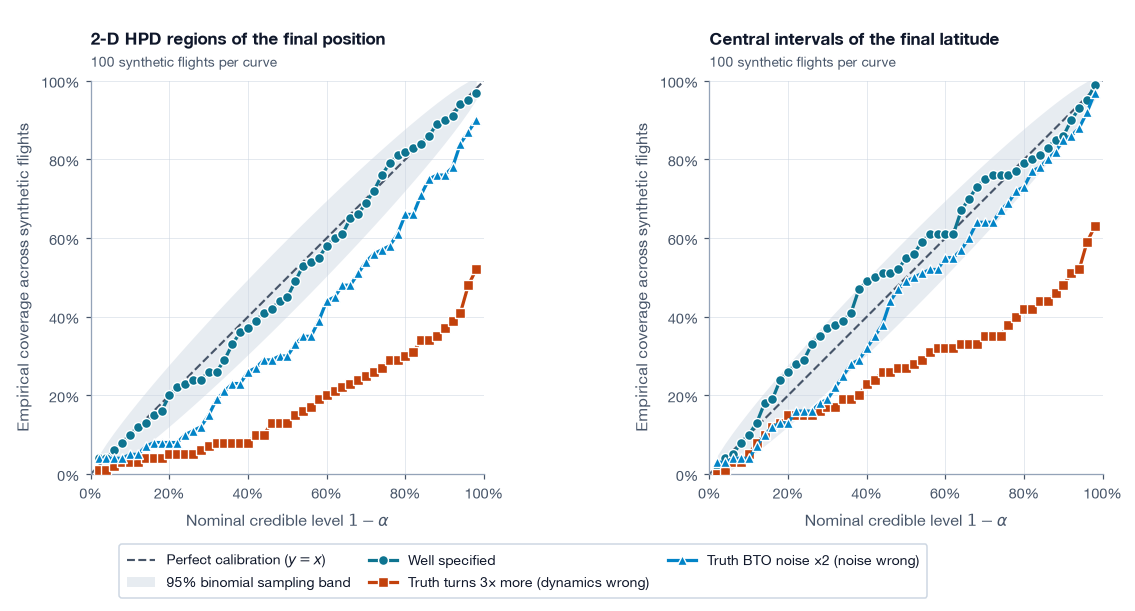

In [52]:
band = binomial_band(CALIB_CURVE_LEVELS)
curves = {name: coverage(scores, CALIB_CURVE_LEVELS) for name, scores in calib_scores.items()}
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_TWO_PANEL)
panel_titles = ("2-D HPD regions of the final position", "Central intervals of the final latitude")
for i, (ax, title) in enumerate(zip(axes, panel_titles, strict=True)):
    plot_calibration(
        CALIB_CURVE_LEVELS,
        {name: c[i] for name, c in curves.items()},
        CALIB_CURVE_LEVELS - band,
        CALIB_CURVE_LEVELS + band,
        title=title,
        subtitle=f"{CALIB_FLIGHTS} synthetic flights per curve",
        ax=ax,
        show_legend=False,
    )  # one shared legend below both panels
fig.tight_layout()
style_legend(axes[0], loc="below", ncol=3, bbox_to_anchor=SHARED_LEGEND_ANCHOR)
plt.show()

> **Takeaway.** With the right model the filter's credible regions are honest; with the wrong dynamics they are badly overconfident, and only an experiment with a known truth can reveal it.

- **Well specified:** every coverage falls inside its binomial band: no detectable miscalibration, for 2-D regions and latitude intervals alike (with 100 flights, the test can only detect deviations of several percentage points).
- **Wrong dynamics** (true aircraft turning three times more than assumed): the 90% regions contain the truth less than half the time. The filter is confidently wrong, and nothing in its output warns us.
- **Wrong noise level:** the damage is milder and shows mostly in 2-D. The noise sets the width of the cloud *across* the arc, while its position *along* the arc is governed by the dynamics.

That asymmetry announces the main result of Epilogue A: what matters most is how we assume the aircraft flew.

---

## Ping 6 — The cloud moves south

> **In plain words**
>
> Now the filter gets the seven real handshakes. A hundred thousand simulated aircraft leave the last radar position; between handshakes the cloud spreads out as they fly, and at each handshake only the part lying on the new ring keeps a noticeable weight, and that part is cloned whenever the weights become too uneven. By the last handshake the cloud has become a thin crescent along the seventh ring, and the same run gives our best estimate, under our assumptions, of when the aircraft turned south and how fast it flew.

> **The obstacle.** The filter has passed its exam on invented flights. Time to give it the seven real handshakes and watch the cloud of possible aircraft evolve, ping by ping.

In [53]:
t_start = time.perf_counter()
main_run = run_filter(PING_BTO_US, make_rng(6), record=True)
main_run_s = time.perf_counter() - t_start
print(f"SIR filter, N = {N_PARTICLES:,} particles: {main_run_s:.1f} s")
# Rejection sampling would accept a flight with probability a_K = Z_K / M_K (Ping 2).
log_accept_filter = main_run.log_evidence - np.cumsum(log_max_lik[:, 0])
print("ping   time    ESS/N   resampled   rejection acceptance a_K (filter)   (Ping 2 estimate)")
for k in range(N_PINGS):
    print(
        f"{k + 1:4d}  {hhmm(PING_TIMES[k])}   {main_run.ess[k] / N_PARTICLES:.3f}"
        f"   {'yes' if main_run.resampled[k] else 'no':>9}   {np.exp(log_accept_filter[k]):30.1e}"
        f"   {accept_rate[k]:17.1e}"
    )

SIR filter, N = 100,000 particles: 0.6 s
ping   time    ESS/N   resampled   rejection acceptance a_K (filter)   (Ping 2 estimate)
   1  18:25   0.970          no                          8.8e-01             8.8e-01
   2  19:41   0.016         yes                          1.0e-02             1.0e-02
   3  20:41   0.062         yes                          4.5e-04             4.6e-04
   4  21:41   0.127         yes                          4.1e-05             2.7e-05
   5  22:41   0.151         yes                          4.3e-06             2.9e-06
   6  00:11   0.092         yes                          2.8e-07             3.4e-08
   7  00:19   0.917          no                          2.2e-07             2.7e-08


In [54]:
resampled_after = ", ".join(str(k + 1) for k in np.flatnonzero(main_run.resampled))
print_card(
    "Ping 6, the filter on the real data",
    simulated="flights from the last radar fix to 00:19 UTC, weighted and resampled against the"
    f" {N_PINGS} measured BTOs",
    size=f"{N_PARTICLES:,} particles",
    settings=f"baseline assumptions (section 0.3); systematic resampling when ESS <"
    f" {ESS_THRESHOLD:g} N; stream make_rng(6)",
    seconds=main_run_s,
    result=f"resampled after pings {resampled_after}; final ESS {main_run.ess[-1]:,.0f};"
    f" a_7 = {np.exp(log_accept_filter[-1]):.1e}, so rejection would keep one simulated flight"
    f" in {np.exp(-log_accept_filter[-1]) / 1e6:.1f} million",
)

What we actually ran · Ping 6, the filter on the real data
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   flights from the last radar fix to 00:19 UTC, weighted and resampled against the 7
            measured BTOs
Size        100,000 particles
Settings    baseline assumptions (section 0.3); systematic resampling when ESS < 0.5 N; stream
            make_rng(6)
Run time    0.62 s
Result      resampled after pings 2, 3, 4, 5, 6; final ESS 91,688; a_7 = 2.2e-07, so rejection
            would keep one simulated flight in 4.6 million


The ESS collapses most at 19:41, the first handshake after the turn: among all the headings and turn times of the prior, the filter must find the few that put the aircraft on ring 2 at the right moment. Resampling restores the cloud after every update.

The last columns close a loop opened in Ping 2. The filter's evidence and the rejection estimates agree for the first three pings. Beyond, the rejection estimates rest on a handful of flights and typically fall short (an average dominated by rare large values is unbiased but skewed), while the filter keeps measuring. After seven pings rejection would keep about one simulated flight in five million, so 1,000 exact posterior samples would cost billions of simulated flights, hours of computation, against well under a second for the filter.

Now the cloud itself. For each ping we bin the weighted particles, right after the update, on a coarse map grid, and scale each panel by its own maximum so that both the early dot and the final crescent stay visible.

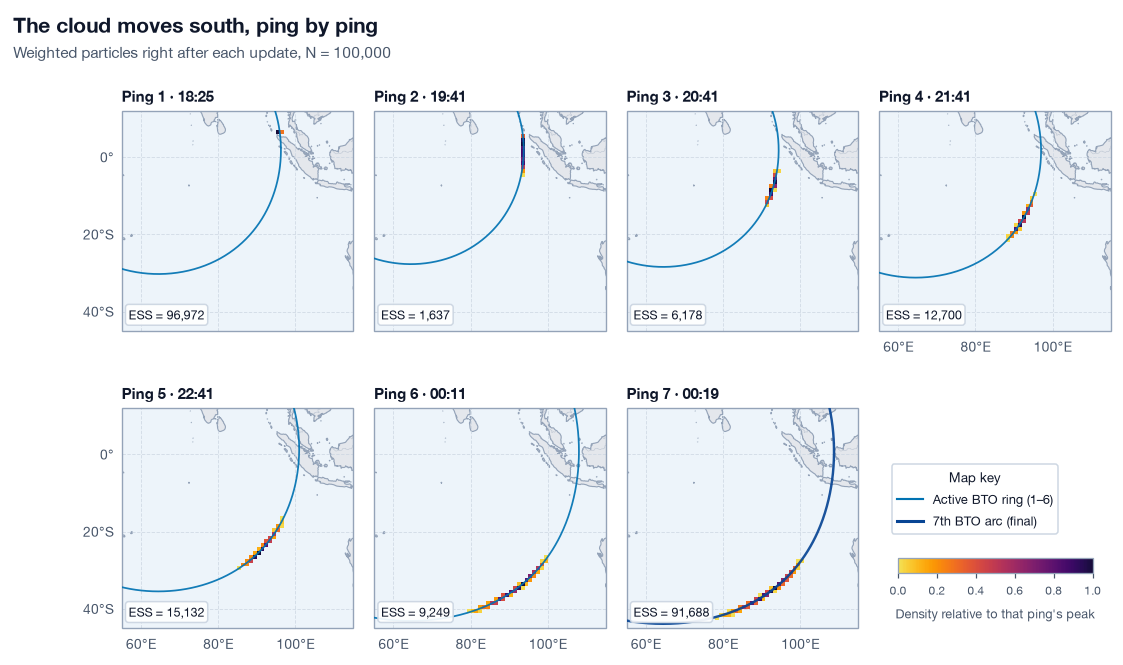

In [55]:
film_lat_edges, film_lon_edges = extent_edges(FLIGHT_EXTENT, FILM_CELL_DEG)
film_cbar_label = "Density relative to that ping's peak"
film_frames = []
for k, (particles, weights) in enumerate(main_run.clouds):
    _, density = posterior_grid(
        particles[:, LAT], particles[:, LON], weights, film_lat_edges, film_lon_edges
    )
    film_frames.append(
        {
            "lat_edges": film_lat_edges,
            "lon_edges": film_lon_edges,
            "density": density / density.max(),
            "ring_lat": rings[k][0],
            "ring_lon": rings[k][1],
            "ess": main_run.ess[k],
            "title": f"Ping {k + 1} · {hhmm(PING_TIMES[k])}",
        }
    )
fig, _ = plot_ping_filmstrip(
    film_frames,
    extent=FLIGHT_EXTENT,
    shared_vmax=True,
    cbar_label=film_cbar_label,
    title="The cloud moves south, ping by ping",
    subtitle=f"Weighted particles right after each update, N = {N_PARTICLES:,}",
)
plt.show()

> **Takeaway.** The cloud starts as a dot at the radar fix, sweeps west then south between pings, and is squeezed onto each new ring; by 00:19 it is a thin crescent along the 7th arc, from about 30°S to 41°S.

The same evolution as an interactive animation (press Play in JupyterLab or VS Code; GitHub shows the last frame):

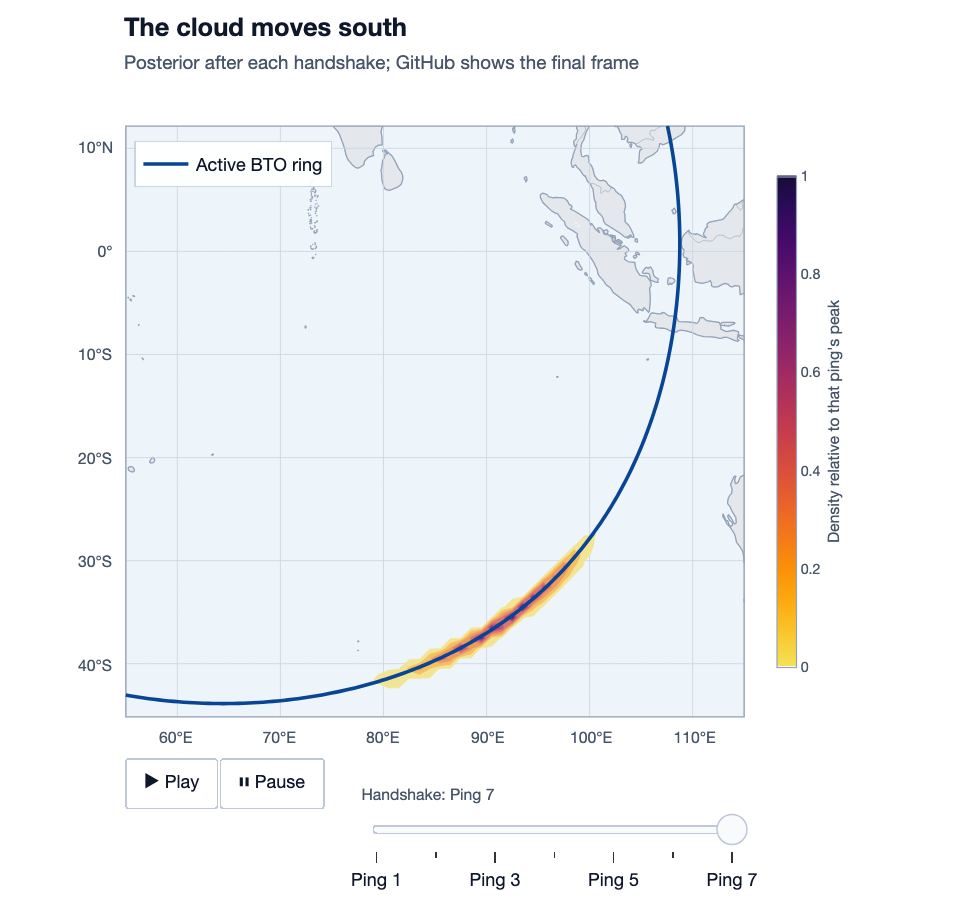

In [56]:
make_plotly_ping_animation(
    film_frames,
    extent=FLIGHT_EXTENT,
    size=PLOTLY_SIZE_SQUARE,
    title="The cloud moves south",
    subtitle="Posterior after each handshake; GitHub shows the final frame",
    shared_vmax=True,
    cbar_label=film_cbar_label,
).show()

Before reading the final answer, two by-products of the run deserve a look: what the filter says about *how* the aircraft flew. Each final particle carries its own turn time, speed and heading, so their weighted quantiles are posterior summaries.

In [57]:
final_p, final_w = main_run.particles, main_run.weights
turn_q_h = weighted_quantile(final_p[:, TURN], final_w, [0.05, 0.5, 0.95])
turn_utc_q = RADAR_FIX_TIME + np.round(turn_q_h * 3600).astype("timedelta64[s]")
phone_call_h = (PHONE_CALL_UTC - RADAR_FIX_TIME) / np.timedelta64(1, "h")
p_turned_before_call = final_w[final_p[:, TURN] < phone_call_h].sum()
speed_q = weighted_quantile(final_p[:, SPD], final_w, [0.05, 0.5, 0.95])
heading_q = weighted_quantile(final_p[:, HDG] % 360.0, final_w, [0.05, 0.5, 0.95])
print("Final major turn (UTC), 5% / median / 95%:", [str(t)[11:16] for t in turn_utc_q])
print(
    f"P(turn before the unanswered phone call at {str(PHONE_CALL_UTC)[11:16]})"
    f" = {p_turned_before_call:.0%}"
)
print(f"Distinct turn times among the final particles: {len(np.unique(final_p[:, TURN])):,}")
print(f"Ground speed at 00:19 (kn), 5% / median / 95%: {np.round(speed_q).astype(int)}")
print(f"Heading at 00:19 (deg),     5% / median / 95%: {np.round(heading_q).astype(int)}")

Final major turn (UTC), 5% / median / 95%: ['18:25', '18:37', '18:48']
P(turn before the unanswered phone call at 18:39) = 60%
Distinct turn times among the final particles: 862
Ground speed at 00:19 (kn), 5% / median / 95%: [408 455 508]
Heading at 00:19 (deg),     5% / median / 95%: [166 182 200]


The filter dates the final major turn around 18:37 UTC (90% between 18:25 and 18:48) and gives a probability of about 60% that it happened before the unanswered phone call of 18:39. That is consistent with the BFO, which we did not use: the Doppler data recorded during that call fit an aircraft already flying south [6]. At 00:19 the aircraft flies at about 455 knots on a heading close to due south. One caveat from Ping 5: these static quantities are carried by fewer than a thousand distinct ancestors, so their posterior is coarse.

---

## Ping 7 — The final arc

> **In plain words**
>
> To turn a cloud of end points into a search plan, we rank the ocean by probability and outline the smallest areas holding a given share of it. The result is a long, narrow ridge along the seventh ring rather than a single sharp peak, so a search should target a region rather than a single spot. Re-running the whole computation with fresh random numbers shows how much of the remaining spread comes from the computer: very little, like a sharp photograph of a foggy scene where finer pixels cannot lift the fog.

> **The obstacle.** The cloud has landed on the 7th arc. But ships cannot search a probability distribution. Where exactly should they look first, how confident can we be, and how much of the remaining uncertainty is our computer's fault rather than the aircraft's?

### 7.1 The probability map

We summarise the final weighted cloud on a grid of half-degree cells and convert cell masses into densities per km² (cells shrink towards the pole). The **highest posterior density** (HPD) region at level $\alpha$ is the smallest set of cells holding probability $\alpha$: sort the cells by density, accumulate their masses, stop at $\alpha$. These are the regions whose calibration the Interlude checked. They answer the operational question directly: *if we can only search a given area, which area maximises the chance of finding the aircraft?*

In [58]:
arc_lat_edges, arc_lon_edges = extent_edges(ARC_GRID_EXTENT, HPD_CELL_DEG)
final_mass, final_density = posterior_grid(
    final_p[:, LAT], final_p[:, LON], final_w, arc_lat_edges, arc_lon_edges
)
hpd_thresholds = {
    level: hpd_threshold(final_mass, final_density, level) for level in CREDIBLE_LEVELS
}
lat_mass = final_mass.sum(axis=1)

print(f"Posterior mass inside the map: {final_mass.sum():.4f}")
for level, threshold in hpd_thresholds.items():
    rows = np.flatnonzero((final_density >= threshold).any(axis=1))
    lat_from, lat_to = arc_lat_edges[rows[0]], arc_lat_edges[rows[-1] + 1]
    print(f"{level:.0%} HPD region spans latitudes {lat_from:.1f} to {lat_to:.1f}")
best = lat_mass.argmax()
print(
    f"Most probable {HPD_CELL_DEG} deg band of latitude:"
    f" {arc_lat_edges[best]:.1f} to {arc_lat_edges[best + 1]:.1f}"
    f" ({lat_mass[best]:.0%} of the probability)"
)
top_cell = np.unravel_index(np.argmax(final_density), final_density.shape)
top_lat, top_lon = (
    arc_lat_edges[top_cell[0]] + HPD_CELL_DEG / 2,
    arc_lon_edges[top_cell[1]] + HPD_CELL_DEG / 2,
)
print(
    f"Highest-density {HPD_CELL_DEG}° x {HPD_CELL_DEG}° cell of this run:"
    f" centred at ({top_lat:.2f}, {top_lon:.2f}), probability {final_mass[top_cell]:.1%}"
)

Posterior mass inside the map: 1.0000
50% HPD region spans latitudes -39.5 to -32.0
90% HPD region spans latitudes -41.0 to -28.5
95% HPD region spans latitudes -41.5 to -28.5
Most probable 0.5 deg band of latitude: -36.5 to -36.0 (6% of the probability)
Highest-density 0.5° x 0.5° cell of this run: centred at (-36.25, 91.25), probability 4.0%


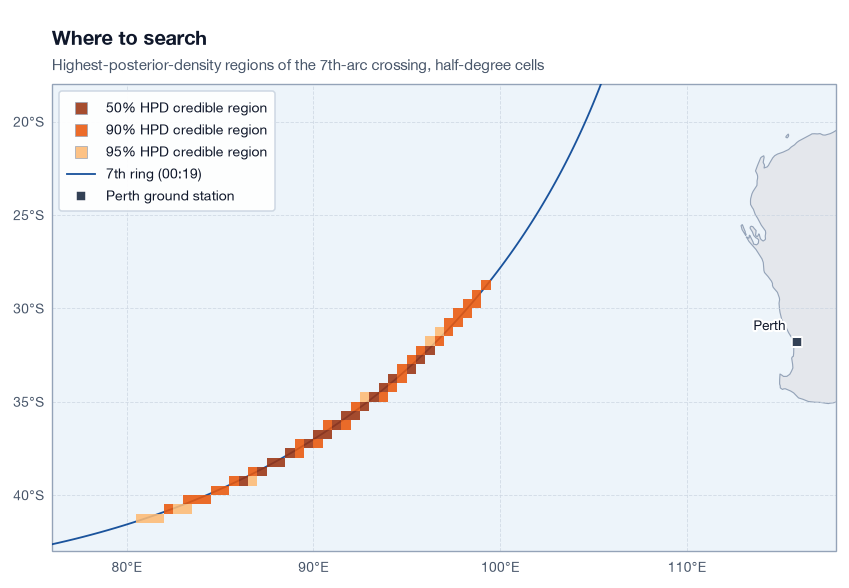

In [59]:
perth_place = {
    "name": "Perth",
    "lat": GES_LAT_DEG,
    "lon": GES_LON_DEG,
    "role": "satellite",
    "offset": (-8, 6),
    "legend_label": "Perth ground station",
}
fig, ax = make_cartopy_map(
    "seventh_arc",
    title="Where to search",
    subtitle="Highest-posterior-density regions of the 7th-arc crossing, half-degree cells",
)
draw_hpd_cells(ax, arc_lat_edges, arc_lon_edges, final_density, hpd_thresholds)
draw_ring(ax, *rings[-1], emphasis=True, label="7th ring (00:19)", lw=1.2, zorder=3.0)
annotate_places(ax, [perth_place])
style_legend(ax, loc="upper left")
plt.show()

> **Takeaway.** The search priority map is a narrow ridge along the 7th arc, in the open ocean west-south-west of Perth: the 50% region spans roughly 39.5°S to 32°S, and there is no single sharp peak to send a ship to.

The same posterior as an interactive density map on a finer grid (hover for coordinates and density):

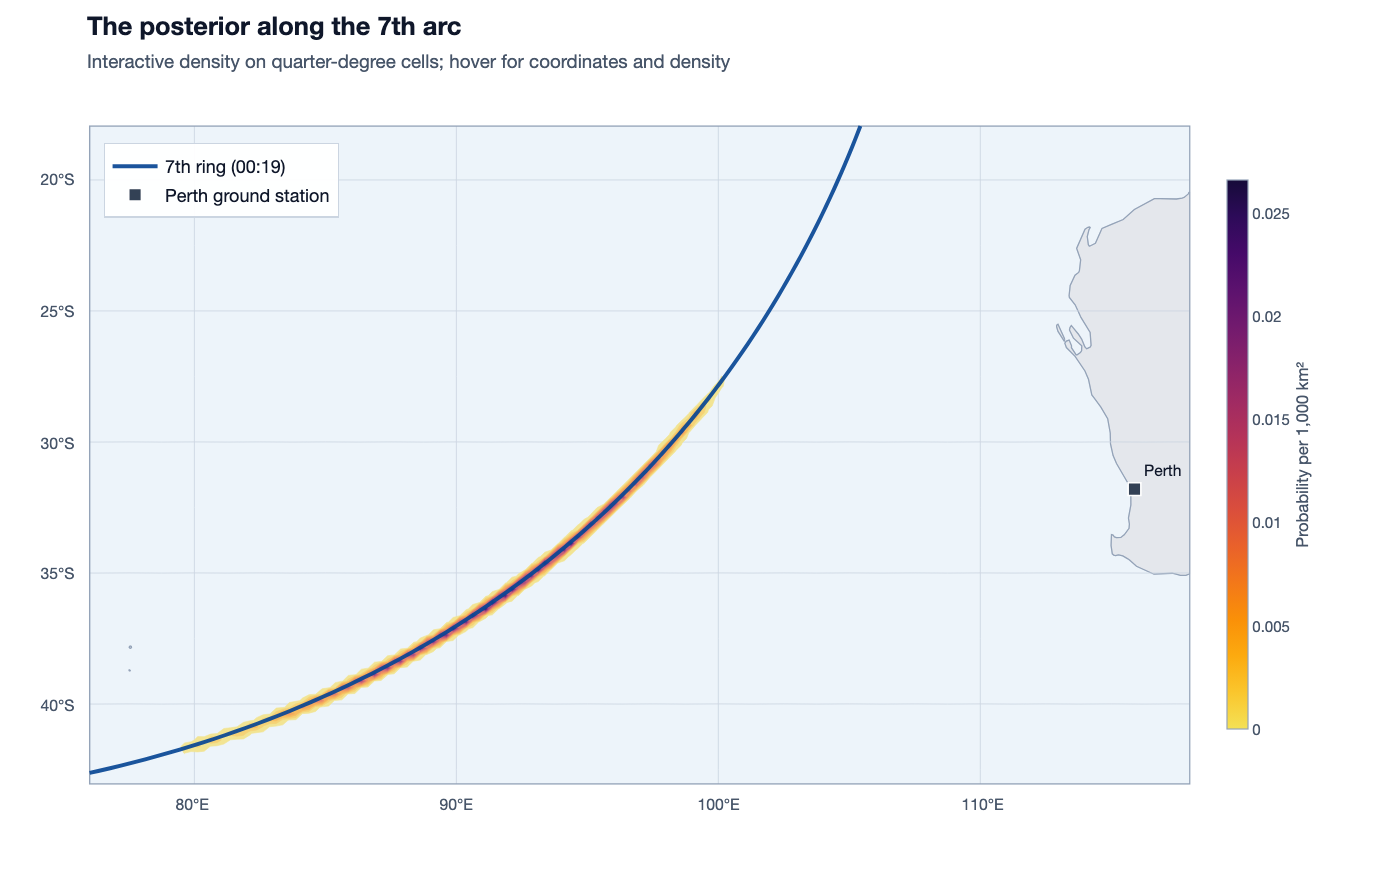

In [60]:
map_lat_edges, map_lon_edges = extent_edges(ARC_GRID_EXTENT, MAP_CELL_DEG)
_, map_density = posterior_grid(
    final_p[:, LAT], final_p[:, LON], final_w, map_lat_edges, map_lon_edges
)
fig = make_plotly_map(
    "seventh_arc",
    title="The posterior along the 7th arc",
    subtitle="Interactive density on quarter-degree cells; hover for coordinates and density",
)
add_plotly_density(
    fig, map_lat_edges, map_lon_edges, 1e3 * map_density, "Probability per 1,000 km²"
)
add_plotly_ring(fig, *rings[-1], emphasis=True, label="7th ring (00:19)")
add_plotly_places(fig, [perth_place])
fig.show()

### 7.2 Where along the arc?

The posterior is essentially one-dimensional: about 7 km across the arc (one standard deviation, printed below), more than a thousand kilometres along it. The latitude of the crossing point summarises it well, and the length of arc between two latitudes converts it into a search distance. Across the arc, the BTO residual at ping 7 times the ground distance per microsecond gives the width.

In [61]:
SUBSAT7_LON = subsatellite_point(SAT_ECEF_KM[-1])[1]


def arc_segment(lat_south, lat_north, offset_us=0.0):
    """Eastern branch of the 7th ring (BTO shifted by offset_us) between two latitudes, S to N."""
    lat, lon = bto_ring(PING_BTO_US[-1] + offset_us, SAT_ECEF_KM[-1], n_points=ARC_POINTS)
    keep = (lat >= lat_south) & (lat <= lat_north) & (lon > SUBSAT7_LON)
    order = np.argsort(lat[keep])
    return lat[keep][order], lon[keep][order]


def path_length_km(lat, lon):
    """Length of a polyline made of great-circle segments."""
    return great_circle_km(lat[:-1], lon[:-1], lat[1:], lon[1:]).sum()


# Width across the arc: ping-7 residuals converted to ground distance (Ping 1's band construction).
centre7, _, _, half_width7 = ring_band(N_PINGS - 1, PING_BTO_SD_US[-1])
southern7 = (centre7[0] < 0) & (centre7[1] > SUBSAT7_LON)
km_per_us = np.median(half_width7[southern7]) / PING_BTO_SD_US[-1]
residual7 = PING_BTO_US[-1] - predicted_bto(final_p[:, LAT], final_p[:, LON], SAT_ECEF_KM[-1])
across_sd_km = km_per_us * np.sqrt(np.sum(final_w * (residual7 - np.sum(final_w * residual7)) ** 2))
print(
    f"Across the arc: 1 µs of BTO = {km_per_us:.3f} km on the ground;"
    f" posterior sd {across_sd_km:.1f} km"
)

lat_quantiles = weighted_quantile(
    final_p[:, LAT], final_w, [0.025, 0.05, 0.25, 0.5, 0.75, 0.95, 0.975]
)
lat_mean = np.sum(final_w * final_p[:, LAT])
lat_sd = np.sqrt(np.sum(final_w * (final_p[:, LAT] - lat_mean) ** 2))
print(
    f"Posterior mean latitude {lat_mean:.2f} deg, sd {lat_sd:.2f} deg,"
    f" median {lat_quantiles[3]:.2f} deg"
)
for level, (lo, hi) in zip(CREDIBLE_LEVELS, [(2, 4), (1, 5), (0, 6)], strict=True):
    arc_km = path_length_km(*arc_segment(lat_quantiles[lo], lat_quantiles[hi]))
    print(
        f"{level:.0%} central interval: [{lat_quantiles[lo]:.2f}, {lat_quantiles[hi]:.2f}] deg,"
        f" {arc_km:,.0f} km of arc"
    )

Across the arc: 1 µs of BTO = 0.192 km on the ground; posterior sd 6.8 km
Posterior mean latitude -35.52 deg, sd 3.17 deg, median -35.75 deg
50% central interval: [-38.04, -33.16] deg, 816 km of arc
90% central interval: [-40.34, -30.05] deg, 1,756 km of arc
95% central interval: [-40.90, -29.37] deg, 1,996 km of arc


### 7.3 Monte Carlo error versus posterior uncertainty

Two very different uncertainties hide behind these numbers.

- **Posterior uncertainty** is the spread of $p(\varphi_7 \mid z_{1:7})$: what the data cannot tell us about the aircraft. It is a property of the problem, and it does not shrink when we add particles.
- **Monte Carlo error** is the error of our *estimate* of a posterior summary, such as the posterior mean latitude, caused by using finitely many particles. It shrinks like $1/\sqrt{N}$.

For independent samples the CLT of Ping 1 would give the standard error $\hat\sigma/\sqrt{N}$. A particle filter's samples are weighted and, after resampling, correlated, so even the natural fix $\hat\sigma/\sqrt{\mathrm{ESS}}$ is only a heuristic: it ignores the correlations that resampling creates across pings. The honest measure is to **re-run the whole filter with independent random streams** and look at the spread of the answers.

In [62]:
t_start = time.perf_counter()
seed_runs = [run_filter(PING_BTO_US, make_rng(7, r)) for r in range(SEED_RUNS)]
seed_runs_s = time.perf_counter() - t_start
seed_means = np.array([np.sum(r.weights * r.particles[:, LAT]) for r in seed_runs])
seed_quantiles = np.array(
    [weighted_quantile(r.particles[:, LAT], r.weights, [0.05, 0.5, 0.95]) for r in seed_runs]
)
seed_medians = seed_quantiles[:, 1]
mc_se_replicated = seed_means.std(ddof=1)
mc_se_heuristic = lat_sd / np.sqrt(main_run.ess[-1])
print(f"Posterior sd of the latitude (uncertainty about the aircraft): {lat_sd:.2f} deg")
print(
    f"Monte Carlo error of the posterior mean, from {SEED_RUNS} independent runs:"
    f" {mc_se_replicated:.3f} deg"
)
print(
    f"Heuristic sd / sqrt(ESS) with the final ESS ({main_run.ess[-1]:,.0f}):"
    f" {mc_se_heuristic:.3f} deg"
)
mc_sd_q05, mc_sd_median, mc_sd_q95 = seed_quantiles.std(axis=0, ddof=1)
# A single cell versus a region, across the independent runs
seed_grids = [
    posterior_grid(
        r.particles[:, LAT], r.particles[:, LON], r.weights, arc_lat_edges, arc_lon_edges
    )
    for r in seed_runs
]
seed_top_cells = [np.unravel_index(np.argmax(density), density.shape) for _, density in seed_grids]
seed_top_probs = np.array(
    [mass[cell] for (mass, _), cell in zip(seed_grids, seed_top_cells, strict=True)]
)
same_top = np.mean([cell == top_cell for cell in seed_top_cells])
hpd50_cells = final_density >= hpd_thresholds[CREDIBLE_LEVELS[0]]
hpd50_probs = np.array([mass[hpd50_cells].sum() for mass, _ in seed_grids])
print(
    f"Monte Carlo sd of the 5% quantile, median and 95% quantile:"
    f" {mc_sd_q05:.2f}, {mc_sd_median:.2f}, {mc_sd_q95:.2f} deg"
)
print(f"Posterior uncertainty / Monte Carlo error = {lat_sd / mc_se_replicated:.0f}")
top_mean, top_sd = seed_top_probs.mean(), seed_top_probs.std(ddof=1)
print(
    f"Top cell of the main run is also the top cell in {same_top:.0%} of the runs;"
    f" top-cell probability {top_mean:.1%} ± {top_sd:.1%} (mean ± sd)"
)
print(
    f"Probability of the main run's 50% HPD region, across runs: {hpd50_probs.mean():.1%}"
    f" ± {hpd50_probs.std(ddof=1):.1%}"
)

Posterior sd of the latitude (uncertainty about the aircraft): 3.17 deg
Monte Carlo error of the posterior mean, from 30 independent runs: 0.157 deg
Heuristic sd / sqrt(ESS) with the final ESS (91,688): 0.010 deg
Monte Carlo sd of the 5% quantile, median and 95% quantile: 0.11, 0.23, 0.20 deg
Posterior uncertainty / Monte Carlo error = 20
Top cell of the main run is also the top cell in 57% of the runs; top-cell probability 4.0% ± 0.3% (mean ± sd)
Probability of the main run's 50% HPD region, across runs: 50.0% ± 1.4%


In [63]:
print_card(
    "Ping 7.3, Monte Carlo error from independent re-runs",
    simulated="the filter of Ping 6 re-run on the same real data with independent random streams",
    size=f"{SEED_RUNS} runs × {N_PARTICLES:,} particles",
    settings=f"baseline assumptions; streams make_rng(7, r) for r = 0 to {SEED_RUNS - 1}",
    seconds=seed_runs_s,
    result=f"Monte Carlo error of the posterior mean latitude {mc_se_replicated:.3f} deg, against"
    f" a posterior sd of {lat_sd:.2f} deg; the main run's 50% HPD region holds"
    f" {hpd50_probs.mean():.1%} ± {hpd50_probs.std(ddof=1):.1%} of the probability across runs",
)

What we actually ran · Ping 7.3, Monte Carlo error from independent re-runs
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   the filter of Ping 6 re-run on the same real data with independent random streams
Size        30 runs × 100,000 particles
Settings    baseline assumptions; streams make_rng(7, r) for r = 0 to 29
Run time    17.20 s
Result      Monte Carlo error of the posterior mean latitude 0.157 deg, against a posterior sd
            of 3.17 deg; the main run's 50% HPD region holds 50.0% ± 1.4% of the probability
            across runs


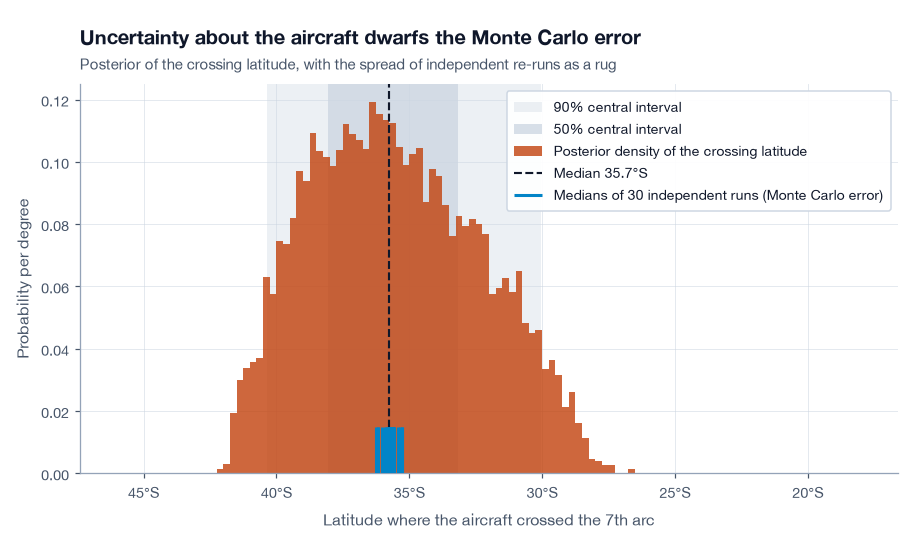

In [64]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for (lo, hi), shade, level in (((1, 5), 0.35, 0.9), ((2, 4), 0.75, 0.5)):
    ax.axvspan(
        lat_quantiles[lo],
        lat_quantiles[hi],
        color=COLOR_GRID,
        alpha=shade,
        lw=0,
        label=f"{level:.0%} central interval",
    )
ax.hist(
    final_p[:, LAT],
    bins=map_lat_edges,
    weights=final_w / MAP_CELL_DEG,
    color=COLOR_POSTERIOR,
    alpha=0.8,
    label="Posterior density of the crossing latitude",
)
ax.axvline(
    lat_quantiles[3], color=COLOR_TEXT, ls="--", lw=1.4, label=f"Median {-lat_quantiles[3]:.1f}°S"
)
rug_top = RUG_HEIGHT_FRACTION * ax.get_ylim()[1]
ax.vlines(
    seed_medians,
    0,
    rug_top,
    color=COLOR_PARTICLES,
    lw=2,
    zorder=5,
    label=f"Medians of {SEED_RUNS} independent runs (Monte Carlo error)",
)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: format_lat(v)))
ax.set_xlabel("Latitude where the aircraft crossed the 7th arc")
ax.set_ylabel("Probability per degree")
set_figure_header(
    ax,
    "Uncertainty about the aircraft dwarfs the Monte Carlo error",
    subtitle="Posterior of the crossing latitude, with the spread of independent re-runs as a rug",
)
style_legend(ax, loc="upper right")
plt.show()

> **Takeaway.** The medians of thirty independent runs fall within a few tenths of a degree of each other: a sliver at the foot of a posterior ten degrees wide.

Independent runs agree on the posterior mean to about 0.16° (one standard deviation) and on the median to about 0.2°, some twenty times less than the posterior spread: with $10^5$ particles, the computer is no longer the bottleneck. The heuristic $\hat\sigma/\sqrt{\mathrm{ESS}}$ is more than ten times too optimistic. The final ESS only measures the last reweighting; it cannot see the bottleneck at ping 2, where the whole cloud passed through about 1,600 effective particles (Ping 6). Independent replications are the honest error bar.

**A point or a region?** A single point has probability zero, so "where exactly is the aircraft?" has no answer; the right question is "how likely is it to be in this square?". The top half-degree cell of the main run, centred near 36.25°S, 91.25°E, holds only about 4% of the probability, and in many independent runs a neighbouring cell along the ridge comes out on top instead: which square wins is itself Monte Carlo noise, so the top of a long ridge is a fragile summary. The probability of a region, by contrast, is pinned down precisely: the main run's 50% HPD region holds 50.0% ± 1.4% of the probability across runs. A search plan should be built on regions, not on the top square.

---

## Epilogue A — How fragile?

> **In plain words**
>
> Every answer so far rests on assumptions, so we turn one knob at a time (how fast and how straight the aircraft flew, how noisy the measurements are, where and when the flight began its last leg, how the computer samples) and re-run the whole search after each change. The answer barely moves when the measurement noise or the computing recipe changes, but it shifts by up to about three degrees of latitude when the assumed way of flying changes, and for several of these choices the data cannot tell which is right. More computing power shrinks only the computer's own error, never this dependence on assumptions.

> **The obstacle.** Every number so far is conditional on our assumptions: how the aircraft flew, how noisy the BTO is, how we ran the algorithm. Which of them actually matter?

We change **one assumption at a time**, re-run the filter with the same number of particles, and record the median latitude of the crossing of the 7th arc and its 90% interval. The scenarios fall into two kinds of uncertainty:

| Family | Scenarios | Kind of uncertainty |
|---|---|---|
| Flight dynamics | speed bounds; triangular speed law (mode 470 kn); heading walk of 1°/√h (steady) or 15°/√h (agile) instead of 5°/√h | model: computation cannot reduce it |
| BTO noise | $\sigma$ halved and doubled; heavy-tailed Student-$t$ errors (3 degrees of freedom) with the same standard deviation | model |
| Start and turn | the conflicting radar fix; a turn within 30 minutes | model |
| Algorithm | ESS threshold; multinomial resampling; random seed; number of particles | Monte Carlo: more computation reduces it |

For every scenario we also print the filter's estimate of the log-evidence $\log p(z_{1:7} \mid \text{scenario})$ (Ping 5). Differences of log-evidence are log Bayes factors: they tell us which assumptions the data themselves can test.

In [65]:
MODEL_SCENARIOS = {
    "Speed 450–500 kn": ("dynamics", replace(BASELINE, speed_min_kn=450.0, speed_max_kn=500.0)),
    "Speed 350–550 kn": ("dynamics", replace(BASELINE, speed_min_kn=350.0, speed_max_kn=550.0)),
    "Triangular speed law": ("dynamics", replace(BASELINE, speed_mode_kn=470.0)),
    "Steady heading (1°/√h)": ("dynamics", replace(BASELINE, turn_walk_deg=1.0)),
    "Agile flight (15°/√h)": ("dynamics", replace(BASELINE, turn_walk_deg=15.0)),
    "BTO σ halved": ("noise", replace(BASELINE, bto_sd_scale=0.5)),
    "BTO σ doubled": ("noise", replace(BASELINE, bto_sd_scale=2.0)),
    "Student-t noise (3 dof)": ("noise", replace(BASELINE, bto_dof=3.0)),
    "Briefing-slide radar fix": (
        "start",
        replace(BASELINE, start_lat_deg=LIDO_FIX_LAT_DEG, start_lon_deg=LIDO_FIX_LON_DEG),
    ),
    "Turn within 30 min": ("start", replace(BASELINE, turn_delay_max_h=0.5)),
}
ALGORITHM_SCENARIOS = {
    "ESS threshold 0.1": {"ess_threshold": 0.1},
    "Resample at every ping": {"ess_threshold": 1.0},
    "Multinomial resampling": {"resample": multinomial_resample},
}


def latitude_summary(run):
    """Median, 5% and 95% quantiles of the final latitude, and the log-evidence of a run."""
    q05, q50, q95 = weighted_quantile(run.particles[:, LAT], run.weights, [0.05, 0.5, 0.95])
    return {"median": q50, "q05": q05, "q95": q95, "log_evidence": run.log_evidence[-1]}


t_start = time.perf_counter()
sensitivity = {"Baseline": ("baseline", latitude_summary(main_run))}
scenario_latitudes = {}  # final latitudes and weights per model scenario (small multiples)
for label, (family, model) in MODEL_SCENARIOS.items():  # same random stream: common random numbers
    run = run_filter(PING_BTO_US, make_rng(6), model)
    sensitivity[label] = (family, latitude_summary(run))
    scenario_latitudes[label] = (run.particles[:, LAT], run.weights)
for label, settings in ALGORITHM_SCENARIOS.items():
    sensitivity[label] = (
        "algorithm",
        latitude_summary(run_filter(PING_BTO_US, make_rng(6), **settings)),
    )
for r, run in enumerate(seed_runs[:SEEDS_SHOWN]):
    sensitivity[f"Random seed #{r + 1}"] = ("algorithm", latitude_summary(run))
scenarios_s = time.perf_counter() - t_start
print(f"{len(sensitivity) - 1} scenarios in {scenarios_s:.0f} s\n")

base = sensitivity["Baseline"][1]
label_width = max(map(len, sensitivity))
print(
    f"{'scenario':{label_width}s} {'family':>9s}  median  shift"
    "   90% interval     width  delta log-evidence"
)
for label, (family, s) in sensitivity.items():
    print(
        f"{label:{label_width}s} {family:>9s}  {s['median']:6.2f}"
        f"  {s['median'] - base['median']:+5.2f}"
        f"  [{s['q05']:6.2f}, {s['q95']:6.2f}]  {s['q95'] - s['q05']:5.2f}"
        f"  {s['log_evidence'] - base['log_evidence']:+7.1f}"
    )

16 scenarios in 7 s

scenario                    family  median  shift   90% interval     width  delta log-evidence
Baseline                  baseline  -35.75  +0.00  [-40.34, -30.05]  10.29     +0.0
Speed 450–500 kn          dynamics  -37.41  -1.66  [-39.61, -34.84]   4.76     +0.2
Speed 350–550 kn          dynamics  -35.88  -0.13  [-40.81, -28.88]  11.93     -0.3
Triangular speed law      dynamics  -36.12  -0.37  [-39.77, -31.32]   8.46     +0.1
Steady heading (1°/√h)    dynamics  -37.91  -2.16  [-39.83, -35.35]   4.48     -0.2
Agile flight (15°/√h)     dynamics  -32.88  +2.86  [-39.78, -27.68]  12.10     -3.1
BTO σ halved                 noise  -35.84  -0.09  [-40.26, -30.00]  10.26     +0.9
BTO σ doubled                noise  -35.70  +0.05  [-40.53, -29.80]  10.74     -1.5
Student-t noise (3 dof)      noise  -36.11  -0.37  [-40.29, -30.17]  10.13     +0.5
Briefing-slide radar fix     start  -37.39  -1.65  [-40.65, -31.42]   9.23    -27.3
Turn within 30 min           start  -35.72  

In [66]:
MODEL_FAMILIES = ("dynamics", "noise", "start")  # the assumption families of MODEL_SCENARIOS
shift = {label: s["median"] - base["median"] for label, (family, s) in sensitivity.items()}
model_labels = [label for label, (family, _) in sensitivity.items() if family in MODEL_FAMILIES]
algorithm_labels = [label for label, (family, _) in sensitivity.items() if family == "algorithm"]
top_model = max(model_labels, key=lambda label: abs(shift[label]))
top_algorithm = max(algorithm_labels, key=lambda label: abs(shift[label]))
print_card(
    "Epilogue A, one assumption at a time",
    simulated="the filter re-run on the real data with one modelling assumption or one algorithm"
    " setting changed",
    size=f"{len(MODEL_SCENARIOS)} model and {len(ALGORITHM_SCENARIOS)} algorithm scenarios ×"
    f" {N_PARTICLES:,} particles, plus {SEEDS_SHOWN} re-runs from Ping 7.3",
    settings="common random numbers: every scenario uses stream make_rng(6), like the main run",
    seconds=scenarios_s,
    result=f"largest shift of the median: {shift[top_model]:+.2f} deg for a model assumption"
    f" ({top_model.split(' (')[0]}), {shift[top_algorithm]:+.2f} deg for an algorithm setting"
    f" ({top_algorithm})",
)

What we actually ran · Epilogue A, one assumption at a time
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   the filter re-run on the real data with one modelling assumption or one algorithm
            setting changed
Size        10 model and 3 algorithm scenarios × 100,000 particles, plus 3 re-runs from Ping 7.3
Settings    common random numbers: every scenario uses stream make_rng(6), like the main run
Run time    7.44 s
Result      largest shift of the median: +2.86 deg for a model assumption (Agile flight), +0.14
            deg for an algorithm setting (Random seed #1)


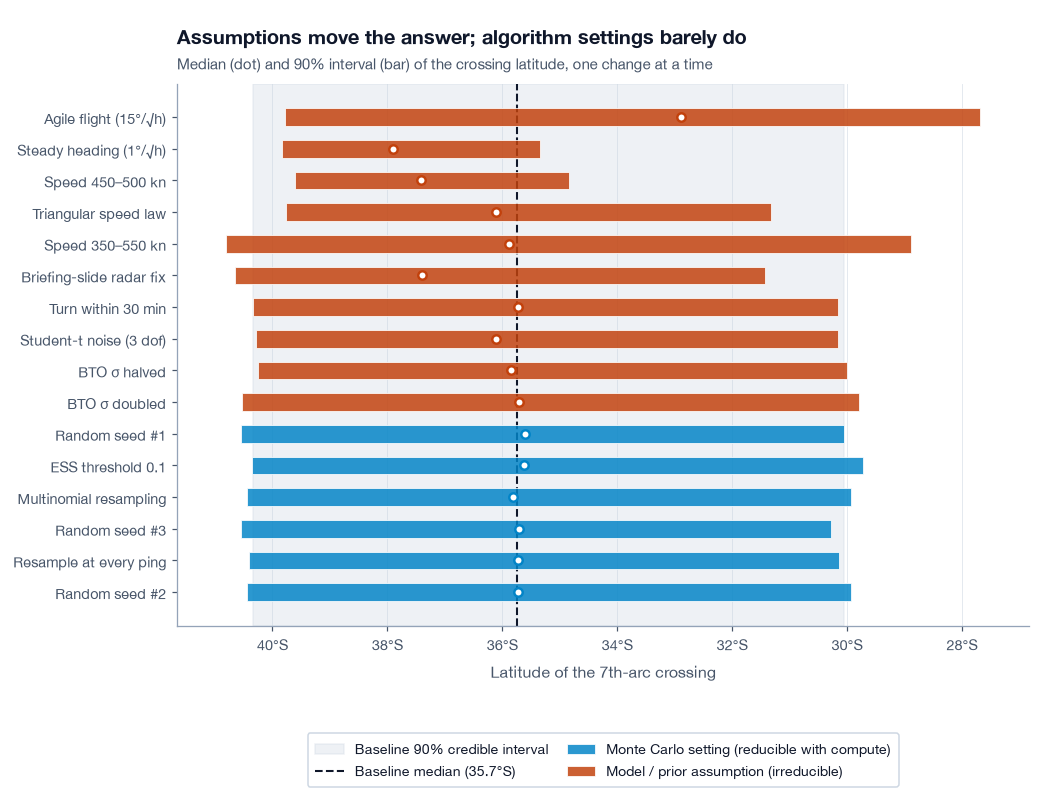

In [67]:
family_order = {"algorithm": 0, "noise": 1, "start": 2, "dynamics": 3}  # bottom to top of the chart
tornado = sorted(
    (
        {
            "name": label,
            "low": s["q05"],
            "high": s["q95"],
            "center": s["median"],
            "category": "mc" if family == "algorithm" else "model",
        }
        for label, (family, s) in sensitivity.items()
        if family != "baseline"
    ),
    key=lambda item: (
        family_order[sensitivity[item["name"]][0]],
        abs(item["center"] - base["median"]),
    ),
)
fig, ax = plot_tornado(
    tornado,
    baseline_value=base["median"],
    baseline_interval=(base["q05"], base["q95"]),
    sort_by_span=False,
    xlabel="Latitude of the 7th-arc crossing",
    figsize=FIGSIZE_HERO,
    title="Assumptions move the answer; algorithm settings barely do",
    subtitle="Median (dot) and 90% interval (bar) of the crossing latitude, one change at a time",
)
plt.show()

> **Takeaway.** Every row whose median moves by more than about half a degree is a flight-dynamics or start assumption; the algorithm rows all sit on the dashed baseline.

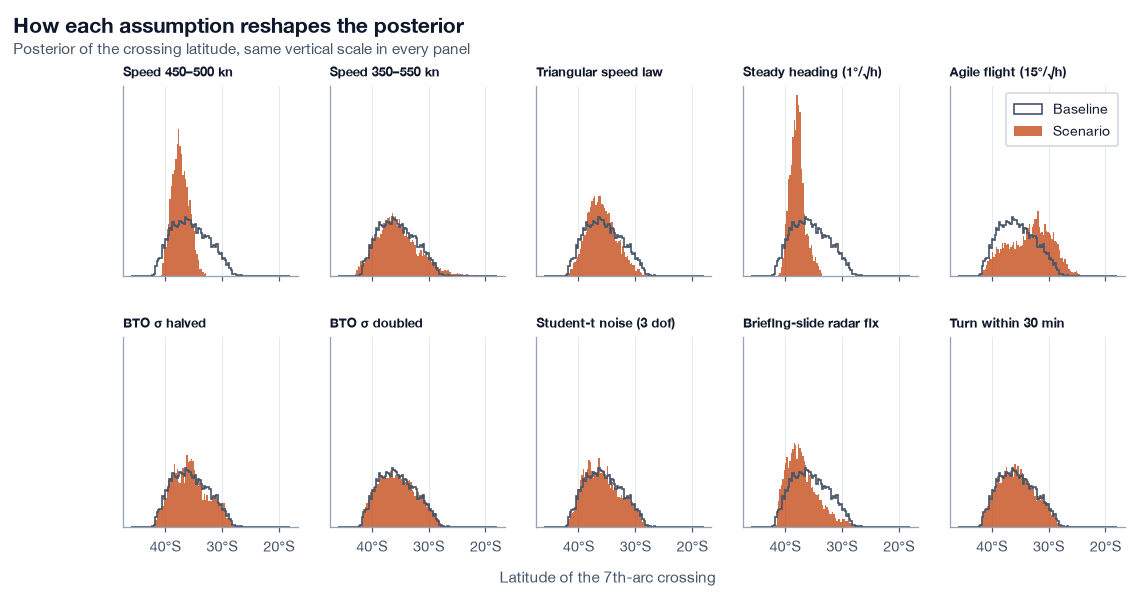

In [68]:
fig, axes = make_small_multiples(
    len(scenario_latitudes),
    ncols=SMALL_MULTIPLE_COLUMNS,
    panel_size=SMALL_MULTIPLE_PANEL_IN,
    title="How each assumption reshapes the posterior",
    subtitle="Posterior of the crossing latitude, same vertical scale in every panel",
)
for ax, (label, (lat, w)) in zip(axes, scenario_latitudes.items(), strict=False):
    ax.hist(
        final_p[:, LAT],
        bins=map_lat_edges,
        weights=final_w,
        histtype="step",
        color=COLOR_TEXT_MUTED,
        lw=1.1,
        label="Baseline",
    )
    ax.hist(lat, bins=map_lat_edges, weights=w, color=COLOR_POSTERIOR, alpha=0.75, label="Scenario")
    ax.set_title(label, loc="left", fontsize=8.6, fontweight="bold", color=COLOR_TEXT)
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: format_lat(v)))
fig.supxlabel("Latitude of the 7th-arc crossing", fontsize=10, color=COLOR_TEXT_MUTED)
style_legend(
    axes[SMALL_MULTIPLE_COLUMNS - 1], loc="upper right"
)  # top-right panel: empty upper right
plt.show()

> **Takeaway.** Assumptions on speed and turning reshape the whole posterior, not just its centre, whereas the noise variants are almost indistinguishable from the baseline.

Three groups emerge, and they are very different in size.

- **Algorithm settings** (ESS threshold, resampling scheme, random seed) move the median by a few tenths of a degree at most: Monte Carlo noise, of the same size as the spread of the independent runs in Ping 7.
- **The noise model** barely matters: halving, doubling or fattening the tails of the BTO errors moves the median by at most 0.4°, comparable to the Monte Carlo noise of the median (standard deviation about 0.2°, Ping 7). The noise sets the width of the cloud across the arc, not its position along it.
- **The flight dynamics** dominate. A narrower speed prior or a steady heading pushes the median about 2° south and more than halves the interval; agile flight pulls it almost 3° north.

The log-evidence adds a twist. The data cannot tell the speed priors apart (differences well below one unit of log-evidence), so a choice that moves the answer by two degrees is not settled by the data at all. Agile flight is mildly disfavoured, by a Bayes factor of about $e^{3} \approx 20$. The radar fix of the briefing slide is rejected outright, by a factor of about $e^{27}$, even though the posterior it produces looks perfectly plausible: a good-looking answer is no evidence for the assumption that produced it. The next cell shows why the data object.

In [69]:
lido_residual = (
    PING_BTO_US[0] - predicted_bto(LIDO_FIX_LAT_DEG, LIDO_FIX_LON_DEG, SAT_ECEF_KM[0])
) / PING_BTO_SD_US[0]
lido_gap_km = great_circle_km(LIDO_FIX_LAT_DEG, LIDO_FIX_LON_DEG, ring1_lat, ring1_lon).min()
lido_speed_kn = lido_gap_km / (KNOT_KMH * T_PING_H[0])
print(
    f"Briefing-slide fix: ring-1 residual {lido_residual:+.1f} sigma,"
    f" {lido_gap_km:.0f} km from ring 1"
)
print(
    f"Reaching ring 1 in {60 * T_PING_H[0]:.1f} min would take at least {lido_speed_kn:,.0f} knots"
)

Briefing-slide fix: ring-1 residual -10.5 sigma, 159 km from ring 1
Reaching ring 1 in 3.3 min would take at least 1,582 knots


### Monte Carlo error is bought with computation; model uncertainty is not

The last test varies the number of particles $N$ over three orders of magnitude, with several independent runs per value. Two curves should behave very differently: the Monte Carlo error of the posterior mean (the spread across runs) must fall like $1/\sqrt{N}$, while the posterior standard deviation (our uncertainty about the aircraft) must not move.

In [70]:
t_start = time.perf_counter()
n_sweep_runs = {
    n: [run_filter(PING_BTO_US, make_rng(8, n, r), n=n) for r in range(reps)]
    for n, reps in N_SWEEP_EXTRA.items()
}
n_sweep_runs[N_PARTICLES] = seed_runs  # the independent runs of Ping 7 serve for N = N_PARTICLES
n_values = np.array(sorted(n_sweep_runs))
sweep_mean = {
    n: np.array([np.sum(r.weights * r.particles[:, LAT]) for r in runs])
    for n, runs in n_sweep_runs.items()
}
sweep_sd = {
    n: np.array(
        [
            np.sqrt(np.sum(r.weights * (r.particles[:, LAT] - m) ** 2))
            for r, m in zip(runs, sweep_mean[n], strict=True)
        ]
    )
    for n, runs in n_sweep_runs.items()
}
mc_error = np.array([sweep_mean[n].std(ddof=1) for n in n_values])
runs_per_n = np.array([len(n_sweep_runs[n]) for n in n_values])
# 95% confidence interval of a sd estimated from r runs, using (r-1) s^2 / sigma^2 ~ chi2(r-1)
mc_error_low = mc_error * np.sqrt((runs_per_n - 1) / chi2.ppf(0.975, runs_per_n - 1))
mc_error_high = mc_error * np.sqrt((runs_per_n - 1) / chi2.ppf(0.025, runs_per_n - 1))
posterior_sd = np.array([sweep_sd[n].mean() for n in n_values])
model_spread = np.ptp(
    [s["median"] for family, s in sensitivity.values() if family in ("dynamics", "baseline")]
)
sweep_slope = np.polyfit(np.log(n_values), np.log(mc_error), 1)[0]
sweep_s = time.perf_counter() - t_start
print(f"{sum(N_SWEEP_EXTRA.values())} extra runs in {sweep_s:.0f} s")
print("        N   runs   MC error of the mean (deg)   95% CI             posterior sd (deg)")
for n, r, err, lo, hi, sd in zip(
    n_values, runs_per_n, mc_error, mc_error_low, mc_error_high, posterior_sd, strict=True
):
    print(f"{n:9,d}   {r:4d}   {err:26.3f}   [{lo:.3f}, {hi:.3f}]   {sd:18.2f}")
print(f"Fitted slope of the Monte Carlo error: {sweep_slope:.2f} (theory -0.5)")
print(f"Range of the median across flight-dynamics assumptions: {model_spread:.1f} deg")

60 extra runs in 71 s
        N   runs   MC error of the mean (deg)   95% CI             posterior sd (deg)
    1,000     32                        1.429   [1.146, 1.900]                 2.87
   10,000     16                        0.495   [0.366, 0.767]                 3.16
  100,000     30                        0.157   [0.125, 0.211]                 3.17
1,000,000     12                        0.048   [0.034, 0.082]                 3.18
Fitted slope of the Monte Carlo error: -0.49 (theory -0.5)
Range of the median across flight-dynamics assumptions: 5.0 deg


In [71]:
print_card(
    "Epilogue A, Monte Carlo error against the number of particles",
    simulated=f"the filter re-run on the real data with N from {n_values[0]:,} to"
    f" {n_values[-1]:,} particles",
    size=", ".join(f"{r} runs at N = {n:,}" for n, r in zip(n_values, runs_per_n, strict=True)),
    settings=f"streams make_rng(8, N, r); the {SEED_RUNS} runs at N = {N_PARTICLES:,} are those"
    " of Ping 7.3",
    seconds=sweep_s,
    result=f"fitted slope of the Monte Carlo error {sweep_slope:.2f} (theory -0.5); posterior sd"
    f" from {posterior_sd[0]:.2f} to {posterior_sd[-1]:.2f} deg; spread across flight-dynamics"
    f" assumptions {model_spread:.1f} deg",
)

What we actually ran · Epilogue A, Monte Carlo error against the number of particles
────────────────────────────────────────────────────────────────────────────────────────────────
Simulated   the filter re-run on the real data with N from 1,000 to 1,000,000 particles
Size        32 runs at N = 1,000, 16 runs at N = 10,000, 30 runs at N = 100,000, 12 runs at N =
            1,000,000
Settings    streams make_rng(8, N, r); the 30 runs at N = 100,000 are those of Ping 7.3
Run time    71.33 s
Result      fitted slope of the Monte Carlo error -0.49 (theory -0.5); posterior sd from 2.87 to
            3.18 deg; spread across flight-dynamics assumptions 5.0 deg


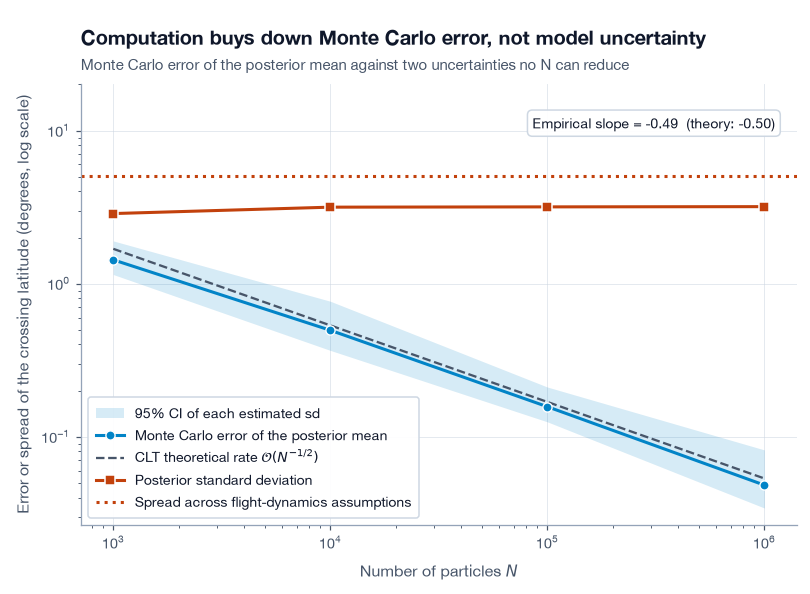

In [72]:
fig, ax = plot_loglog_convergence(
    n_values,
    mc_error,
    error_low=mc_error_low,
    error_high=mc_error_high,
    band_label="95% CI of each estimated sd",
    empirical_slope=sweep_slope,
    xlabel="Number of particles $N$",
    label="Monte Carlo error of the posterior mean",
    ylabel="Error or spread of the crossing latitude (degrees, log scale)",
    title="Computation buys down Monte Carlo error, not model uncertainty",
    subtitle="Monte Carlo error of the posterior mean against two uncertainties no N can reduce",
)
ax.plot(
    n_values,
    posterior_sd,
    color=COLOR_POSTERIOR,
    marker="s",
    ms=6,
    mec=COLOR_BG,
    lw=2,
    label="Posterior standard deviation",
)
ax.axhline(
    model_spread,
    color=COLOR_POSTERIOR,
    ls=":",
    lw=2,
    label="Spread across flight-dynamics assumptions",
)
ax.set_ylim(top=CLOSING_AXIS_HEADROOM * model_spread)
style_legend(ax, loc="lower left")
plt.show()

> **Takeaway.** A thousand times more particles shrink the Monte Carlo error by well over an order of magnitude, while the posterior spread (once $N \ge 10^4$) and the disagreement between plausible models barely move.

The Monte Carlo error falls by a factor of about $\sqrt{10} \approx 3.2$ per decade of $N$ (fitted slope $-0.49$), as the CLT promised in Ping 1; each point rests on 12 to 32 independent runs, so its own uncertainty is the shaded band. The posterior standard deviation does not move once $N$ is large enough; with only $10^3$ particles it is even *underestimated*: too few particles do not just add noise, they make the posterior look narrower than it is. Meanwhile the spread of the median across flight-dynamics assumptions does not depend on $N$ at all.

**Monte Carlo error is bought down with computation; model uncertainty is not.**

---

## Epilogue B — Reality check

> **In plain words**
>
> Like checking a treasure map against the ground already dug, we lay our probability map over the strips of ocean actually searched, rebuilt from their published dimensions. Most of our probability falls inside the searched stretches of the seventh ring, yet the aircraft was not found, and the debris that washed ashore thousands of kilometres to the west records where ocean currents carried it, not where it sank. We close with what this simplified model cannot see and with the answers to our three questions.

> **The obstacle.** A probability map is only useful if it survives contact with reality. What did the real search do, and what has the ocean returned?

### Our map against the real searches

The official searches were strips along the 7th arc. We rebuild each one between its documented latitudes: a strip is the set of points whose BTO at 00:19 lies within $\pm\Delta$ of the measured value, with $\Delta$ chosen so that the strip has the documented half-width on the ground. For the Ocean Infinity search only the area is published, so its mean half-width is the area divided by twice the length of the arc segment.

In [73]:
# Strips of the documented half-width, using the ground distance per µs of BTO from Ping 7.

search_strips = {}
for name, (lat_s, lat_n, half_width_km, area_km2) in SEARCH_AREAS.items():
    if half_width_km is None:
        half_width_km = area_km2 / (2 * path_length_km(*arc_segment(lat_s, lat_n)))
    inner, outer = (arc_segment(lat_s, lat_n, s * half_width_km / km_per_us) for s in (-1, 1))
    search_strips[name] = (np.r_[inner[0], outer[0][::-1]], np.r_[inner[1], outer[1][::-1]])
    mass = final_w[(final_p[:, LAT] >= lat_s) & (final_p[:, LAT] <= lat_n)].sum()
    mass_runs = [
        r.weights[(r.particles[:, LAT] >= lat_s) & (r.particles[:, LAT] <= lat_n)].sum()
        for r in seed_runs
    ]
    print(
        f"{name:31s} {lat_s:6.1f} to {lat_n:6.1f} deg, half-width {half_width_km:3.0f} km:"
        f" our posterior probability {mass:.0%} (Monte Carlo sd {np.std(mass_runs, ddof=1):.1%})"
    )

searched = np.zeros(len(final_w), dtype=bool)
for lat_s, lat_n, _, _ in SEARCH_AREAS.values():
    searched |= (final_p[:, LAT] >= lat_s) & (final_p[:, LAT] <= lat_n)
dstg_lon = np.interp(DSTG_PEAK_LAT_DEG, *arc_segment(-90.0, 0.0))
print(
    "Probability of a crossing outside every searched band of latitude:"
    f" {1 - final_w[searched].sum():.0%}"
)
sea_level_ring = bto_ring(PING_BTO_US[-1], SAT_ECEF_KM[-1], alt_km=0.0)
altitude_shift_km = np.median(great_circle_km(*sea_level_ring, *rings[-1])[southern7])
print(f"The 7th ring at sea level lies {altitude_shift_km:.1f} km from the ring at cruise altitude")
print(
    f"DSTG peak placed on our arc at ({DSTG_PEAK_LAT_DEG}, {dstg_lon:.2f});"
    f" {final_w[final_p[:, LAT] < DSTG_PEAK_LAT_DEG].sum():.0%} of our posterior lies south of it"
)

ATSB underwater search 2014-17   -39.3 to  -33.0 deg, half-width  40 km: our posterior probability 64% (Monte Carlo sd 1.8%)
First Principles Review area     -36.0 to  -33.0 deg, half-width  46 km: our posterior probability 29% (Monte Carlo sd 2.0%)
Ocean Infinity search 2018       -36.0 to  -25.0 deg, half-width  36 km: our posterior probability 53% (Monte Carlo sd 2.6%)
Probability of a crossing outside every searched band of latitude: 12%
The 7th ring at sea level lies 8.6 km from the ring at cruise altitude
DSTG peak placed on our arc at (-38.2, 88.00); 23% of our posterior lies south of it


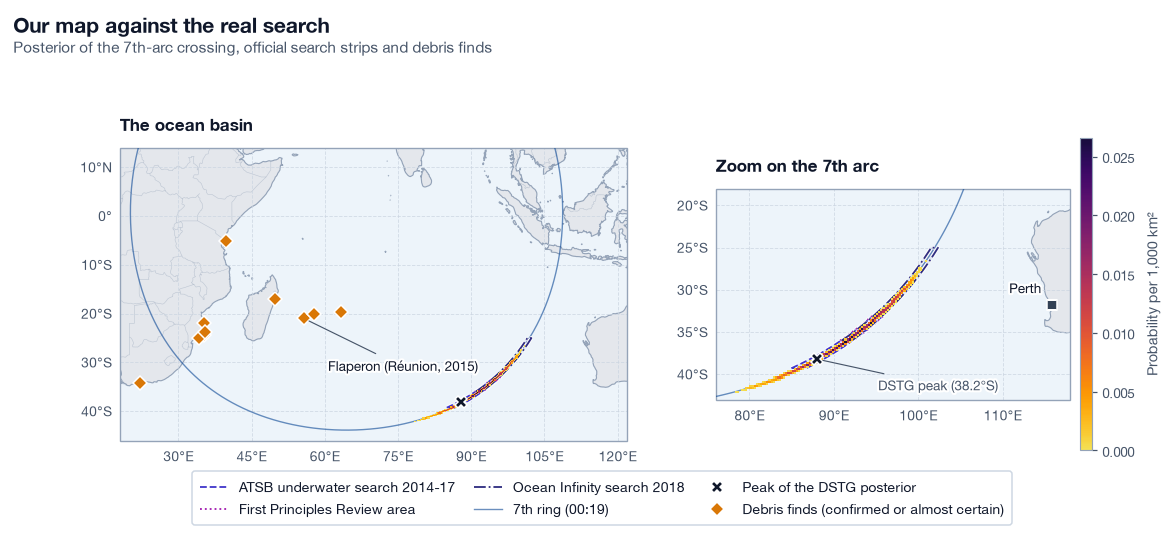

In [74]:
dstg_place = {
    "name": "DSTG peak (38.2°S)",
    "lat": DSTG_PEAK_LAT_DEG,
    "lon": dstg_lon,
    "marker": "X",
    "color": COLOR_TEXT,
    "markersize": 8.5,
    "offset": (40, -12),
    "arrow": True,
    "legend_label": "Peak of the DSTG posterior",
}
debris_places = [
    {
        "name": "Flaperon (Réunion, 2015)" if i == 0 else "",
        "lat": lat,
        "lon": lon,
        "role": "debris",
        "offset": (16, -26),
        "arrow": True,
        "legend_label": "Debris finds (confirmed or almost certain)",
    }
    for i, (_, _, lat, lon) in enumerate(DEBRIS_FINDS)
]
fig, axes = plt.subplots(
    1,
    2,
    figsize=FIGSIZE_TWO_PANEL,
    subplot_kw={"projection": ccrs.PlateCarree()},
    gridspec_kw={"width_ratios": REALITY_PANEL_RATIOS},
)
panels = (
    (BASIN_EXTENT, "The ocean basin", [{**dstg_place, "show_text": False}, *debris_places]),
    ("seventh_arc", "Zoom on the 7th arc", [dstg_place, perth_place]),
)
for ax, (extent, title, places) in zip(axes, panels, strict=True):
    make_cartopy_map(extent, ax=ax)
    for (name, (lat, lon)), color, style in zip(
        search_strips.items(), SEARCH_AREA_COLORS, SEARCH_AREA_STYLES, strict=True
    ):
        draw_search_area(ax, lat, lon, label=name, color=color, ls=style, lw=1.2, fill_alpha=0.05)
    draw_density(
        ax,
        map_lat_edges,
        map_lon_edges,
        1e3 * map_density,
        "Probability per 1,000 km²",
        add_colorbar=extent == "seventh_arc",
        zorder=DENSITY_OVER_STRIPS_ZORDER,
    )
    draw_ring(ax, *rings[-1], emphasis=True, label="7th ring (00:19)", lw=0.9, alpha=0.6)
    annotate_places(ax, places)
    set_figure_header(ax, title)
style_legend(axes[0], loc="below", ncol=3, bbox_to_anchor=REALITY_LEGEND_ANCHOR)
set_suptitle_header(
    fig,
    "Our map against the real search",
    subtitle="Posterior of the 7th-arc crossing, official search strips and debris finds",
)
plt.show()

> **Takeaway.** The searched strips cover most of our posterior ridge, from 39.3°S to 25°S, yet the aircraft was not found; the debris, thousands of kilometres west, record where the ocean carried the wreckage, not where it sank.

Our posterior puts most of its probability inside the latitude bands that were searched, about two thirds in the ATSB band alone (Monte Carlo sd about 2 points), and only a small remainder outside every band. Yet the aircraft was not found [4, 7]. Three explanations, not mutually exclusive: the aircraft lies in the remaining probability; or it lies within the searched latitudes but beyond the searched width, since a long glide after fuel exhaustion would carry it away from the arc and our model stops at 00:19; or the search missed it. The DSTG posterior, built with the BFO and an autopilot-based prior, peaked at 38.2°S [5], near the southern edge of our 50% interval. Our BTO-only answer is wider, as expected with less data and a vaguer prior.

The debris washed ashore between 16 and 30 months later on the coasts of Africa and the islands of the western Indian Ocean, thousands of kilometres from the arc. Drift modelling, not attempted here, is what turned them into evidence for the 33°S to 36°S band of the First Principles Review [3].

### What this model cannot see

Each limit below refers to the assumptions table of section 0.3 (A1 to A13), which lists the measured effect of every assumption.

- **North or south (A1).** The southern route is an assumption imported from the BFO analysis [1, 6]. The BFO is not modelled, the BTO alone cannot exclude a northern path, and since our prior gives northern headings zero probability, so does the posterior: no amount of computation could bring a northern path back (Ping 3). No run of this notebook tests it: with zero prior probability, a northern path can never appear in the posterior.
- **Simplified flight dynamics (A3 to A7).** One final turn, then random walks on heading and speed. No autopilot modes (great circle, constant track, constant heading), no winds (we model ground speed directly), no fuel or endurance model, a fixed altitude. Epilogue A showed that these choices are exactly the ones that move the answer: the heading walk alone moves the median from 2.16° south to 2.86° north of the baseline, and a narrower speed prior moves it 1.66° south.
- **Measurement noise (A8, A9).** Independent Gaussian errors; the 20 µs quantisation of the logged BTO and any correlation between handshakes are ignored. Epilogue A suggests this matters little: halving, doubling or fattening the tails of the noise moves the median by at most 0.37°.
- **End of flight (A7, A11).** Our posterior is the crossing of the 7th arc at 00:19 at cruise altitude. The impact point lies within a glide or a dive of that crossing, and the altitude assumption alone shifts the arc by about 9 km (printed above).
- **Monte Carlo approximations.** The ESS dips to about 1% at the second ping, and path degeneracy means that static quantities, such as the time of the turn, are estimated from fewer than a thousand distinct ancestors. Metropolis moves after each resampling (resample-move [20], Ping 2.3) are the standard cure, not implemented here.
- **Calibration is conditional (A5, A8).** The Interlude showed that a wrong dynamics model destroys calibration while the filter looks just as confident: the 90% regions then contain the truth in only 37% of synthetic flights (76% when the noise, rather than the dynamics, is wrong). Nothing inside the filter raises an alarm.

### The answers

1. **Where?** The most probable zone, the smallest region holding half of the probability (50% HPD), runs along the 7th arc from about 39.5°S to 32°S, south-west of Australia; the posterior median crossing is at 35.7°S (Monte Carlo sd 0.2°). The top half-degree square of the main run, centred near 36.25°S, 91.25°E, holds only about 4% of the probability, and other runs crown neighbouring squares along the ridge.
2. **How sure?** The 90% credible interval spans 40.3°S to 30.1°S (Monte Carlo sd 0.1° to 0.2° on each bound), about 1,750 km of arc. The Monte Carlo error of the posterior mean is about 0.16° with $10^5$ particles, twenty times smaller than the posterior standard deviation of 3.2°: the uncertainty is about the aircraft, not about the computation.
3. **How fragile?** The answer moves by up to about 3° when the flight-dynamics assumptions change, by at most 0.4° when the noise model changes, and only by Monte Carlo noise when the algorithm changes. The data cannot tell the speed priors apart, so that part of the uncertainty is irreducible without new information.

**Monte Carlo error is bought down with computation. Model uncertainty is not.**

---

## References

**The case and the data**

1. C. Ashton, A. Shuster Bruce, G. Colledge, M. Dickinson (2015). *The search for MH370*. The Journal of Navigation 68(1), 1–22. [doi:10.1017/S037346331400068X](https://doi.org/10.1017/S037346331400068X)
2. Australian Transport Safety Bureau (2014, updated 2015). *MH370 – Definition of Underwater Search Areas*. [atsb.gov.au](https://www.atsb.gov.au/sites/default/files/media/5283151/mh370-definition-of-underwater-search-areas_1.pdf)
3. Australian Transport Safety Bureau (2016). *MH370 – First Principles Review*. [atsb.gov.au](https://www.atsb.gov.au/media/5772107/ae2014054_final-first-principles-report.pdf)
4. Australian Transport Safety Bureau (2017). *The Operational Search for MH370*. [atsb.gov.au](https://www.atsb.gov.au/sites/default/files/media/5773292/ae-2014-054_operational-search_for_mh370.pdf)
5. S. Davey, N. Gordon, I. Holland, M. Rutten, J. Williams (2016). *Bayesian Methods in the Search for MH370*. SpringerBriefs in Electrical and Computer Engineering, open access. [doi:10.1007/978-981-10-0379-0](https://doi.org/10.1007/978-981-10-0379-0)
6. I. D. Holland (2018). *MH370 Burst Frequency Offset Analysis and Implications on Descent Rate at End-of-Flight*. [arXiv:1702.02432](https://arxiv.org/abs/1702.02432)
7. Malaysian ICAO Annex 13 Safety Investigation Team for MH370 (2018). *Safety Investigation Report: Malaysia Airlines Boeing B777-200ER (9M-MRO)*. Ministry of Transport, Malaysia. [mot.gov.my](https://www.mot.gov.my/en/MH370%20Investigation%20Report/01-Report/MH370SafetyInvestigationReport.pdf)
8. Inmarsat, Department of Civil Aviation Malaysia (2014). *MH370 Data Communication Logs* (signalling-unit logs). [atsb.gov.au](https://www.atsb.gov.au/sites/default/files/media/5184180/public_mh370-data-communication-logs.pdf)

**The methods**

9. A. Kong (1992). *A note on importance sampling using standardized weights*. Technical Report 348, Department of Statistics, University of Chicago.
10. A. Kong, J. S. Liu, W. H. Wong (1994). *Sequential imputations and Bayesian missing data problems*. Journal of the American Statistical Association 89(425), 278–288.
11. N. J. Gordon, D. J. Salmond, A. F. M. Smith (1993). *Novel approach to nonlinear/non-Gaussian Bayesian state estimation*. IEE Proceedings F 140(2), 107–113.
12. R. Douc, O. Cappé, E. Moulines (2005). *Comparison of resampling schemes for particle filtering*. Proceedings of the 4th International Symposium on Image and Signal Processing and Analysis, 64–69.
13. P. Del Moral (2004). *Feynman-Kac Formulae: Genealogical and Interacting Particle Systems with Applications*. Springer.
14. S. R. Cook, A. Gelman, D. B. Rubin (2006). *Validation of software for Bayesian models using posterior quantiles*. Journal of Computational and Graphical Statistics 15(3), 675–692.
15. S. Talts, M. Betancourt, D. Simpson, A. Vehtari, A. Gelman (2018). *Validating Bayesian inference algorithms with simulation-based calibration*. [arXiv:1804.06788](https://arxiv.org/abs/1804.06788)
16. A. Doucet, A. M. Johansen (2011). *A tutorial on particle filtering and smoothing: fifteen years later*. In D. Crisan, B. Rozovskii (eds), The Oxford Handbook of Nonlinear Filtering, 656–704. Oxford University Press.
17. C. P. Robert, G. Casella (2004). *Monte Carlo Statistical Methods*, 2nd edition. Springer.
18. N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller, E. Teller (1953). *Equation of state calculations by fast computing machines*. The Journal of Chemical Physics 21(6), 1087–1092.
19. A. D. Sokal (1997). *Monte Carlo methods in statistical mechanics: foundations and new algorithms*. In C. DeWitt-Morette, P. Cartier, A. Folacci (eds), Functional Integration: Basics and Applications, 131–192. Springer.
20. W. R. Gilks, C. Berzuini (2001). *Following a moving target: Monte Carlo inference for dynamic Bayesian models*. Journal of the Royal Statistical Society B 63(1), 127–146.
21. C. Andrieu, A. Doucet, R. Holenstein (2010). *Particle Markov chain Monte Carlo methods*. Journal of the Royal Statistical Society B 72(3), 269–342.